# Phase 6B - Survival analysis: how long does a song stay on the chart, and what goes with a short stay?

**Project:** United States Top 50 Playlist Performance and Song Popularity Trend Analysis (Atlantic Recording Corporation case)

**What this notebook does.** Phase 6A asked how much of what happens to a new song can be told from what was known early. This notebook asks the question the chart poses most directly: *for how long?* Take the 894 songs that arrived on the chart after its first snapshot day (by 229 artists; the 50 songs that were already there on day one are left out, because we did not see them arrive). For each song, count the chart days of its first stay. Some stays are still going when the file ends (59 of 894); survival analysis is the family of methods built for exactly this: a stay that is still going is not thrown away and not treated as finished, it counts as "at least this long".

The notebook answers six questions, in this order. How many songs are still on the chart after 3, 7 and 30 chart days (Section 3)? Is the chance of leaving the same on every day (Section 3)? Which kinds of songs stay longer, and by how much (Section 4)? Which of those differences survive when the others are held fixed (Sections 5 and 6)? Which places on the chart are the dangerous ones (Section 7)? And how much of the difference between songs can be read from the arrival day (Section 8)? Section 9 repeats the main results under nine different choices, to see which of them depend on a choice.

**How the words "risk" and "hazard" are used.** The brief for this project is historical analytics, not prediction and not recommendation. The *hazard* of a chart day is the chance that it is the last day of a stay, given that the song reached it. A "risk score" in Section 8 is a measuring tool: it is what a model would have said on the arrival day, checked against what really happened, to find out how much the arrival day says. Every difference in this notebook is an association among these songs. A song that arrives with a whole album is not shown to leave sooner *because* of the album; the notebook measures how much sooner, and says what else it was held against.

**Before you run it.** Phases 1 to 5 must have run, so that `data/processed/` holds the Parquet tables (if not: `python -m src.etl.run_pipeline`). `reports/p4_facts.json` is used for one cross-check if it is there. Then restart the kernel and choose *Run All*. It takes under half a minute (about 20 to 25 seconds on the two-core computer where it was tested; yours will differ); most of that is Section 8, where the ranking models are fitted and scored by artist. It writes 12 charts to `reports/figures/p6b_*.png` and thirteen files to `reports/`: `p6b_facts.json` (every number quoted in the text), `p6b_stays.csv` (one row per song), `p6b_survival_curves.csv`, `p6b_hazard_by_age.csv`, `p6b_further_stay.csv`, `p6b_group_comparison.csv`, `p6b_debut_alone.csv`, `p6b_hazard_ratios.csv`, `p6b_effects_by_age.csv`, `p6b_danger_zone.csv`, `p6b_ladder.csv`, `p6b_risk_thirds.csv` and `p6b_stress_tests.csv`. Always restart the kernel before running again: the container of numbers refuses to store the same name twice, which is how we know that no number is silently replaced.

**If your numbers differ a little.** The numbers in the sentences of this notebook were written from one run, on pandas 3.0.5, numpy 2.5.3 and scipy 1.18.1. The notebook was also run on the oldest versions this project allows (pandas 2.2.0, numpy 1.26.4, scipy 1.12.0, scikit-learn 1.4.0, matplotlib 3.8.0) and on pandas 2.2.3 with numpy 2.2.6 and scipy 1.15.3. On both, every number in a sentence printed exactly as it does here, and every stored number agreed to at least nine digits (the one exception is a check that two fits of the same model agree, which is zero up to rounding on all three). No survival library is used: the survival, hazard and Cox calculations are written in numpy and covered by tests, and the artist draws come from a fixed seed, whose stream was the same on all three setups. A future version of numpy could change that stream; if it does, the numbers that rest on random draws (the bands and the cross-validated scores) could move a little, and the estimates and tests would not. If a cell prints a number that differs a little from the sentence near it, trust the printed number: the story should be the same, and `tests/test_notebook_06b.py` checks the claims that matter, for example that the debut place and the album drop are the only two inputs clearly tied to the hazard. All of these runs were made on Linux.

**How to read it.** Every code cell has a short plain-English explanation above it in five parts: *what this code is*, *why we need it*, *what will happen*, *expected outcome* and *motive*. Every chart has a *What to notice* note below it, and the numbers in those notes are not typed by hand: the code stores each number it computes in `FACTS`, and the sentences are written from it.

**Ground rules used throughout.**

- *One definition of a stay.* A stay ends at the last chart day before the first absence of 7 snapshots or more. Shorter absences are "short breaks" inside the stay. The clock counts chart days, the days the song is actually on the chart. Section 9 tries other rules.
- *Censored stays are kept.* A stay whose end was not seen is "at least this long", and every method here uses it that way.
- *The artist is the unit of doubt.* Songs of one artist arrive together, share a fan base and leave together. Every interval comes from drawing whole artists again 1,000 times, and every test and standard error adds up the evidence of an artist before squaring it. The textbook version, which treats the songs as independent, is shown next to it where the difference is instructive.
- *Many tests, one family.* Where several tests ask the same kind of question (five groupings, four blocks of inputs, ten inputs), the p-values are adjusted together with the Holm method.
- *"Held fixed" means in this data.* A hazard ratio compares songs that are alike in the other inputs. It is a description of these 894 songs, not a promise about what would happen if one input were changed.
- *Honest cross-validation.* The risk scores of Section 8 are made by models that never saw the artist of the song they score, exactly as in Phase 6A.

| Section | What it does | Figures |
|---|---|---|
| 1 | Setup and loading | - |
| 2 | The stays: the definition, and what it does to real songs | 1 |
| 3 | The survival curve and the hazard by age | 2-3 |
| 4 | Who stays longer: the groups | 4-5 |
| 5 | Debut place, arriving alone, and the single that does not protect | 6 |
| 6 | The hazard model: the inputs held against each other | 7-8 |
| 7 | The danger zone: the place on the chart | 9 |
| 8 | What can be read from the arrival day | 10-11 |
| 9 | Nine ways to change the rule or the songs | 12 |
| 10 | Saving the results and what Phase 6B adds up to | - |

## Section 1 - Setup and loading

**What this code is.** The import cell. It loads the Python libraries (pandas for tables, numpy for numbers, matplotlib for charts) and our own modules: `src/survival` (the definition of a stay, the survival and hazard estimators, the day-by-day hazard model, the Cox model and the chart helpers of this phase) together with the helpers of Phases 3 to 6A for paths, the chart look, the container of facts, the artist bootstrap and the saving of tables.

**Why we need it.** Everything below uses these names. The logic that matters (where a stay ends, how a curve and its interval are calculated, how a test allows for related songs) lives in `src/survival` and is covered by automated tests, so the notebook stays short and the formulas stay checked. The two path lines make `from src...` work whether Jupyter was started in the project folder or in the `notebooks` folder.

**What will happen.** Python imports the libraries, switches on the project look and creates `FACTS`, where every number that appears in a sentence is stored once (it refuses to store a name twice and refuses numbers that are not finite). It then sets the settings of the whole notebook: the rule of the stay (a gap of 7 snapshots), the nine age windows of the hazard, and 1,000 bootstrap draws of artists.

**Expected outcome.** Four printed lines (the versions of pandas, numpy and scipy, and the project folder) and no chart. If a line fails with `ModuleNotFoundError`, run `pip install -r requirements.txt` in the project folder and restart the kernel.

**Motive.** One setup, one look, one place for the numbers. From here to the end no number in a sentence is typed by hand.

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import NullFormatter, ScalarFormatter
import numpy as np
import pandas as pd
import scipy
from IPython.display import display
from matplotlib.patches import Patch

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))            # makes "from src..." work when the notebook starts inside the notebooks folder

from src.config import default_paths
from src.eda import style
from src.eda.findings import Facts
from src.eda.plots import clean_text, direct_label, make_fig, panel_title, save_fig, short, style_axes, swatch_legend
from src.inference.dependence import cluster_bootstrap_weights
from src.inference.multiplicity import holm
from src.inference.register import format_p, save_table
from src.inference.survival import kaplan_meier
from src.ml import plots as MP
from src.ml.dataset import ARTIST_FEATURES, DEBUT_FEATURES, EARLY_FEATURES, RELEASE_FEATURES, TIMING_FEATURES, build_modeling_table
from src.ml.explain import build_design
from src.ml.models import LOG_COLUMNS, SEED
from src.survival import plots as SP
from src.survival.cox import CoxScorer, concordance, concordance_pairs, cross_validated_risk, fit_cox, weighted_concordance
from src.survival.estimators import (life_table, logrank_k, median_further_stay, median_stay, restricted_mean, survival_grid, window_hazard,
                                     window_labels)
from src.survival.hazard import (age_windows, equal_effects_contrasts, fit_cloglog, selection, wald_test, window_columns, window_interactions)
from src.survival.lives import GAP, build_lives, chart_with_snapshots, drop_sizes, person_days

pd.set_option("display.max_columns", 40)             # show up to 40 columns instead of hiding some
pd.set_option("display.width", 200)                  # use a wide print area so that tables do not wrap
pd.set_option("display.float_format", "{:,.4g}".format)

style.apply_style()                                  # the project look: fonts, colours, hairline grid
FACTS = Facts()                                      # every number we quote in a sentence is stored here, once

N_BOOT = 1000                                        # artist-level bootstrap draws behind every interval
AGE_EDGES = [0, 1, 2, 3, 7, 14, 30, 60, 120, 10_000]        # the nine age windows of the hazard: day 1, day 2, day 3, days 4-7, ... day 121 and later
HORIZON = 30                                         # "still on the chart after 30 chart days" and "chart days used out of the first 30"
BAND_LABELS = ["1 to 10", "11 to 20", "21 to 30", "31 to 40", "41 to 50"]            # the five debut-place bands
FACTS["gap"] = GAP
FACTS["n_boot"] = N_BOOT
FACTS["horizon"] = HORIZON

print("pandas :", pd.__version__)
print("numpy  :", np.__version__)
print("scipy  :", scipy.__version__)
print("project:", PROJECT_ROOT)

pandas : 2.3.2
numpy  : 2.3.3
scipy  : 1.15.3
project: d:\INTERNSHIP PROJECTS\UNIFIED MENTOR WORK\PROJECT_2\United States Top 50 Playlist Performance and Song Popularity Trend Analysis Project\atlantic-top50-analytics


**What this code is.** The loading cell. It reads the four Parquet tables that the pipeline made: the songs, the chart rows (one per song per snapshot day), the credits (which artists are on which song) and the calendar. It stores the headline counts and compares them with Phase 4.

**Why we need it.** A model can only be as right as its data. If the pipeline had been changed since Phase 4, a quiet difference would flow into every number of this notebook. The comparison with `reports/p4_facts.json` is a seat belt: it stops the notebook, with a message that says what to run, if the chart is not the one that Phases 4 and 5 described.

**What will happen.** The code checks that the four files exist, reads them, lists the snapshot days, stores the numbers of rows, songs and snapshot days and the first and last date in `FACTS`, and prints a small table. If `p4_facts.json` is there it compares song-days, songs and snapshot days with Phase 4 and stops on any difference; if the file is not there it says that the comparison is skipped.

**Expected outcome.** A table with 27,750 song-days, 944 songs and 555 snapshot days (from 18 May 2024 to 27 November 2025), followed by the line "Phase 4 reproduced: the same numbers of song-days, songs and snapshot days."

**Motive.** Be sure that Phase 6B measures the same chart that Phases 4 and 5 described.

In [2]:
paths = default_paths()
FIG_DIR = paths.reports_dir / "figures"              # all charts of this notebook are saved here as PNG files

needed = ["dim_track", "fact_chart_daily", "bridge_track_artist", "dim_date"]
missing = [name for name in needed if not (paths.processed_dir / f"{name}.parquet").exists()]
assert not missing, f"Run the pipeline first:  python -m src.etl.run_pipeline   (missing: {missing})"

dim_track = pd.read_parquet(paths.processed_dir / "dim_track.parquet")                      # one row per song
fact_chart = pd.read_parquet(paths.processed_dir / "fact_chart_daily.parquet")              # one row per song per snapshot day
bridge = pd.read_parquet(paths.processed_dir / "bridge_track_artist.parquet")               # which artists are credited on which song
dim_date = pd.read_parquet(paths.processed_dir / "dim_date.parquet")                        # one row per calendar day

snapshots = dim_date[dim_date["has_snapshot"]]
FACTS["rows"] = len(fact_chart)
FACTS["songs"] = len(dim_track)
FACTS["snapshots"] = len(snapshots)
FACTS["first_date"], FACTS["last_date"] = f"{snapshots['date'].min():%d %B %Y}", f"{snapshots['date'].max():%d %B %Y}"

display(pd.DataFrame({"table": ["fact_chart_daily (song x day)", "dim_track (songs)", "bridge_track_artist (credits)", "snapshot days"],
                      "rows": [len(fact_chart), len(dim_track), len(bridge), len(snapshots)]}))

# ---- the numbers of Phase 4 must come out again, otherwise this notebook would measure a different chart
p4_file = paths.reports_dir / "p4_facts.json"
if p4_file.exists():
    p4 = json.loads(p4_file.read_text(encoding="utf-8"))
    for label, now, before in [("song-days", len(fact_chart), p4["rows"]), ("songs", len(dim_track), p4["songs"]),
                               ("snapshot days", len(snapshots), p4["snapshots"])]:
        assert now == before, f"{label}: {now} here, {before} in Phase 4. Re-run the pipeline and notebook 04 first."
    print("Phase 4 reproduced: the same numbers of song-days, songs and snapshot days.")
else:
    print("reports/p4_facts.json is not there (notebook 04 has not been run): the cross-check with Phase 4 is skipped.")

,table,rows
0,fact_chart_daily (song x day),27750
1,dim_track (songs),944
2,bridge_track_artist (credits),1105
3,snapshot days,555


Phase 4 reproduced: the same numbers of song-days, songs and snapshot days.


## Section 2 - The stays: one definition, and what it does to real songs

A song does not always leave the chart for good the first time it falls off. Some miss a day in the file and come straight back; some are away for a week and return; some are still on the chart when the file stops. Before any curve can be drawn, the project needs one written rule for "how long did this song stay", and the rule has to say what happens in each of those cases. This section states the rule, shows it on four real songs, and draws what the stays of all 894 new songs look like.

**The rule.** A *stay* starts on the day a song arrives on the chart (the first snapshot day it appears on, after the first day of the file). The clock counts *chart days*: the days the song is actually on the chart, 1 on the arrival day, 2 on the next chart day, and so on. The stay ends on the last chart day before the first absence of 7 snapshot days or more. An absence shorter than that is a *short break*: the song counts as still being on the chart, and the days of the break are not counted. What happens after a stay ends is not part of the stay: a song that comes back after a long absence starts a *later stay*, and this notebook follows only the first one.

A stay is *finished* when we saw it end: either the song came back after an absence of at least 7 snapshot days, or it has not been back for 7 snapshot days up to the end of the file. Otherwise the song may still be on the chart, or may have stepped away for a day or two, and the stay is *censored*: all we know is that it lasted at least as long as we saw.

**What this code is.** The cell that builds the table of stays. It takes the modeling table of Phase 6A (one row per song that arrived after the first snapshot day, with everything known on the arrival day), numbers the snapshot days, and applies the rule above to every song with `build_lives`. It adds three columns that the later sections need (how many songs of the same artist arrived on the same day, and the place on the chart on the arrival day grouped into five bands) and lists the chart days of every stay with `person_days`.

**Why we need it.** Every number from here to the end is computed from two tables made here. `STAYS` has one row per song, with its stay length and whether the end was seen. `DAYS` has one row per chart day of a stay, with a 1 on the last day of a finished stay; the day-by-day hazard model of Section 6 is fitted on it. The checks in the cell stop the notebook if the two tables disagree with each other or with the modeling table of Phase 6A.

**What will happen.** The code reads the chart rows with their snapshot numbers, builds the stays, checks that the arrival snapshots match the modeling table, joins the columns, and adds `drop_size` (the number of songs of the same primary artist that arrived on the same snapshot day, the song itself included), `log_drop` (its natural logarithm) and `debut_band` (the place on the chart on the arrival day: 1 to 10, 11 to 20, 21 to 30, 31 to 40, 41 to 50). It then stores the headline counts in `FACTS`.

**Expected outcome.** 894 stays by 229 artists; 835 finished and 59 censored (6.6%); 19,404 chart days in all. The 50 songs that were already on the chart on the first day are not in the table.

**Motive.** Make the definition of a stay concrete, in one place, with its own checks, so that no later number depends on a rule that was applied differently in two cells.

In [3]:
TABLE = build_modeling_table(dim_track, fact_chart, bridge, dim_date)        # one row per song that ARRIVED after the first snapshot day
CHART = chart_with_snapshots(fact_chart, dim_date)                           # (track_id, s, position): s is the number of the snapshot day, 0 = the first
N_SNAPSHOTS = int(dim_date["has_snapshot"].sum())

LIVES = build_lives(CHART, TABLE["track_id"], N_SNAPSHOTS, gap=GAP)          # one row per song: stay length and whether its end was seen
assert (LIVES["entry_snapshot"].to_numpy() == TABLE["entry_snapshot"].to_numpy()).all(), "the stays and the modeling table disagree on arrival days"

STAYS = TABLE.merge(LIVES.drop(columns="entry_snapshot"), on="track_id", how="left", validate="one_to_one")
STAYS["drop_size"] = drop_sizes(STAYS)                                       # songs of the same artist that arrived on the same day (1 = alone)
STAYS["log_drop"] = np.log(STAYS["drop_size"])
STAYS["debut_band"] = pd.cut(STAYS["entry_rank"], [0, 10, 20, 30, 40, 50], labels=BAND_LABELS)
DAYS = person_days(CHART, LIVES)                                             # one row per chart day of a stay

assert len(STAYS) == len(TABLE) and STAYS["stay"].min() >= 1
assert int(DAYS["event"].sum()) == int(STAYS["exit_seen"].sum()), "one event per finished stay"
assert len(DAYS) == int(STAYS["stay"].sum()), "one row per chart day of every stay"
assert STAYS["debut_band"].notna().all()

T = STAYS["stay"].to_numpy(dtype=float)                                      # the clock: chart days of the first stay
E = STAYS["exit_seen"].to_numpy(dtype=bool)                                  # True = the end of the stay was seen
ARTISTS = STAYS["primary_artist"].to_numpy()                                 # the unit of doubt: songs of one artist are not independent

FACTS["n_songs"] = len(STAYS)
FACTS["n_artists"] = STAYS["primary_artist"].nunique()
FACTS["day_one_songs"] = len(dim_track) - len(STAYS)                         # already on the chart on day one: their arrival was not seen
FACTS["n_exits"] = int(E.sum())
FACTS["n_censored"] = int((~E).sum())
FACTS["censored_share"] = float((~E).mean())
FACTS["n_days"] = len(DAYS)
FACTS["n_snapshots_file"] = N_SNAPSHOTS

print(f"{len(STAYS)} stays by {FACTS['n_artists']} artists: {FACTS['n_exits']} finished, {FACTS['n_censored']} censored ({100 * FACTS['censored_share']:.1f}%).")
print(f"{FACTS['n_days']:,} chart days in all.   {FACTS['day_one_songs']} songs were already on the chart on day one and are left out.")
display(STAYS[["track_label", "primary_artist", "entry_snapshot", "entry_rank", "debut_band", "drop_size", "stay", "exit_seen", "short_breaks", "returned"]].head(6))

894 stays by 229 artists: 835 finished, 59 censored (6.6%).
19,404 chart days in all.   50 songs were already on the chart on day one and are left out.


,track_label,primary_artist,entry_snapshot,entry_rank,debut_band,drop_size,stay,exit_seen,short_breaks,returned
0,Princess Diana (with Nicki Minaj) by Ice Spice...,Ice Spice,1,49,41 to 50,1,2,True,0,False
1,Favorite Song by Toosii,Toosii,1,50,41 to 50,1,2,True,0,False
2,WHERE SHE GOES by Bad Bunny,Bad Bunny,3,1,1 to 10,1,89,True,3,True
3,Mourning by Post Malone,Post Malone,3,9,1 to 10,1,7,True,0,True
4,Say Yes To Heaven by Lana Del Rey,Lana Del Rey,3,10,1 to 10,1,15,True,1,False
5,Favorite Song (feat. Future) [Toxic Version] b...,Toosii,3,40,31 to 40,1,4,True,0,False


**What this code is.** The rule on four real songs. For four songs chosen by a fixed recipe (the first song by arrival date that fits each description), the table writes the chart life as runs ("9 on, 1 away, 3 on" means 9 chart days, 1 snapshot day away, 3 more chart days) and says what the rule makes of it.

**Why we need it.** The rule has one number in it (seven snapshot days) and the exact boundary matters. A song that is away for six snapshot days is still in its stay; a song that is away for seven has finished it. A table with the real runs of real songs shows this better than a sentence does. The fourth song shows what a censored stay is.

**What will happen.** For every song the code finds the lengths of the absences inside its chart life. It then picks the first song by arrival date with (1) one absence of one snapshot day and a stay of at least 8 chart days, (2) one absence of 6 snapshot days, (3) one absence of exactly 7 snapshot days, and (4) no absence at all and a stay still open at the end of the file. For each it prints the runs, the stay length, whether the end was seen and what the rule does.

**Expected outcome.** Four rows. Songs 1 and 2 have a short break inside one stay, the second right at the edge of the rule. Song 3 has two runs, but only the first is its stay. Song 4 is censored.

**Motive.** Let the reader check the rule against real songs before trusting any number built on it.

In [4]:
def runs_of(track_id):
    """The chart life of one song as text: chart days on the chart, snapshot days away, chart days on the chart again ..."""
    s = CHART.loc[CHART["track_id"] == track_id, "s"].to_numpy()
    pieces, start = [], 0
    for i in range(1, len(s) + 1):
        if i == len(s) or s[i] - s[i - 1] > 1:
            pieces.append(f"{i - start} on")
            if i < len(s):
                pieces.append(f"{s[i] - s[i - 1] - 1} away")
            start = i
    return ", ".join(pieces)


absences = {t: np.diff(g["s"].to_numpy()) - 1 for t, g in CHART.groupby("track_id")}       # snapshot days missing between two chart days
absences = {t: a[a > 0] for t, a in absences.items()}                                      # keep only the real absences
by_arrival = STAYS.sort_values("entry_snapshot", kind="mergesort")

def first_song(fits):
    """The first song by arrival date for which `fits(row, absences_of_the_song)` is true."""
    for _, row in by_arrival.iterrows():
        if fits(row, absences[row["track_id"]]):
            return row
    raise ValueError("no song fits the description")

GAP_BELOW = GAP - 1                                                                         # the longest absence that still stays inside a stay
FACTS["gap_below"] = GAP_BELOW
examples = [
    ("one day away inside the stay", first_song(lambda r, a: len(a) == 1 and a[0] == 1 and not r["returned"] and r["exit_seen"] and r["stay"] >= 8)),
    (f"{GAP_BELOW} days away, one short of the rule", first_song(lambda r, a: len(a) == 1 and a[0] == GAP_BELOW and not r["returned"] and r["exit_seen"] and r["stay"] >= 8)),
    (f"{GAP} days away, exactly the rule", first_song(lambda r, a: len(a) == 1 and a[0] == GAP and r["returned"] and r["exit_seen"] and r["stay"] >= 8)),
    ("still on the chart at the end of the file", first_song(lambda r, a: len(a) == 0 and not r["exit_seen"] and r["stay"] >= 10)),
]
SAYS = {0: "the absence is shorter than the rule: it is a short break, the stay goes on",
        1: "still shorter than the rule: the stay goes on and the break is not counted",
        2: "the absence reaches the rule: the stay ends before it, and the return is a later stay",
        3: "nothing ended it: the stay is censored, 'at least this long'"}
rows = []
for k, (what, song) in enumerate(examples):
    rows.append({"case": what, "song": short(song["track_label"], 46), "chart life": runs_of(song["track_id"]), "stay (chart days)": int(song["stay"]),
                 "end seen": "yes" if song["exit_seen"] else "no", "what the rule does": SAYS[k]})
    FACTS[f"example{k + 1}_stay"] = int(song["stay"])
display(pd.DataFrame(rows).set_index("case"))

,song,chart life,stay (chart days),end seen,what the rule does
case,,,,,
one day away inside the stay,Hits Different by Taylor Swift,"9 on, 1 away, 3 on",12,yes,the absence is shorter than the rule: it is a ...
"6 days away, one short of the rule",Oh U Went (feat. Drake) by Young Thug,"7 on, 6 away, 1 on",8,yes,still shorter than the rule: the stay goes on ...
"7 days away, exactly the rule",Area Codes by Kaliii,"9 on, 7 away, 1 on",9,yes,the absence reaches the rule: the stay ends be...
still on the chart at the end of the file,Beautiful Things by Benson Boone,307 on,307,no,"nothing ended it: the stay is censored, 'at le..."


**What to notice**

- The first two songs are each one stay, and the days away are not counted: 12 chart days for the song that missed one day, 8 for the song that was away for 6 snapshot days. The rule does not care whether the absence was one day or six. That is deliberate: a missing day in the file, a day without a new chart or a week of pause should not cut a song's stay into pieces.
- The third song crosses the line. After 9 chart days it is away for exactly 7 snapshot days, so its stay ends there; the chart day on which it comes back belongs to a later stay and is not counted here. One snapshot day less away and the stay would have run on. A song that came back for months would change a lot by that single day, which is why Section 9 repeats the main results with other rules (an absence of 1, 3, 14 or 30 snapshot days).
- The fourth song has been on the chart for 307 chart days without a break, and the file ends before it does. It is not an exit and not a stay of 307 days either: it is "at least 307", and every method below uses it that way.

**What this code is.** Figure 1. Left: how many songs had a stay of 1 chart day, 2 chart days, and so on up to 30, and one bar for all the longer stays. Right: the same 894 songs sorted by what their chart life looks like.

**Why we need it.** Before any method is applied, look at the raw material. How are the stays spread? How many songs are censored, and how long are those stays? How often do songs leave and come back, which is the reason the rule above had to be written?

**What will happen.** The code counts songs by stay length, separately for finished and censored stays, and draws them as stacked bars (the censored part hatched). It sorts the songs into four exclusive kinds: stay still open at the end of the file; stay ended by an absence and the song later came back; short breaks inside the stay; one unbroken run. It saves the picture as `p6b_01_stays.png`.

**Expected outcome.** A tall bar at 1 chart day and bars that fall quickly, a flat tail, and a single bar for the stays over 30 chart days that is of the same order as the first. On the right, most songs have one unbroken run, and about one song in ten comes back after a long absence.

**Motive.** See the stays before modelling them: their shape, their censoring, and how much the rule had to decide.

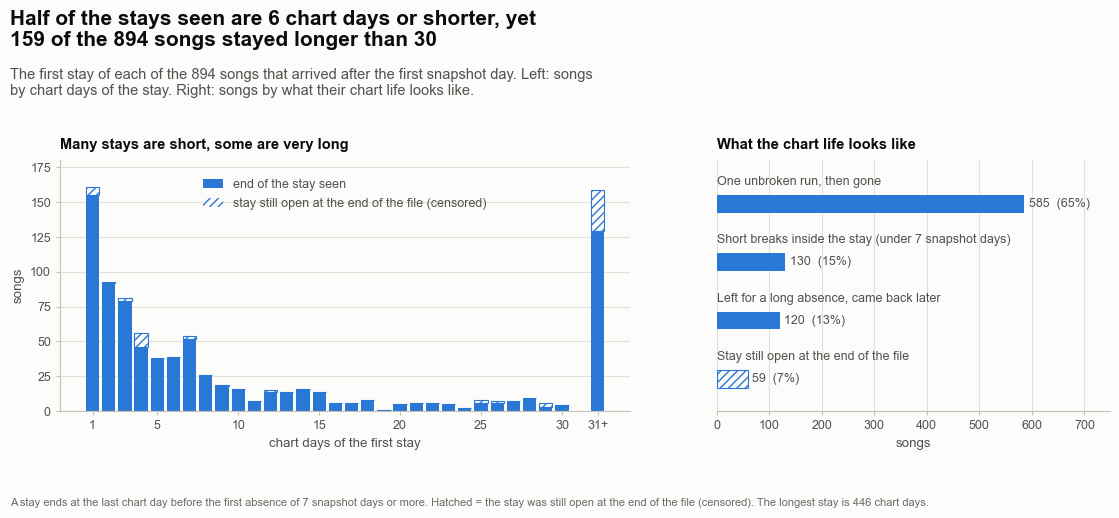

In [5]:
# Figure 01 - what the stays look like
SHOWN = 30                                                                   # one bar per stay length up to 30 chart days, then one bar for the rest
clipped = np.minimum(STAYS["stay"].to_numpy(), SHOWN + 1)
finished_counts = np.bincount(clipped[E], minlength=SHOWN + 2)[1:]
censored_counts = np.bincount(clipped[~E], minlength=SHOWN + 2)[1:]
x_bars = np.arange(1, SHOWN + 2, dtype=float)
x_bars[-1] = SHOWN + 2.2                                                     # a small gap before the bar of the long stays

kind = np.where(~E, "open", np.where(STAYS["returned"], "returned", np.where(STAYS["short_breaks"] > 0, "breaks", "one run")))
kind_counts = {name: int((kind == name).sum()) for name in ["one run", "breaks", "returned", "open"]}
FACTS["kind_one_run"], FACTS["kind_breaks"] = kind_counts["one run"], kind_counts["breaks"]
FACTS["kind_returned"], FACTS["kind_open"] = kind_counts["returned"], kind_counts["open"]
for name in kind_counts:
    FACTS[f"kind_{name.replace(' ', '_')}_share"] = kind_counts[name] / len(STAYS)
FACTS["one_run_all"] = int(((STAYS["first_run_days"] == STAYS["stay"]) & ~STAYS["returned"] & (STAYS["short_breaks"] == 0)).sum())
FACTS["stay_median_raw"] = float(np.median(T))
FACTS["stay_mean_raw"] = float(T.mean())
FACTS["share_le2"] = float((T <= 2).mean())
FACTS["share_stay_one"] = float((T == 1).mean())
FACTS["n_gt30"], FACTS["share_gt30"] = int((T > 30).sum()), float((T > 30).mean())
FACTS["n_gt120"] = int((T > 120).sum())
FACTS["stay_max"] = int(T.max())
FACTS["n_stay_one"] = int((T == 1).sum())
FACTS["n_run_differs"] = int((STAYS["first_run_days"] != STAYS["stay"]).sum())                  # songs whose stay is not their first unbroken run
FACTS["share_run_differs"] = FACTS["n_run_differs"] / len(STAYS)
FACTS["stay_median_finished"] = float(np.median(T[E]))
FACTS["stay_median_open"] = float(np.median(T[~E]))
FACTS["open_late_arrivals"] = int((~E & (STAYS["entry_snapshot"].to_numpy() >= N_SNAPSHOTS - 30)).sum())      # arrived in the last 30 snapshot days of the file
FACTS["open_long_stays"] = int((~E & (T >= 30)).sum())
FACTS["open_both"] = int((~E & (STAYS["entry_snapshot"].to_numpy() >= N_SNAPSHOTS - 30) & (T >= 30)).sum())

fig, (axa, axb) = make_fig(11.8, 5.3, 1, 2, left=0.85, right=0.45, bottom=0.95, wspace=0.18, width_ratios=[1.45, 1], panel_titles=True,
                           title=f"Half of the stays seen are {FACTS['stay_median_raw']:.0f} chart days or shorter, yet {FACTS['n_gt30']} of the {FACTS['n_songs']} songs stayed longer than {HORIZON}",
                           subtitle=f"The first stay of each of the {FACTS['n_songs']} songs that arrived after the first snapshot day. Left: songs by chart days of the stay. "
                                    "Right: songs by what their chart life looks like.",
                           note_text=f"A stay ends at the last chart day before the first absence of {GAP} snapshot days or more. Hatched = the stay was still open at the end of the file "
                                     f"(censored). The longest stay is {FACTS['stay_max']} chart days.")
axa.bar(x_bars, finished_counts, width=0.82, color=style.BLUE, label="end of the stay seen")
axa.bar(x_bars, censored_counts, width=0.82, bottom=finished_counts, color=style.SURFACE, edgecolor=style.BLUE, hatch="////", linewidth=0.8, label="stay still open")
axa.set_xticks([1] + list(range(5, SHOWN + 1, 5)) + [x_bars[-1]])
axa.set_xticklabels(["1"] + [str(v) for v in range(5, SHOWN + 1, 5)] + [f"{SHOWN + 1}+"])
axa.set_xlabel("chart days of the first stay")
axa.set_ylabel("songs")
axa.set_ylim(0, (finished_counts + censored_counts).max() * 1.12)
axa.legend(handles=[Patch(facecolor=style.BLUE, edgecolor=style.BLUE, label="end of the stay seen"),
                    Patch(facecolor=style.SURFACE, edgecolor=style.BLUE, hatch="////", label="stay still open at the end of the file (censored)")],
           loc="upper center", bbox_to_anchor=(0.5, 0.97), frameon=False, fontsize=9, labelcolor=style.INK_2, handlelength=1.6)
style_axes(axa, grid="y")
panel_title(axa, "Many stays are short, some are very long")

labels = ["One unbroken run, then gone", f"Short breaks inside the stay (under {GAP} snapshot days)", "Left for a long absence, came back later",
          "Stay still open at the end of the file"]
counts = [kind_counts["one run"], kind_counts["breaks"], kind_counts["returned"], kind_counts["open"]]
y = np.arange(len(counts))
bars = axb.barh(y, counts, height=0.3, color=style.BLUE)
bars[3].set_facecolor(style.SURFACE); bars[3].set_edgecolor(style.BLUE); bars[3].set_hatch("////"); bars[3].set_linewidth(0.8)
for yi, label, count in zip(y, labels, counts):
    axb.text(0, yi - 0.27, label, ha="left", va="bottom", fontsize=9, color=style.INK_2)
    axb.text(count + max(counts) * 0.015, yi, f"{count}  ({100 * count / len(STAYS):.0f}%)", ha="left", va="center", fontsize=9, color=style.INK_2)
axb.set_yticks([])
axb.set_ylim(len(counts) - 0.45, -0.75)
axb.set_xlim(0, max(counts) * 1.28)
axb.set_xlabel("songs")
style_axes(axb, grid="x", left_spine=False)
panel_title(axb, "What the chart life looks like")
save_fig(fig, "p6b_01_stays", FIG_DIR)
plt.show()

**What to notice**

- The stays are very uneven. Half of the stays seen are 6 chart days or shorter, yet the mean is 21.7 and the longest is 446: a few very long stays pull the average far above a typical stay. 161 songs (18%) were on the chart for a single day, and 159 (18%) for more than 30 chart days, 34 of them for more than 120. For a measure like this the average says little; curves and medians do better, and that is what the next section draws.
- 59 stays (6.6%) are still open at the end of the file. They are not short ones that went missing: their median is 38 chart days against 6 for the finished stays. 29 of them arrived in the last 30 snapshot days of the file and simply have had no time to finish, and 30 have already stayed 30 chart days or more. Leaving them out, or treating them as finished on their last day, would remove or cut short exactly the longest-lasting songs.
- 585 songs (65%) have one unbroken run that ends and does not return. 130 (15%) miss at least one snapshot day inside their stay, and 120 (13%) leave for a long absence and come back. For 199 songs (22%) the stay is not the same as the first unbroken run, so a rule that treated any absence as the end (the rule of Phase 5) would have cut their stays short. The definition of this notebook is the more careful one.

## Section 3 - The survival curve and the hazard by age

Two pictures describe how long songs stay. The *survival curve* S(a) gives, for every number of chart days a, the share of songs whose stay lasts *longer* than a chart days. It starts at 100% and can only go down. The *hazard* of a chart day is the chance that it is the last day of a stay, given that the song reached it. The curve tells the story in one line; the hazard says where on the way the songs are lost, and it is the quantity that the model of Section 6 works with.

A word on how the curve is made. It is the Kaplan-Meier estimate: on every chart day a, take the songs still on the chart on that day, find what share of them left after it, and multiply the shares of all days up to a. A song whose stay is still open counts as being on the chart for as many days as we saw it and is never counted as an exit; that is how the 59 open stays are kept without being treated as finished.

**What this code is.** The survival curve of all 894 stays, with two kinds of band around it, and the numbers read off it. The first band comes from the artist bootstrap: draw 1,000 sets of artists with replacement (a whole artist, with all of that artist's songs, is drawn or not drawn), recompute the curve for each set, and take the middle 95% of the results at every age. The second band is the textbook Greenwood interval, which treats every song as an independent observation.

**Why we need it.** A single curve says nothing about how sure we can be of it. Songs of one artist arrive together and leave together, and Phase 5 measured how alike they are, so 894 songs carry less information than 894 unrelated songs would. The artist bootstrap measures the uncertainty that this leaves; the Greenwood band shows what would have been claimed if the relation between songs had been ignored. The cell also shows what happens if the open stays are mishandled: treated as finished on their last day, or dropped.

**What will happen.** The code draws the artist weights once (1,000 rows of 894 weights; they are reused by every later section), computes the curve of the data and of every draw, and the Greenwood band from `kaplan_meier` of Phase 5. It checks that the two Kaplan-Meier calculations agree. It stores S at 3, 7, 14, 30, 60 and 90 chart days with both bands, the median stay, the average number of chart days used out of the first 30, and the same figures for the two mishandled versions. It prints one table.

**Expected outcome.** About 63% of the songs are still on the chart after 3 chart days, 43% after 7, 30% after 14, 19% after 30 and 7% after 90, with a median stay of 6 chart days. The artist band is visibly wider than the Greenwood band. Treating open stays as finished or dropping them lowers the share still on the chart after 30 chart days.

**Motive.** Say how long songs stay and how sure we are, in a way that does not pretend that songs of one artist are independent.

In [6]:
W_BOOT = np.vstack(list(cluster_bootstrap_weights(ARTISTS, N_BOOT, SEED)))   # one row per draw: how many times each song's artist was drawn (0, 1, 2 ...)
FACTS["boot_draws"] = W_BOOT.shape[0]
assert W_BOOT.shape == (N_BOOT, len(STAYS))

AGES = np.arange(0, int(T.max()) + 1)                                        # chart days 0, 1, 2 ... up to the longest stay
S_OBS = survival_grid(T, E, AGES)                                            # S(a): the share of songs whose stay lasts MORE than a chart days
S_BOOT = survival_grid(T, E, AGES, weights=W_BOOT)                           # the same curve for every artist draw (one row each)
S_LOW, S_HIGH = np.percentile(S_BOOT, [2.5, 97.5], axis=0)                   # the 95% band of the artist bootstrap

km = kaplan_meier(T, E)                                                      # the textbook estimate, with its Greenwood interval (songs treated as independent)
at = np.searchsorted(km["time"].to_numpy(), AGES, side="right") - 1
assert np.allclose(km["survival"].to_numpy()[at], S_OBS), "the two Kaplan-Meier calculations disagree"
GW_LOW, GW_HIGH = km["ci_low"].to_numpy()[at], km["ci_high"].to_numpy()[at]

KEY_AGES = [1, 2, 3, 7, 14, 30, 60, 90]
for a in KEY_AGES:
    FACTS[f"s{a}"], FACTS[f"s{a}_low"], FACTS[f"s{a}_high"] = float(S_OBS[a]), float(S_LOW[a]), float(S_HIGH[a])
    FACTS[f"gw{a}_low"], FACTS[f"gw{a}_high"] = float(GW_LOW[a]), float(GW_HIGH[a])
FACTS["band_ratio_30"] = float((S_HIGH[30] - S_LOW[30]) / (GW_HIGH[30] - GW_LOW[30]))     # how much wider the artist band is than the textbook band at 30 days

medians = median_stay(S_BOOT)
FACTS["median_stay"] = median_stay(S_OBS)
FACTS["median_stay_low"], FACTS["median_stay_high"] = (float(v) for v in np.nanpercentile(medians, [2.5, 97.5]))
FACTS["rmst30"] = float(restricted_mean(S_OBS, HORIZON))
FACTS["rmst30_low"], FACTS["rmst30_high"] = (float(v) for v in np.percentile(restricted_mean(S_BOOT, HORIZON), [2.5, 97.5]))

# ---- what happens if the open stays are mishandled
S_AS_FINISHED = survival_grid(T, np.ones(len(T), dtype=bool), AGES)          # every stay treated as finished on the last day we saw it
S_DROPPED = survival_grid(T[E], np.ones(int(E.sum()), dtype=bool), AGES)     # the open stays removed from the data
FACTS["s30_as_finished"], FACTS["s30_dropped"] = float(S_AS_FINISHED[30]), float(S_DROPPED[30])
FACTS["median_as_finished"], FACTS["median_dropped"] = median_stay(S_AS_FINISHED), median_stay(S_DROPPED)
FACTS["rmst30_as_finished"], FACTS["rmst30_dropped"] = float(restricted_mean(S_AS_FINISHED, HORIZON)), float(restricted_mean(S_DROPPED, HORIZON))

p6a_facts = json.loads((paths.reports_dir / "p6a_facts.json").read_text(encoding="utf-8")) if (paths.reports_dir / "p6a_facts.json").exists() else {}
FACTS["p6a_chart_days_mean"] = float(p6a_facts["r2_mean"]) if "r2_mean" in p6a_facts else float("nan")

def band(low, high, digits=1):
    return f"{100 * low:.{digits}f}% to {100 * high:.{digits}f}%"

SURVIVAL_TABLE = pd.DataFrame({"after chart days": KEY_AGES, "still on the chart": [f"{100 * S_OBS[a]:.1f}%" for a in KEY_AGES],
                               "artist-bootstrap band": [band(S_LOW[a], S_HIGH[a]) for a in KEY_AGES],
                               "band if songs were independent": [band(GW_LOW[a], GW_HIGH[a]) for a in KEY_AGES]}).set_index("after chart days")
display(SURVIVAL_TABLE)

display(pd.DataFrame({"how the open stays are treated": ["kept as 'at least this long' (Kaplan-Meier)", "treated as finished on their last day", "dropped"],
                      "share still on the chart after 30 days": [f"{100 * S_OBS[30]:.1f}%", f"{100 * S_AS_FINISHED[30]:.1f}%", f"{100 * S_DROPPED[30]:.1f}%"],
                      "median stay": [median_stay(S_OBS), median_stay(S_AS_FINISHED), median_stay(S_DROPPED)],
                      "chart days used of the first 30": [f"{restricted_mean(S_OBS, HORIZON):.2f}", f"{restricted_mean(S_AS_FINISHED, HORIZON):.2f}",
                                                           f"{restricted_mean(S_DROPPED, HORIZON):.2f}"]}).set_index("how the open stays are treated"))
print(f"Median stay {FACTS['median_stay']:.0f} chart days (95% band {FACTS['median_stay_low']:.0f} to {FACTS['median_stay_high']:.0f}); "
      f"chart days used of the first {HORIZON}: {FACTS['rmst30']:.2f} ({FACTS['rmst30_low']:.2f} to {FACTS['rmst30_high']:.2f}); Phase 6A counted {FACTS['p6a_chart_days_mean']:.2f} on its 832 songs.")

,still on the chart,artist-bootstrap band,band if songs were independent
after chart days,,,
1,82.7%,76.9% to 87.1%,80.0% to 85.0%
2,72.3%,65.6% to 77.7%,69.2% to 75.1%
3,63.4%,55.2% to 69.5%,60.1% to 66.4%
7,43.2%,36.7% to 49.1%,39.9% to 46.5%
14,30.3%,25.7% to 35.5%,27.3% to 33.4%
30,19.2%,15.9% to 23.9%,16.7% to 21.9%
60,10.3%,7.7% to 13.6%,8.3% to 12.4%
90,7.2%,5.1% to 10.0%,5.5% to 9.1%


,share still on the chart after 30 days,median stay,chart days used of the first 30
how the open stays are treated,,,
kept as 'at least this long' (Kaplan-Meier),19.2%,6,11.33
treated as finished on their last day,17.8%,6,10.96
dropped,15.4%,6,10.35


Median stay 6 chart days (95% band 4 to 7); chart days used of the first 30: 11.33 (10.01 to 12.59); Phase 6A counted 11.27 on its 832 songs.


**What this code is.** Figure 2. Left: the survival curve for the first 90 chart days, with the artist-bootstrap band (shaded) and the Greenwood band (dashed lines). Right: for six ages, the share still on the chart with both bands side by side.

**Why we need it.** The curve is the answer to the main question of the phase, and the comparison of the two bands is the reason that the notebook uses the artist bootstrap everywhere: it shows in one picture how much narrower the doubt would look if songs were treated as independent.

**What will happen.** The code draws the curve as steps (a song leaves on a whole chart day), shades the artist band, adds the dashed edges of the Greenwood band, marks the median stay and the six ages, and draws the right panel as one row per age, the artist band as a thick bar and the Greenwood band as a thin line. It saves the picture as `p6b_02_survival.png`.

**Expected outcome.** A curve that drops steeply in the first week, flattens, and is still above 5% at 90 chart days. The shaded band is wider than the dashed one at every age, most clearly in the middle of the curve (at 14 and 30 chart days).

**Motive.** Show the central result of the phase and how far to trust it.

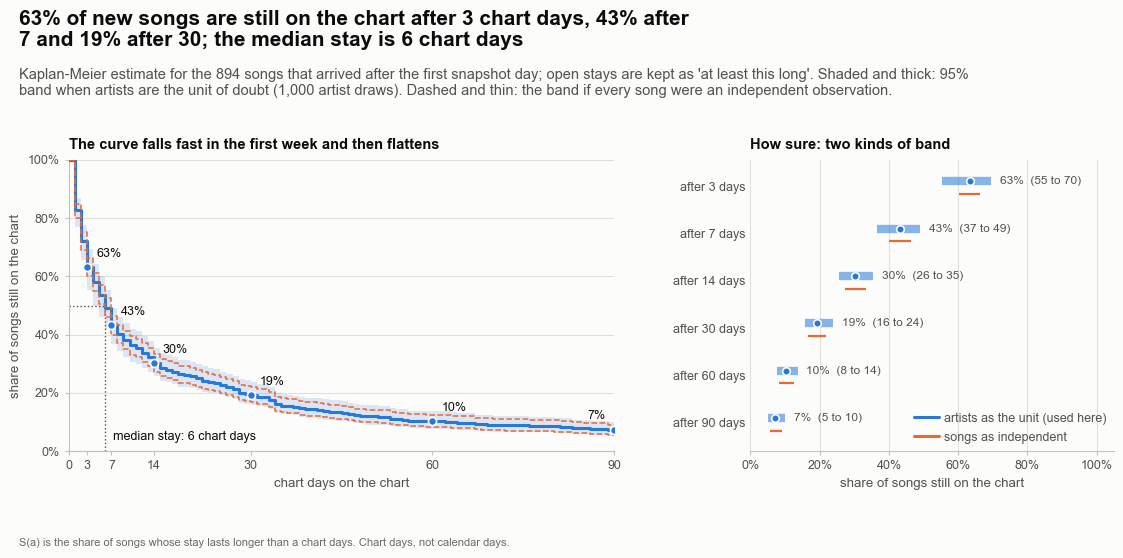

In [7]:
# Figure 02 - how many songs are still on the chart after a number of chart days
SHOW_AGES = [3, 7, 14, 30, 60, 90]
fig, (axa, axb) = make_fig(11.8, 5.7, 1, 2, left=0.85, right=0.5, bottom=0.95, wspace=0.3, width_ratios=[1.5, 1], panel_titles=True,
                           title=f"{100 * FACTS['s3']:.0f}% of new songs are still on the chart after 3 chart days, {100 * FACTS['s7']:.0f}% after 7 and {100 * FACTS['s30']:.0f}% after 30; "
                                 f"the median stay is {FACTS['median_stay']:.0f} chart days",
                           subtitle=f"Kaplan-Meier estimate for the {FACTS['n_songs']} songs that arrived after the first snapshot day; open stays are kept as 'at least this long'. "
                                    "Shaded and thick: 95% band when artists are the unit of doubt (1,000 artist draws). Dashed and thin: the band if every song were an independent observation.",
                           note_text="S(a) is the share of songs whose stay lasts longer than a chart days. Chart days, not calendar days.")
SP.draw_survival_curves(axa, [{"label": None, "ages": AGES, "survival": S_OBS, "low": S_LOW, "high": S_HIGH, "color": style.BLUE}], x_max=90)
axa.step(AGES[:91], GW_LOW[:91], where="post", color=style.ORANGE, linewidth=1.1, linestyle="--", zorder=4)
axa.step(AGES[:91], GW_HIGH[:91], where="post", color=style.ORANGE, linewidth=1.1, linestyle="--", zorder=4)
axa.plot([FACTS["median_stay"]] * 2, [0, 0.5], color=style.INK_2, linewidth=1.0, linestyle=":", zorder=2)
axa.plot([0, FACTS["median_stay"]], [0.5, 0.5], color=style.INK_2, linewidth=1.0, linestyle=":", zorder=2)
direct_label(axa, FACTS["median_stay"] + 1.2, 0.05, f"median stay: {FACTS['median_stay']:.0f} chart days", size=9, color=style.INK)
for a in SHOW_AGES:
    axa.scatter([a], [S_OBS[a]], s=34, color=style.BLUE, edgecolor=style.SURFACE, linewidth=1.2, zorder=5)
    if a == SHOW_AGES[-1]:
        direct_label(axa, a - 1.5, S_OBS[a] + 0.05, f"{100 * S_OBS[a]:.0f}%", ha="right", size=9, color=style.INK)       # the last label sits left of its dot: the axis ends there
    else:
        direct_label(axa, a + 1.5, S_OBS[a] + 0.045, f"{100 * S_OBS[a]:.0f}%", size=9, color=style.INK)
axa.set_xticks([0, 3, 7, 14, 30, 60, 90])
axa.set_xlabel("chart days on the chart")
axa.set_ylabel("share of songs still on the chart")
axa.set_ylim(0, 1.0)
style_axes(axa, grid="y")
panel_title(axa, "The curve falls fast in the first week and then flattens")

y = np.arange(len(SHOW_AGES))
for yi, a in zip(y, SHOW_AGES):
    axb.hlines(yi + 0.17, GW_LOW[a], GW_HIGH[a], color=style.ORANGE, linewidth=1.6, zorder=2)
    axb.hlines(yi - 0.1, S_LOW[a], S_HIGH[a], color=style.BLUE, linewidth=6.0, alpha=0.55, zorder=2)
    axb.scatter([S_OBS[a]], [yi - 0.1], s=30, color=style.BLUE, edgecolor=style.SURFACE, linewidth=1.2, zorder=4)
    direct_label(axb, S_HIGH[a] + 0.025, yi - 0.1, f"{100 * S_OBS[a]:.0f}%  ({100 * S_LOW[a]:.0f} to {100 * S_HIGH[a]:.0f})", size=8.6, color=style.INK_2)
axb.set_yticks(y)
axb.set_yticklabels([f"after {a} days" for a in SHOW_AGES])
axb.set_ylim(len(SHOW_AGES) - 0.4, -0.55)
axb.xaxis.set_major_formatter(SP.percent_axis)
axb.set_xlim(0, 1.05)
axb.set_xlabel("share of songs still on the chart")
style_axes(axb, grid="x", left_spine=False)
axb.tick_params(axis="y", length=0)
swatch_legend(axb, [("artists as the unit (used here)", style.BLUE, "line"), ("songs as independent", style.ORANGE, "line")], loc="lower right")
panel_title(axb, "How sure: two kinds of band")
save_fig(fig, "p6b_02_survival", FIG_DIR)
plt.show()

**What to notice**

- The curve falls fastest at the start. 83% of the songs are still on the chart after their first chart day, 63% after three, 43% after a week. The median stay is 6 chart days (95% band 4 to 7); 19% are left after 30 chart days and 7% after 90. A song that gets through the first week has much better odds than a new one: 45% of the songs on the chart on day 7 are still there on day 30, against 19% of all new songs.
- The artist band is wider than the textbook band at every age shown. At 30 chart days the artist band runs from 15.9% to 23.9%, the textbook band from 16.7% to 21.9%: the artist band is 1.5 times as wide. Songs of one artist rise and fall together, so the data say less than 894 independent songs would. Every band from here on is made by drawing whole artists.
- Open stays matter, and only on the right-hand side of the curve. Treating the 59 open stays as finished on their last day lowers the share still on the chart after 30 chart days from 19.2% to 17.8%, and dropping them lowers it to 15.4%. The median stays at 6 in all three versions, because the open stays are few and mostly long: they do not change when the half-way point is passed, they change how many songs go on beyond it.
- A new song uses 11.33 chart days of its first 30 on average (95% band 10.01 to 12.59). Phase 6A counted 11.27 on the 832 songs that could be followed for 30 snapshot days. The two are computed differently (the area under the curve of all 894 songs here, a plain average on a subset there), so agreement to one decimal is a useful check on both.

**What this code is.** The hazard by age and the median further stay. For nine age windows (chart day 1, day 2, day 3, days 4 to 7, 8 to 14, 15 to 30, 31 to 60, 61 to 120, 121 and later) the code counts the exits and the chart days lived in the window and divides one by the other: the chance that a chart day in the window is the last day of a stay. It does the same for each artist draw to get a band. For six ages (0, 3, 7, 14, 30, 60 chart days) it also finds the *median further stay*: of the songs that are still on the chart at that age, how many more chart days until half of them have gone.

**Why we need it.** The survival curve shows how many songs are left; the hazard shows how fast they are being lost at each stage. If the chance of leaving were the same on every day, the curve would be a smooth exponential decay and one number would describe it. If it falls with age, a song that has stayed a while is a different kind of song from a new one, and any model must allow for that. The model of Section 6 gives every age window its own baseline for exactly this reason.

**What will happen.** `window_hazard` returns exits, chart days and the ratio for each window; the same call with the weight matrix gives the ratio for all 1,000 draws, and the 2.5th and 97.5th percentiles are the band. `median_further_stay` is applied to the curve of the data and to each draw. Two tables are printed.

**Expected outcome.** A hazard of about 17% on the first chart day, falling through about 13%, 12% and 9% in the first week to a few per cent after the second week and about half a per cent after day 120. A median further stay that grows with age: about 6 chart days for a new song, 11 after 3 days, 20 after a week and more than 50 after two months.

**Motive.** Show where in a stay the songs are lost, and that the chance of leaving is far from constant.

In [8]:
LABELS = window_labels(AGE_EDGES)                                            # '1', '2', '3', '4-7', '8-14', '15-30', '31-60', '61-120', '121+'
exits_w, days_w, hazard_w = window_hazard(T, E, AGE_EDGES)
_, _, hazard_boot = window_hazard(T, E, AGE_EDGES, weights=W_BOOT)           # the same ratios for every artist draw
H_LOW, H_HIGH = np.nanpercentile(hazard_boot, [2.5, 97.5], axis=0)

HAZARD_TABLE = pd.DataFrame({"window": LABELS, "from_day": np.array(AGE_EDGES[:-1]) + 1, "to_day": [float(v) if v < 10_000 else np.nan for v in AGE_EDGES[1:]],
                             "songs_reaching": [int((T > edge).sum()) for edge in AGE_EDGES[:-1]], "exits": exits_w.astype(int),
                             "chart_days": days_w.astype(int), "hazard": hazard_w, "low": H_LOW, "high": H_HIGH})
for k, label in enumerate(LABELS, start=1):
    FACTS[f"hz{k}"], FACTS[f"hz{k}_low"], FACTS[f"hz{k}_high"] = float(hazard_w[k - 1]), float(H_LOW[k - 1]), float(H_HIGH[k - 1])
    FACTS[f"hz{k}_exits"], FACTS[f"hz{k}_days"] = int(exits_w[k - 1]), int(days_w[k - 1])
FACTS["hz_first_over_last"] = float(hazard_w[0] / hazard_w[-1])
FACTS["n_windows"] = len(LABELS)
assert int(exits_w.sum()) == FACTS["n_exits"] and int(days_w.sum()) == FACTS["n_days"], "every exit and every chart day belongs to exactly one window"

display(HAZARD_TABLE.assign(hazard=lambda d: [f"{100 * v:.1f}%" for v in d["hazard"]],
                            band=lambda d: [f"{100 * a:.1f}% to {100 * b:.1f}%" for a, b in zip(d["low"], d["high"])]).drop(columns=["from_day", "to_day", "low", "high"]).set_index("window"))

FURTHER_AGES = [0, 3, 7, 14, 30, 60]
further_boot = np.array([median_further_stay(S_BOOT, a) for a in FURTHER_AGES])         # one row per age, one column per artist draw
FURTHER_TABLE = pd.DataFrame({"age": FURTHER_AGES, "still_on_chart": [S_OBS[a] for a in FURTHER_AGES],
                              "median_further_stay": [median_further_stay(S_OBS, a) for a in FURTHER_AGES],
                              "low": np.nanpercentile(further_boot, 2.5, axis=1), "high": np.nanpercentile(further_boot, 97.5, axis=1)})
for row in FURTHER_TABLE.itertuples():
    FACTS[f"further{row.age}"], FACTS[f"further{row.age}_low"], FACTS[f"further{row.age}_high"] = float(row.median_further_stay), float(row.low), float(row.high)
FACTS["s30_given_7"] = float(S_OBS[30] / S_OBS[7])
FACTS["reach60_songs"] = int((T > 60).sum())                                 # songs that get past chart day 60: the data behind the last row
FACTS["reach60_artists"] = int(STAYS.loc[T > 60, "primary_artist"].nunique())
display(FURTHER_TABLE.assign(still_on_chart=lambda d: [f"{100 * v:.1f}%" for v in d["still_on_chart"]],
                             band=lambda d: [f"{a:.0f} to {b:.0f}" for a, b in zip(d["low"], d["high"])]).drop(columns=["low", "high"]).set_index("age"))

,songs_reaching,exits,chart_days,hazard,band
window,,,,,
1,894,155,894,17.3%,12.9% to 23.1%
2,733,92,733,12.6%,9.4% to 16.7%
3,640,79,640,12.3%,8.6% to 17.5%
4-7,559,175,1953,9.0%,7.0% to 10.9%
8-14,372,111,2224,5.0%,3.7% to 6.1%
15-30,259,94,3353,2.8%,2.1% to 3.5%
31-60,159,73,3278,2.2%,1.6% to 2.8%
61-120,80,40,3359,1.2%,0.9% to 1.6%
121+,34,16,2970,0.5%,0.3% to 0.9%


,still_on_chart,median_further_stay,band
age,,,
0,100.0%,6,4 to 7
3,63.4%,11,8 to 15
7,43.2%,20,15 to 26
14,30.3%,24,20 to 33
30,19.2%,37,23 to 53
60,10.3%,56,44 to 109


**What this code is.** Figure 3. Left: the hazard of each age window as a bar with its artist band. Right: the median further stay at six ages, with its band.

**Why we need it.** The two panels say the same thing from two sides. The left one says that the chance of leaving falls steeply with age; the right one says what that means for a song: the longer it has stayed, the longer it can be expected to go on.

**What will happen.** The code draws nine bars (one for each age window, equal width although the windows are of different length), a thin line from the lower to the upper end of each band, and the value on top. On the right, one dot for each age with its band, the age on the vertical axis. It saves the picture as `p6b_03_hazard.png`.

**Expected outcome.** Bars that fall from the first window to the last, about thirty-fold. A row of dots that moves to the right with age.

**Motive.** Show that a stay has a first, dangerous part and a long, calm one, which is what the age windows of the model are for.

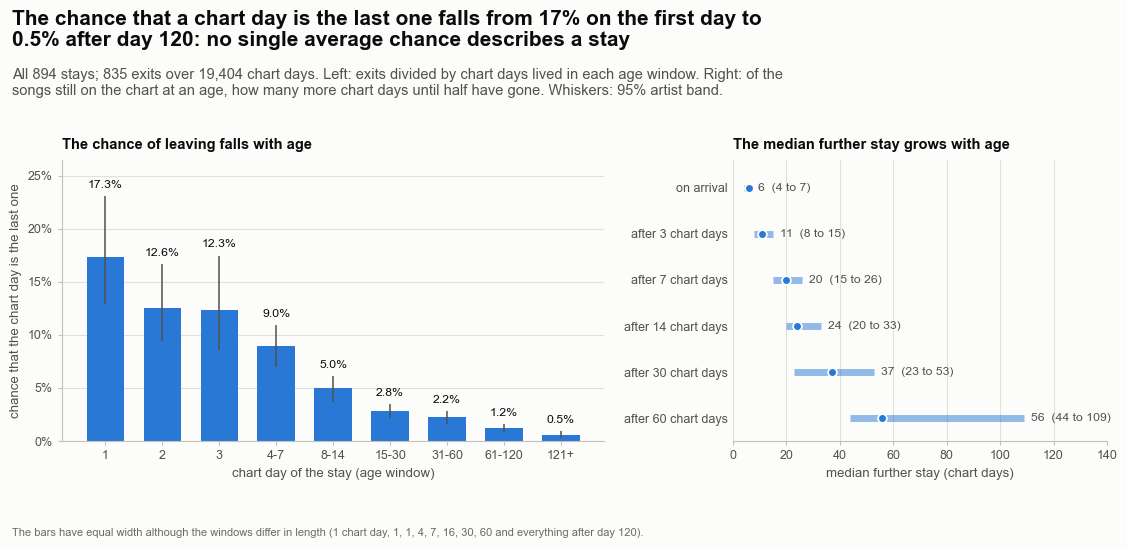

In [9]:
# Figure 03 - the chance that a chart day is the last one, and the median further stay
fig, (axa, axb) = make_fig(11.8, 5.6, 1, 2, left=0.85, right=0.5, bottom=0.95, wspace=0.28, width_ratios=[1.45, 1], panel_titles=True,
                           title=f"The chance that a chart day is the last one falls from {100 * FACTS['hz1']:.0f}% on the first day to {100 * FACTS['hz9']:.1f}% after day 120: "
                                 f"no single average chance describes a stay",
                           subtitle=f"All {FACTS['n_songs']} stays; {FACTS['n_exits']} exits over {FACTS['n_days']:,} chart days. Left: exits divided by chart days lived in each age window. "
                                    "Right: of the songs still on the chart at an age, how many more chart days until half have gone. Whiskers: 95% artist band.",
                           note_text="The bars have equal width although the windows differ in length (1 chart day, 1, 1, 4, 7, 16, 30, 60 and everything after day 120).")
x = np.arange(len(LABELS))
axa.bar(x, hazard_w, width=0.66, color=style.BLUE)
axa.vlines(x, H_LOW, H_HIGH, color=style.INK_2, linewidth=1.1, zorder=4)
for xi, value, high in zip(x, hazard_w, H_HIGH):
    direct_label(axa, xi, high + 0.006, f"{100 * value:.1f}%", ha="center", va="bottom", size=8.8, color=style.INK)
axa.set_xticks(x)
axa.set_xticklabels(LABELS)
axa.yaxis.set_major_formatter(SP.percent_axis)
axa.set_ylim(0, 0.265)
axa.set_xlabel("chart day of the stay (age window)")
axa.set_ylabel("chance that the chart day is the last one")
style_axes(axa, grid="y")
panel_title(axa, "The chance of leaving falls with age")

y = np.arange(len(FURTHER_AGES))
for yi, row in zip(y, FURTHER_TABLE.itertuples()):
    axb.hlines(yi, row.low, row.high, color=style.BLUE, linewidth=5.0, alpha=0.5, zorder=2)
    axb.scatter([row.median_further_stay], [yi], s=40, color=style.BLUE, edgecolor=style.SURFACE, linewidth=1.3, zorder=4)
    direct_label(axb, row.high + 2.5, yi, f"{row.median_further_stay:.0f}  ({row.low:.0f} to {row.high:.0f})", size=8.8, color=style.INK_2)
axb.set_yticks(y)
axb.set_yticklabels(["on arrival"] + [f"after {a} chart days" for a in FURTHER_AGES[1:]])
axb.set_ylim(len(FURTHER_AGES) - 0.5, -0.6)
axb.set_xlim(0, 140)
axb.set_xlabel("median further stay (chart days)")
style_axes(axb, grid="x", left_spine=False)
axb.tick_params(axis="y", length=0)
panel_title(axb, "The median further stay grows with age")
save_fig(fig, "p6b_03_hazard", FIG_DIR)
plt.show()

**What to notice**

- The chance of leaving falls at every stage of the stay. 17% of the songs leave after their first chart day (155 of 894), 13% of the rest after the second and 12% after the third; in the rest of the first week 9% per chart day, from the second week 5%, then 2.8%, 2.2% and 1.2%; after day 120 it is 0.5% per chart day. The first day is about 32 times as dangerous as the days after the 120th. The bands of the first three days overlap, so the data do not show a clear difference among them; the step down comes after the third day.
- The median further stay grows with age: 6 chart days on arrival, 11 after 3 chart days, 20 after 7, 24 after 14, 37 after 30 and 56 after 60. The bands widen quickly because fewer songs get that far: only 80 songs, by 56 artists, stay past chart day 60, which is why its band runs from 44 to 109.
- Why the chance falls cannot be read from this chart. Songs that were going to leave leave early, so the ones that remain are a different mix; and the chance of leaving may also fall with age for every song. The two are mixed in these numbers. The notebook does not try to separate them. It measures the chance at each age, and from Section 4 on it compares groups of songs at the same age.

## Section 4 - Who stays longer: five splits of the songs

The first look at what goes with a longer or shorter stay is the simplest one: split the songs into groups by one thing that is known on the arrival day, and compare the groups' survival curves. Five splits are used: the place on the chart on the arrival day (five bands), the number of songs by the same artist that arrived on the same day (an album drop, or a single song arriving alone), the type of release (single or album), whether the song is explicit, and whether it is a collaboration. Each split compares groups that differ in other ways as well, so this section cannot say what *causes* a longer stay. It finds out which splits show a difference worth explaining; Sections 5 and 6 then ask which of the differences remain when the others are held fixed.

**What this code is.** The group comparison. For each of the five splits, the code works out the survival curve of every group with its 95% artist band, the median stay, the share still on the chart after 7 and after 30 chart days, and the number of chart days used out of the first 30. For each split it also runs the log-rank test of the question "do all groups leave the chart at the same rate on every chart day?", once in the textbook form and once in the artist-aware form.

**Why we need it.** A difference between two curves can be luck, and it is easier to be fooled here than it looks: songs of one artist travel together, so an artist with fifteen songs that all arrive on one day and all leave a week later puts fifteen songs into one group and counts as fifteen pieces of evidence. The textbook log-rank test counts them as fifteen; the artist-aware test (the score test of a Cox model with the variance of Lin and Wei) adds up the evidence of each artist before squaring it, so that the artist counts as the one piece of evidence it is. Five splits are asked of one data set, so the five artist-aware p-values are adjusted together with the Holm method.

**What will happen.** The groups are built from the columns of the stays table (the album-drop split uses 1 song, 2 to 4 songs and 5 or more songs). For each group the curve is computed for the data and for every one of the 1,000 artist draws (the draws that do not contain any artist of the group are left out of that group's band). `logrank_k` is run for each split with and without the artists as clusters, and `holm` adjusts the five artist-aware p-values. The table of groups and the table of tests are printed.

**Expected outcome.** Fourteen groups in five splits. Debut place, the number of songs arriving together and release type differ clearly, even after the adjustment; explicit and collaboration do not. The textbook p-values are far smaller than the artist-aware ones (for debut place about 10 to the power of minus 19 against 0.0007), but the same three splits are left.

**Motive.** Find out which differences between groups of songs are visible in the stays, with the doubt measured by artists and not by songs.

In [10]:
DROP_LABELS = ["1 song (alone)", "2 to 4 songs", "5 or more songs"]
STAYS["drop_group"] = pd.cut(STAYS["drop_size"], [0, 1, 4, 10_000], labels=DROP_LABELS)
STAYS["release"] = np.where(STAYS["is_single"] == 1, "Single", "Album or compilation")
STAYS["explicit"] = np.where(STAYS["is_explicit"] == 1, "Explicit", "Not explicit")
STAYS["collab"] = np.where(STAYS["is_collab"] == 1, "Collaboration", "Solo")

# the five splits: test key, name, column, groups in order, and one short key for every group (used to store the facts)
SPLITS = [("band", "Debut place", "debut_band", BAND_LABELS, ["b1", "b2", "b3", "b4", "b5"]),
          ("drop", "Songs by the artist arriving the same day", "drop_group", DROP_LABELS, ["d1", "d2", "d3"]),
          ("single", "Release type", "release", ["Album or compilation", "Single"], ["album", "single"]),
          ("explicit", "Explicit content", "explicit", ["Not explicit", "Explicit"], ["clean", "explicit"]),
          ("collab", "Collaboration", "collab", ["Solo", "Collaboration"], ["solo", "collab"])]


def summarize_group(mask):
    """The curve of one group with its artist band and the headline numbers: median stay, share left after 7 and 30 chart days, chart days used of 30."""
    curve = survival_grid(T[mask], E[mask], AGES)
    usable = W_BOOT[:, mask].sum(axis=1) > 0                                 # a draw without any artist of this group says nothing about it
    draws = survival_grid(T[mask], E[mask], AGES, weights=W_BOOT[:, mask])[usable]
    low, high = np.percentile(draws, [2.5, 97.5], axis=0)
    medians = median_stay(draws)
    return {"songs": int(mask.sum()), "artists": int(STAYS.loc[mask, "primary_artist"].nunique()), "exits": int(E[mask].sum()),
            "curve": curve, "low": low, "high": high, "median": median_stay(curve),
            "median_low": float(np.nanpercentile(medians, 2.5)), "median_high": float(np.nanpercentile(medians, 97.5)),
            "s7": float(curve[7]), "s30": float(curve[30]), "s30_low": float(low[30]), "s30_high": float(high[30]),
            "rmst30": float(restricted_mean(curve, HORIZON))}


GROUP_DATA, GROUP_ROWS, CURVE_ROWS = {}, [], []
for age, value, low, high in zip(AGES[:121], S_OBS[:121], S_LOW[:121], S_HIGH[:121]):
    CURVE_ROWS.append({"split": "All songs", "group": "All new songs", "age": int(age), "survival": value, "low": low, "high": high})
for test_key, split_name, column, order, short_keys in SPLITS:
    for group, short_key in zip(order, short_keys):
        info = summarize_group((STAYS[column].astype(str) == group).to_numpy())
        GROUP_DATA[(test_key, group)] = info
        for name in ["songs", "artists", "median", "median_low", "median_high", "s7", "s30", "s30_low", "s30_high", "rmst30"]:
            FACTS[f"{test_key}_{short_key}_{name}"] = info[name]
        GROUP_ROWS.append({"split": split_name, "group": group, "songs": info["songs"], "artists": info["artists"], "exits": info["exits"],
                           "median_stay": info["median"], "median_low": info["median_low"], "median_high": info["median_high"],
                           "share_left_after_7": info["s7"], "share_left_after_30": info["s30"], "after_30_low": info["s30_low"],
                           "after_30_high": info["s30_high"], "chart_days_used_of_30": info["rmst30"]})
        for age in range(121):
            CURVE_ROWS.append({"split": split_name, "group": group, "age": age, "survival": info["curve"][age], "low": info["low"][age], "high": info["high"][age]})

TEST_ROWS = []
for test_key, split_name, column, order, short_keys in SPLITS:
    result = logrank_k(T, E, STAYS[column].astype(str).to_numpy(), clusters=ARTISTS)
    TEST_ROWS.append({"key": test_key, "split": split_name, "groups": len(order), "chi2_songs": result["chi2"], "p_songs": result["p"],
                      "chi2_artists": result["chi2_artist"], "p_artists": result["p_artist"]})
TESTS = pd.DataFrame(TEST_ROWS)
TESTS["p_holm"] = holm(TESTS["p_artists"].to_numpy())                       # the five artist-aware tests are one family of questions
for row in TESTS.itertuples():
    FACTS[f"lr_{row.key}_chi2"], FACTS[f"lr_{row.key}_p"] = float(row.chi2_songs), float(row.p_songs)
    FACTS[f"lr_{row.key}_chi2_artists"], FACTS[f"lr_{row.key}_p_artists"] = float(row.chi2_artists), float(row.p_artists)
    FACTS[f"lr_{row.key}_p_holm"], FACTS[f"lr_{row.key}_p_holm_text"] = float(row.p_holm), format_p(row.p_holm)
    FACTS[f"lr_{row.key}_p_artists_text"], FACTS[f"lr_{row.key}_p_text"] = format_p(row.p_artists), format_p(row.p_songs)
FACTS["n_splits_tested"] = len(TESTS)
FACTS["n_splits_clear"] = int((TESTS["p_holm"] < 0.05).sum())

display(pd.DataFrame(GROUP_ROWS).assign(**{"median stay": lambda d: [f"{m:.0f}  ({a:.0f} to {b:.0f})" for m, a, b in zip(d["median_stay"], d["median_low"], d["median_high"])],
                                           "left after 7": lambda d: [f"{100 * v:.0f}%" for v in d["share_left_after_7"]],
                                           "left after 30 (95% band)": lambda d: [f"{100 * v:.0f}%  ({100 * a:.0f} to {100 * b:.0f})" for v, a, b in zip(d["share_left_after_30"], d["after_30_low"], d["after_30_high"])],
                                           "chart days of 30": lambda d: [f"{v:.1f}" for v in d["chart_days_used_of_30"]]})
        [["split", "group", "songs", "artists", "median stay", "left after 7", "left after 30 (95% band)", "chart days of 30"]].set_index(["split", "group"]))
display(TESTS.assign(**{"textbook chi2": lambda d: d["chi2_songs"].round(1), "textbook p": [format_p(p) for p in TESTS["p_songs"]],
                        "artist-aware chi2": lambda d: d["chi2_artists"].round(1), "artist-aware p": [format_p(p) for p in TESTS["p_artists"]],
                        "after Holm": [format_p(p) for p in TESTS["p_holm"]]})
        [["split", "groups", "textbook chi2", "textbook p", "artist-aware chi2", "artist-aware p", "after Holm"]].set_index("split"))

songs  artists     median stay left after 7 left after 30 (95% band) chart days of 30
split                                     group                                                                                                      
Debut place                               1 to 10                 222       47  14  (11 to 20)          68%          31%  (25 to 38)             17.0
                                          11 to 20                186       55     6  (4 to 8)          41%           11%  (7 to 18)              9.7
                                          21 to 30                120       57     4  (3 to 5)          25%            7%  (2 to 12)              6.8
                                          31 to 40                134       80     2  (1 to 3)          26%           14%  (8 to 21)              8.0
                                          41 to 50                232      152     4  (3 to 6)          40%          24%  (19 to 31)             11.4
Songs by the artist arriving the same day 1 song (alone)          385      217    8  (6 to 12)          51%          30%  (25 to 34)             13.9
                                          2 to 4 songs             75       22     3  (3 to 6)          32%           15%  (7 to 27)              8.7
                                          5 or more songs         434       24     6  (3 to 7)          38%           10%  (6 to 15)              9.5
Release type                              Album or compilation    696      152     6  (4 to 7)          40%          16%  (13 to 21)             10.5
                                          Single                  198      120    9  (7 to 14)          54%          29%  (23 to 36)             14.2
Explicit content                          Not explicit            425      167     6  (4 to 8)          45%          19%  (15 to 26)             11.4
                                          Explicit                469       92     6  (4 to 8)          41%          19%  (14 to 25)             11.3
Collaboration                             Solo                    781      204     6  (4 to 8)          43%          19%  (15 to 24)             11.3
                                          Collaboration           113       55    6  (4 to 10)          43%          20%  (13 to 30)             11.5

,groups,textbook chi2,textbook p,artist-aware chi2,artist-aware p,after Holm
split,,,,,,
Debut place,5,94.4,p < 0.001,19.1,p < 0.001,p = 0.004
Songs by the artist arriving the same day,3,29.2,p < 0.001,12.3,p = 0.002,p = 0.009
Release type,2,11.4,p < 0.001,8.2,p = 0.004,p = 0.013
Explicit content,2,0.2,p = 0.70,0.1,p = 0.79,p = 1.00
Collaboration,2,0,p = 0.91,0,p = 0.93,p = 1.00


**What this code is.** Figure 4. Five small charts of survival curves, one for each split, and a sixth that sets the two versions of the log-rank test side by side.

**Why we need it.** The table gives the numbers; the curves show where in the stay the groups part company (on the first day? after a week?) and whether they cross, which a single p-value cannot say. The sixth panel shows what the artist-aware test does to the evidence: every p-value gets larger, but not by the same factor, and the question is which splits are left.

**What will happen.** The code draws the curves up to 60 chart days, each with its 95% artist band and a direct label at its right end. In the sixth panel every split is a row with three marks on a logarithmic axis: the textbook p-value (hollow), the artist-aware p-value (filled) and the artist-aware p-value after the Holm adjustment (diamond), with the 0.05 line. It saves the picture as `p6b_04_groups.png`.

**Expected outcome.** Clear separation in the debut-place panel (the top-10 debuts well above the rest), in the same-day panel (songs that arrive alone above those that arrive with an album) and a smaller one for release type. The curves of explicit against not explicit and of collaboration against solo lie on top of each other. In the sixth panel three splits to the left of the 0.05 line after Holm, two to the right.

**Motive.** See the differences, and see how much of the textbook evidence survives when the artist is the unit.

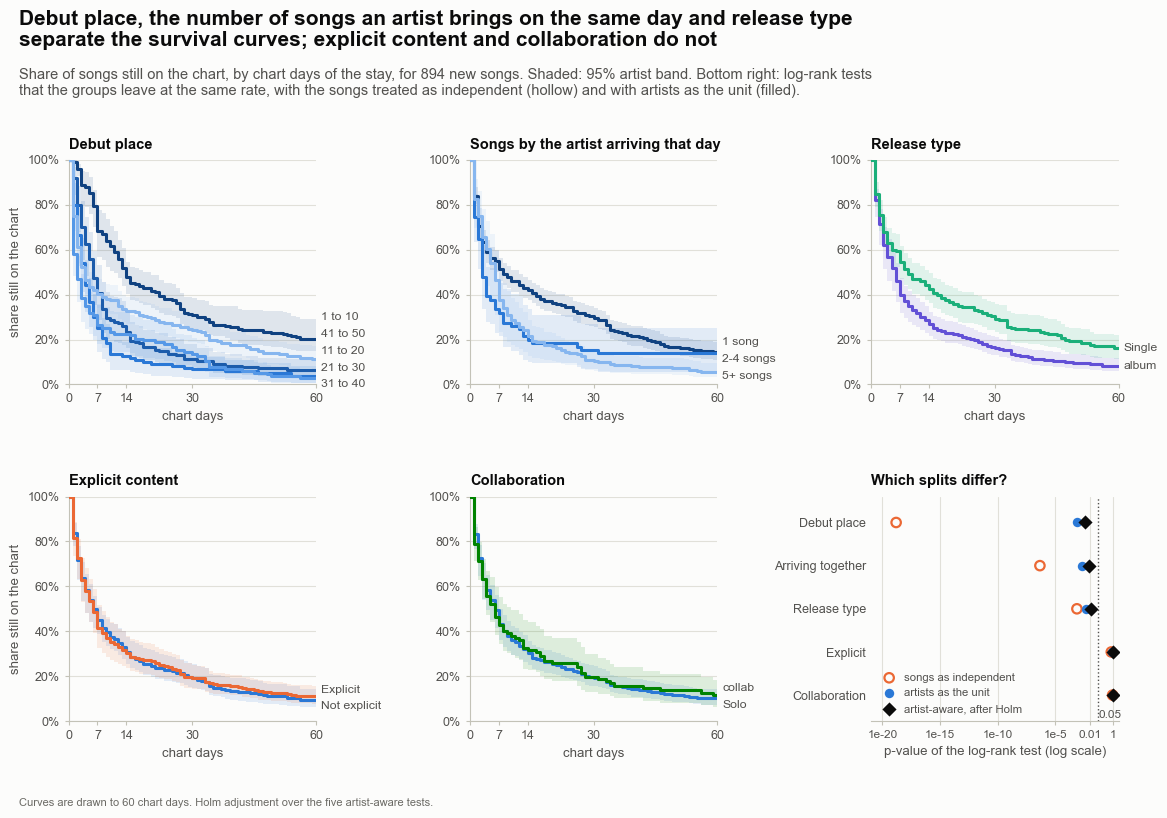

In [11]:
# Figure 04 - survival curves of the groups, and the tests
PALETTE = {"band": MP.step_colors(5)[::-1], "drop": MP.step_colors(3)[::-1], "single": [style.ALBUM_COLOR, style.SINGLE_COLOR],
           "explicit": [style.CLEAN_COLOR, style.EXPLICIT_COLOR], "collab": [style.BLUE, style.GREEN]}
SHORT = {"1 song (alone)": "1 song", "2 to 4 songs": "2-4 songs", "5 or more songs": "5+ songs", "Album or compilation": "album", "Collaboration": "collab"}
PANEL_TITLES = {"band": "Debut place", "drop": "Songs by the artist arriving that day", "single": "Release type", "explicit": "Explicit content", "collab": "Collaboration"}
X_MAX = 60

fig, axes = make_fig(11.8, 8.3, 2, 3, left=0.85, right=0.45, bottom=0.85, hspace=0.5, wspace=0.62, panel_titles=True,
                     title="Debut place, the number of songs an artist brings on the same day and release type separate the survival curves; explicit content and collaboration do not",
                     subtitle=f"Share of songs still on the chart, by chart days of the stay, for {FACTS['n_songs']} new songs. Shaded: 95% artist band. "
                              "Bottom right: log-rank tests that the groups leave at the same rate, with the songs treated as independent (hollow) and with artists as the unit (filled).",
                     note_text=f"Curves are drawn to {X_MAX} chart days. Holm adjustment over the five artist-aware tests.")
slots = [axes[0, 0], axes[0, 1], axes[0, 2], axes[1, 0], axes[1, 1]]
for ax, (test_key, split_name, column, order, short_keys) in zip(slots, SPLITS):
    curves = [{"label": SHORT.get(group, group), "ages": AGES, "survival": GROUP_DATA[(test_key, group)]["curve"], "low": GROUP_DATA[(test_key, group)]["low"],
               "high": GROUP_DATA[(test_key, group)]["high"], "color": color} for group, color in zip(order, PALETTE[test_key])]
    SP.draw_survival_curves(ax, curves, x_max=X_MAX, label_gap=0.075, band_alpha=0.12)
    ax.set_xticks([0, 7, 14, 30, 60])
    ax.set_xlabel("chart days")
    style_axes(ax, grid="y")
    panel_title(ax, PANEL_TITLES[test_key])
axes[0, 0].set_ylabel("share still on the chart")
axes[1, 0].set_ylabel("share still on the chart")

axt = axes[1, 2]
y = np.arange(len(TESTS))
axt.axvline(0.05, color=style.INK_2, linewidth=1.0, linestyle=":")
axt.scatter(TESTS["p_songs"], y, s=46, facecolor="none", edgecolor=style.ORANGE, linewidth=1.6, zorder=3, label="songs as independent")
axt.scatter(TESTS["p_artists"], y, s=46, color=style.BLUE, zorder=4, label="artists as the unit")
axt.scatter(TESTS["p_holm"], y, s=52, marker="D", color=style.INK, zorder=5, label="artist-aware, after Holm")
axt.set_xscale("log")
axt.set_xlim(1e-21, 3)
axt.set_xticks([1e-20, 1e-15, 1e-10, 1e-5, 1e-2, 1])
axt.set_xticklabels(["1e-20", "1e-15", "1e-10", "1e-5", "0.01", "1"], fontsize=8.5)
axt.minorticks_off()
axt.set_yticks(y)
axt.set_yticklabels(["Debut place", "Arriving together", "Release type", "Explicit", "Collaboration"], fontsize=9)
axt.set_ylim(len(TESTS) - 0.4, -0.6)
axt.set_xlabel("p-value of the log-rank test (log scale)")
style_axes(axt, grid="x", left_spine=False)
axt.tick_params(axis="y", length=0)
direct_label(axt, 0.06, 4.45, "0.05", size=8.5, color=style.INK_2)
axt.legend(loc="lower left", frameon=False, fontsize=8.2, labelcolor=style.INK_2, handletextpad=0.3, borderaxespad=0.2)
panel_title(axt, "Which splits differ?")
save_fig(fig, "p6b_04_groups", FIG_DIR)
plt.show()

**What to notice**

- *Debut place.* A song that arrives in the top 10 has a median stay of 14 chart days (95% band 11 to 20); 68% are still there after a week and 31% after 30 chart days. For the bands 11 to 20, 21 to 30 and 31 to 40 the median falls to 6, 4 and 2. The last band does not continue the fall: the median for debuts at 41 to 50 is 4 and 24% of them are still on the chart after 30 chart days, against 14% for 31 to 40 and 7% for 21 to 30. The crude pattern is a dip and a recovery, not a straight line. Section 5 looks at why.
- *Songs arriving the same day.* Songs that arrive alone have a median stay of 8 chart days and 30% are left after 30; songs that arrive with one to three others by the same artist have a median of 3 and 15%; songs that come in a drop of five or more have a median of 6 and 10%. The drop group of five or more has 434 songs but only 24 artists, and its band shows how little 434 songs by 24 artists say.
- *Release type.* Singles stay longer than album tracks: median 9 chart days (7 to 14) against 6 (4 to 7), and 29% against 16% still on the chart after 30 chart days. Section 5 asks whether this is a property of singles or of how singles arrive.
- *Explicit content and collaboration.* The two curves lie on top of each other in both panels: median 6 against 6 chart days for explicit content, 6 against 6 for collaboration, and the shares left after 30 chart days are 19% against 19% and 19% against 20%.
- *The tests.* With songs treated as independent, all three differences look overwhelming: debut place p < 0.001 (chi-square 94.4), songs arriving together p < 0.001 (29.2), release type p < 0.001 (11.4). With artists as the unit the statistics shrink to 19.1, 12.3 and 8.2; the p-values are p < 0.001, p = 0.002 and p = 0.004. After the Holm adjustment for five tests they are p = 0.004, p = 0.009 and p = 0.013: 3 of the 5 splits are clearly different. Explicit content (p = 0.79) and collaboration (p = 0.93) show no sign of a difference in either version of the test.

**What this code is.** The size of the differences, in the unit that matters. For each split the code compares every group with a reference group (the top-10 debuts, the songs that arrive alone, album tracks, songs that are not explicit, solo songs) by the number of chart days a group uses out of the first 30, and puts a 95% artist band on each difference.

**Why we need it.** A p-value says whether a difference is likely to be more than luck; it says nothing about how big it is. "Chart days used out of the first 30" is the area under the survival curve up to 30 chart days, and a difference between two groups in this unit is a number of chart days that a reader can picture. For the splits that show no difference the band has a second use: it says how large a difference the data can rule out.

**What will happen.** For each group the code computes the average chart days used out of the first 30 on the data and on every artist draw, using the same draws for both groups of a comparison (so that the difference is measured inside each draw), and takes the 2.5th and 97.5th percentiles of the differences. The results go in a table and in Figure 5.

**Expected outcome.** The top-10 debuts use about 7 to 10 more chart days than the other bands, and the bands of the differences stay clear of zero. Songs that arrive alone use about 5 more than songs that arrive in a drop, and singles about 4 more than album tracks. For explicit content and collaboration the differences are close to zero and the bands run on both sides of it.

**Motive.** Turn "these groups differ" into "by how many chart days", and say how much a difference of zero is worth when nothing was found.

In [12]:
CONTRASTS = [("band", "Debut place", "11 to 20", "1 to 10"), ("band", "Debut place", "21 to 30", "1 to 10"),
             ("band", "Debut place", "31 to 40", "1 to 10"), ("band", "Debut place", "41 to 50", "1 to 10"),
             ("drop", "Songs by the artist arriving the same day", "2 to 4 songs", "1 song (alone)"),
             ("drop", "Songs by the artist arriving the same day", "5 or more songs", "1 song (alone)"),
             ("single", "Release type", "Single", "Album or compilation"),
             ("explicit", "Explicit content", "Explicit", "Not explicit"),
             ("collab", "Collaboration", "Collaboration", "Solo")]
COLUMN_OF = {key: column for key, _, column, _, _ in SPLITS}
AGES_HORIZON = np.arange(HORIZON)                                            # chart days 0 ... 29: S(0) + ... + S(29) is the chart days used of the first 30


def rmst_draws(mask):
    """Chart days used of the first 30 for every artist draw (a draw without any artist of the group is NaN)."""
    draws = restricted_mean(survival_grid(T[mask], E[mask], AGES_HORIZON, weights=W_BOOT[:, mask]), HORIZON)
    return np.where(W_BOOT[:, mask].sum(axis=1) > 0, draws, np.nan)


CONTRAST_ROWS = []
for index, (test_key, split_name, group, reference) in enumerate(CONTRASTS):
    mask = (STAYS[COLUMN_OF[test_key]].astype(str) == group).to_numpy()
    base = (STAYS[COLUMN_OF[test_key]].astype(str) == reference).to_numpy()
    estimate = GROUP_DATA[(test_key, group)]["rmst30"] - GROUP_DATA[(test_key, reference)]["rmst30"]
    difference = rmst_draws(mask) - rmst_draws(base)                         # the same artist draw for both groups: the difference is measured inside each draw
    low, high = np.nanpercentile(difference, [2.5, 97.5])
    CONTRAST_ROWS.append({"split": split_name, "group": group, "reference": reference, "songs": int(mask.sum()), "reference_songs": int(base.sum()),
                          "difference": estimate, "low": float(low), "high": float(high)})
    FACTS[f"diff{index + 1}"], FACTS[f"diff{index + 1}_low"], FACTS[f"diff{index + 1}_high"] = float(estimate), float(low), float(high)
CONTRAST_TABLE = pd.DataFrame(CONTRAST_ROWS)
FACTS["n_contrasts"] = len(CONTRAST_TABLE)
display(CONTRAST_TABLE.assign(**{"chart days used of 30, difference": [f"{d:+.1f}  ({a:+.1f} to {b:+.1f})" for d, a, b in zip(CONTRAST_TABLE["difference"], CONTRAST_TABLE["low"], CONTRAST_TABLE["high"])]})
        [["split", "group", "reference", "songs", "chart days used of 30, difference"]].set_index(["split", "group"]))

reference  songs chart days used of 30, difference
split                                     group                                                                         
Debut place                               11 to 20                      1 to 10    186              -7.3  (-9.0 to -5.4)
                                          21 to 30                      1 to 10    120            -10.2  (-12.3 to -7.9)
                                          31 to 40                      1 to 10    134             -9.0  (-11.5 to -6.2)
                                          41 to 50                      1 to 10    232              -5.6  (-7.7 to -3.1)
Songs by the artist arriving the same day 2 to 4 songs           1 song (alone)     75              -5.2  (-7.9 to -1.6)
                                          5 or more songs        1 song (alone)    434              -4.4  (-7.3 to -1.9)
Release type                              Single           Album or compilation    198              +3.7  (+1.5 to +6.2)
Explicit content                          Explicit                 Not explicit    469              -0.1  (-2.3 to +2.3)
Collaboration                             Collaboration                    Solo    113              +0.2  (-2.6 to +3.5)

**What this code is.** Figure 5. The nine differences of the table as a forest plot: a dot for the difference and a bar for its 95% artist band, grouped by split, with zero marked.

**Why we need it.** One glance shows which differences are large, which have bands that stay on one side of zero, and what the band looks like when there is nothing to find.

**What will happen.** The code draws one row for each comparison with a bold heading for each split, the reference group named in the heading, the zero line, and the value with its band at the right of each row. It saves the picture as `p6b_05_differences.png`.

**Expected outcome.** The four debut-place rows far to the left of zero, the same-day rows and the single row on either side of it as the table says, and the explicit and collaboration rows sitting on the zero line with bands a few chart days wide.

**Motive.** Show how large the differences are and how much the data can rule out.

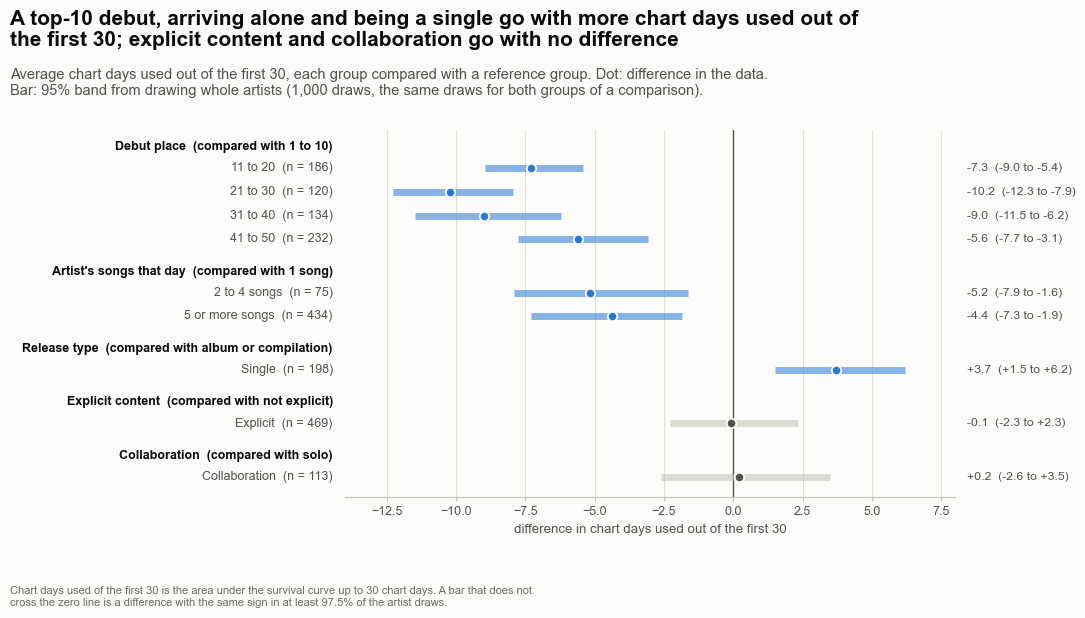

In [13]:
# Figure 05 - how many more or fewer chart days of the first 30 each group uses
fig, ax = make_fig(11.8, 6.3, 1, 1, left=3.7, right=2.0, bottom=0.95,
                   title="A top-10 debut, arriving alone and being a single go with more chart days used out of the first 30; explicit content and collaboration go with no difference",
                   subtitle=f"Average chart days used out of the first {HORIZON}, each group compared with a reference group. Dot: difference in the data. Bar: 95% band from drawing whole artists "
                            f"({N_BOOT:,} draws, the same draws for both groups of a comparison).",
                   note_text="Chart days used of the first 30 is the area under the survival curve up to 30 chart days. A bar that does not cross the zero line is a difference "
                             "with the same sign in at least 97.5% of the artist draws.")
heights, y_position, row_of = [], 0.0, []
for split_key, split_name in [("band", "Debut place  (compared with 1 to 10)"), ("drop", "Artist's songs that day  (compared with 1 song)"),
                              ("single", "Release type  (compared with album or compilation)"), ("explicit", "Explicit content  (compared with not explicit)"),
                              ("collab", "Collaboration  (compared with solo)")]:
    heights.append((y_position, split_name))
    y_position += 0.9
    for index, (test_key, _, group, _) in enumerate(CONTRASTS):
        if test_key == split_key:
            row_of.append((y_position, index))
            y_position += 1.0
    y_position += 0.35
ax.axvline(0, color=style.INK_2, linewidth=1.0, zorder=1)
for y_row, index in row_of:
    row = CONTRAST_TABLE.iloc[index]
    color = style.BLUE if row["high"] < 0 or row["low"] > 0 else style.AXIS
    ax.hlines(y_row, row["low"], row["high"], color=color, linewidth=5.0, alpha=0.55, zorder=2)
    ax.scatter([row["difference"]], [y_row], s=46, color=style.BLUE if color == style.BLUE else style.INK_2, edgecolor=style.SURFACE, linewidth=1.3, zorder=4)
    ax.text(1.02, y_row, f"{row['difference']:+.1f}  ({row['low']:+.1f} to {row['high']:+.1f})", transform=ax.get_yaxis_transform(), ha="left", va="center", fontsize=8.8, color=style.INK_2)
    ax.text(-0.02, y_row, f"{row['group']}  (n = {row['songs']})", transform=ax.get_yaxis_transform(), ha="right", va="center", fontsize=9, color=style.INK_2)
for y_head, name in heights:
    ax.text(-0.02, y_head, name, transform=ax.get_yaxis_transform(), ha="right", va="center", fontsize=9, fontweight="bold", color=style.INK)
ax.set_ylim(y_position - 0.5, -0.7)
ax.set_xlim(-14, 8)
ax.set_yticks([])
ax.set_xlabel(f"difference in chart days used out of the first {HORIZON}")
style_axes(ax, grid="x", left_spine=False)
save_fig(fig, "p6b_05_differences", FIG_DIR)
plt.show()

**What to notice**

- *Debut place.* Every one of the four differences is large and clear of zero. Compared with a top-10 debut, the difference in chart days used out of the first 30 is -7.3 for a song that arrives at 11 to 20 (band -9.0 to -5.4), -10.2 at 21 to 30, -9.0 at 31 to 40 and -5.6 at 41 to 50. The largest gap is in the middle of the chart, and the last band is closer to the top than the two before it: the dip and recovery of the curves.
- *Songs arriving the same day.* Compared with a song that arrives alone, the difference is -5.2 chart days for a song that arrives with one to three others by its artist (band -7.9 to -1.6) and -4.4 for a song that arrives in a drop of five or more (-7.3 to -1.9). The bands are wide because these groups come from only 22 and 24 artists.
- *Release type.* Compared with an album track, the difference for a single is +3.7 chart days (band +1.5 to +6.2).
- *Explicit content and collaboration.* The differences are -0.1 (band -2.3 to +2.3) and +0.2 (-2.6 to +3.5). "No difference" here means no difference larger than about two or three chart days of 30; the data cannot rule out smaller ones.
- These are crude differences. The groups also differ in other ways: a song in a big drop is probably an album track, and a song that arrives alone is more likely to be a single. Whether any difference remains when the others are held fixed is the question of the next two sections.

## Section 5 - Debut place, arriving alone, and the single that does not protect

Section 4 left two puzzles. The curves by debut place do not fall in a straight line: songs that arrive at 41 to 50 stay longer than songs that arrive at 21 to 40. And singles stay longer than album tracks, but singles are also the songs that tend to arrive alone, and songs that arrive alone stay longer for any release type. This section takes the two puzzles apart with the simplest tool there is: compare songs *within* the way they arrived. It is not yet a model. It is a look at who the songs are, and it prepares the model of Section 6.

**What this code is.** The look at debut place and at singles by the way of arriving. First the songs are split into those that arrive alone (the only song of their artist on that snapshot day) and those that arrive with others (two or more songs of the same artist on the day). For each debut band the code finds the share that arrive alone, the share of songs still on the chart after 30 chart days within each way of arriving, and a *mix-adjusted* share: the share that the band would have if its songs were a mix of 43% alone and the rest with others, as in the whole data. For singles it compares singles with album tracks within the songs that arrive alone.

**Why we need it.** A group can look better than another only because it contains more of a kind of song that does well anyway. If songs that arrive alone stay longer, and the bands from 31 to 50 contain mostly songs that arrive alone, the bands will look good for that reason. The mix-adjustment answers: *how would the bands compare if every band had the same mix of arrivals?* The comparison of singles with album tracks within the songs that arrive alone asks the same question for release type.

**What will happen.** For the five bands and for each way of arriving the code calculates the share still on the chart after 30 chart days with an artist band from the 1,000 draws (draws without any artist of a group are left out of that group's band). The mix-adjusted share is 43% times the share of those who arrive alone plus the rest times the share of those who arrive with others, calculated in each draw. For singles it does the same for the singles and the album tracks among the songs that arrive alone, adds a difference in chart days used out of the first 30 with a paired band, and runs the log-rank test inside the songs that arrive alone with artists as the unit. A table is printed.

**Expected outcome.** The share that arrive alone climbs from about a quarter in the top 10 to over 80% at places 41 to 50. In every band the songs that arrive alone stay longer than the others. The mix-adjusted curve falls and then stays low, with a much smaller recovery at the end than the crude one. Among the songs that arrive alone, singles and album tracks stay equally long.

**Motive.** Separate "which songs these are" from "what their place or release type does", as far as a look at the data can, before the model does it properly.

In [14]:
ALONE = STAYS["drop_size"].to_numpy() == 1                                   # the only song of its artist on its arrival day
P_ALONE = float(ALONE.mean())
FACTS["share_alone"] = P_ALONE
AGES_30 = np.arange(HORIZON + 1)                                             # chart days 0 ... 30: the last one is S(30)


def s30_point(mask):
    """Share of the songs in `mask` still on the chart after 30 chart days."""
    return float(survival_grid(T[mask], E[mask], AGES_30)[HORIZON])


def s30_draws(mask):
    """The same share for every artist draw; a draw that holds none of the group's artists is NaN."""
    draws = survival_grid(T[mask], E[mask], AGES_30, weights=W_BOOT[:, mask])[:, HORIZON]
    return np.where(W_BOOT[:, mask].sum(axis=1) > 0, draws, np.nan)


DEBUT_ROWS = []
for k, band_name in enumerate(BAND_LABELS, start=1):
    in_band = (STAYS["debut_band"].astype(str) == band_name).to_numpy()
    alone, others = in_band & ALONE, in_band & ~ALONE
    crude, s_alone, s_others = s30_point(in_band), s30_point(alone), s30_point(others)
    adjusted = P_ALONE * s_alone + (1 - P_ALONE) * s_others                  # the share this band would have with the overall mix of arrivals
    d_crude, d_alone, d_others = s30_draws(in_band), s30_draws(alone), s30_draws(others)
    d_adjusted = P_ALONE * d_alone + (1 - P_ALONE) * d_others
    row = {"band": band_name, "songs": int(in_band.sum()), "share_alone": float(alone.sum() / in_band.sum()), "alone_songs": int(alone.sum()), "others_songs": int(others.sum()),
           "crude": crude, "crude_low": np.nanpercentile(d_crude, 2.5), "crude_high": np.nanpercentile(d_crude, 97.5),
           "alone": s_alone, "alone_low": np.nanpercentile(d_alone, 2.5), "alone_high": np.nanpercentile(d_alone, 97.5),
           "others": s_others, "others_low": np.nanpercentile(d_others, 2.5), "others_high": np.nanpercentile(d_others, 97.5),
           "adjusted": adjusted, "adjusted_low": np.nanpercentile(d_adjusted, 2.5), "adjusted_high": np.nanpercentile(d_adjusted, 97.5)}
    DEBUT_ROWS.append(row)
    for name, value in row.items():
        if name != "band":
            FACTS[f"deb{k}_{name}"] = float(value)
DEBUT_TABLE = pd.DataFrame(DEBUT_ROWS)
display(DEBUT_TABLE.assign(**{"share who arrive alone": [f"{100 * v:.0f}%" for v in DEBUT_TABLE["share_alone"]],
                              "left after 30: all songs": [f"{100 * v:.0f}%  ({100 * a:.0f} to {100 * b:.0f})" for v, a, b in zip(DEBUT_TABLE["crude"], DEBUT_TABLE["crude_low"], DEBUT_TABLE["crude_high"])],
                              "arriving alone": [f"{100 * v:.0f}%  (n = {n})" for v, n in zip(DEBUT_TABLE["alone"], DEBUT_TABLE["alone_songs"])],
                              "arriving with others": [f"{100 * v:.0f}%  (n = {n})" for v, n in zip(DEBUT_TABLE["others"], DEBUT_TABLE["others_songs"])],
                              "mix-adjusted": [f"{100 * v:.0f}%  ({100 * a:.0f} to {100 * b:.0f})" for v, a, b in zip(DEBUT_TABLE["adjusted"], DEBUT_TABLE["adjusted_low"], DEBUT_TABLE["adjusted_high"])]})
        [["band", "songs", "share who arrive alone", "left after 30: all songs", "arriving alone", "arriving with others", "mix-adjusted"]].set_index("band"))

# ---- singles and album tracks, among the songs that arrive alone
IS_SINGLE = STAYS["is_single"].to_numpy() == 1
SINGLE_ROWS = {}
for name, mask in [("single_all", IS_SINGLE), ("album_all", ~IS_SINGLE), ("single_alone", IS_SINGLE & ALONE), ("album_alone", ~IS_SINGLE & ALONE)]:
    draws = s30_draws(mask)
    SINGLE_ROWS[name] = {"songs": int(mask.sum()), "s30": s30_point(mask), "low": float(np.nanpercentile(draws, 2.5)), "high": float(np.nanpercentile(draws, 97.5))}
    FACTS[f"{name}_n"], FACTS[f"{name}_s30"] = SINGLE_ROWS[name]["songs"], SINGLE_ROWS[name]["s30"]
    FACTS[f"{name}_s30_low"], FACTS[f"{name}_s30_high"] = SINGLE_ROWS[name]["low"], SINGLE_ROWS[name]["high"]
FACTS["single_arrive_alone_share"] = float(ALONE[IS_SINGLE].mean())
FACTS["album_arrive_alone_share"] = float(ALONE[~IS_SINGLE].mean())
FACTS["singles_with_others"] = int((IS_SINGLE & ~ALONE).sum())

single_alone, album_alone = IS_SINGLE & ALONE, ~IS_SINGLE & ALONE
estimate = restricted_mean(survival_grid(T[single_alone], E[single_alone], AGES_HORIZON), HORIZON) - restricted_mean(survival_grid(T[album_alone], E[album_alone], AGES_HORIZON), HORIZON)
difference = rmst_draws(single_alone) - rmst_draws(album_alone)
FACTS["single_alone_diff"] = float(estimate)
FACTS["single_alone_diff_low"], FACTS["single_alone_diff_high"] = (float(v) for v in np.nanpercentile(difference, [2.5, 97.5]))
inside = logrank_k(T[ALONE], E[ALONE], np.where(IS_SINGLE[ALONE], "single", "album"), clusters=ARTISTS[ALONE])
FACTS["lr_single_alone_p_artists"], FACTS["lr_single_alone_p_text"] = float(inside["p_artist"]), format_p(inside["p_artist"])
FACTS["lr_single_alone_chi2_artists"] = float(inside["chi2_artist"])
display(pd.DataFrame({"songs": {k: v["songs"] for k, v in SINGLE_ROWS.items()},
                      "left after 30": {k: f"{100 * v['s30']:.0f}%  ({100 * v['low']:.0f} to {100 * v['high']:.0f})" for k, v in SINGLE_ROWS.items()}}))
print(f"Among the songs that arrive alone: single minus album track = {estimate:+.2f} chart days of the first {HORIZON} "
      f"(band {FACTS['single_alone_diff_low']:+.2f} to {FACTS['single_alone_diff_high']:+.2f}); log-rank with artists as the unit: {FACTS['lr_single_alone_p_text']}.")

,songs,share who arrive alone,left after 30: all songs,arriving alone,arriving with others,mix-adjusted
band,,,,,,
1 to 10,222,25%,31% (25 to 38),50% (n = 56),24% (n = 166),35% (28 to 42)
11 to 20,186,16%,11% (7 to 18),30% (n = 30),8% (n = 156),17% (10 to 25)
21 to 30,120,29%,7% (2 to 12),11% (n = 35),5% (n = 85),8% (3 to 13)
31 to 40,134,54%,14% (8 to 21),25% (n = 73),0% (n = 61),11% (7 to 15)
41 to 50,232,82%,24% (19 to 31),29% (n = 191),3% (n = 41),14% (10 to 19)


,songs,left after 30
single_all,198,29% (23 to 36)
album_all,696,16% (13 to 21)
single_alone,179,30% (23 to 36)
album_alone,206,30% (24 to 36)


Among the songs that arrive alone: single minus album track = +0.77 chart days of the first 30 (band -1.76 to +3.20); log-rank with artists as the unit: p = 0.88.


**What this code is.** Figure 6, in four panels. Top left: the share of songs that arrive alone in each debut band. Top right: the share still on the chart after 30 chart days in each band, separately for songs that arrive alone and songs that arrive with others. Bottom left: the crude share and the mix-adjusted share by band. Bottom right: singles against album tracks, among all songs and among the songs that arrive alone.

**Why we need it.** The four panels follow one chain of thought: who arrives alone (top left), how long each kind stays (top right), what the bands look like once the mix of arrivals is the same (bottom left), and the same question for release type (bottom right). Seeing the chain in one figure is easier than reading it from a table.

**What will happen.** The code draws stacked bars, paired dots with artist bands, two lines with shaded bands and two rows of dots, using the numbers of the cell above. Cells with fewer than 30 songs are not drawn with a band, and the singles that arrive with others (19 songs) are too few to show separately. It saves the picture as `p6b_06_alone.png`.

**Expected outcome.** In the first panel the blue part grows from left to right. In the second, the blue dots are above the orange ones in every band. In the third, the dark line has a recovery at the right and the blue line has much less of one. In the fourth, a clear gap between singles and album tracks among all songs and none among the songs that arrive alone.

**Motive.** Show how much of the crude pattern is a matter of who the songs are, before a model is asked about it.

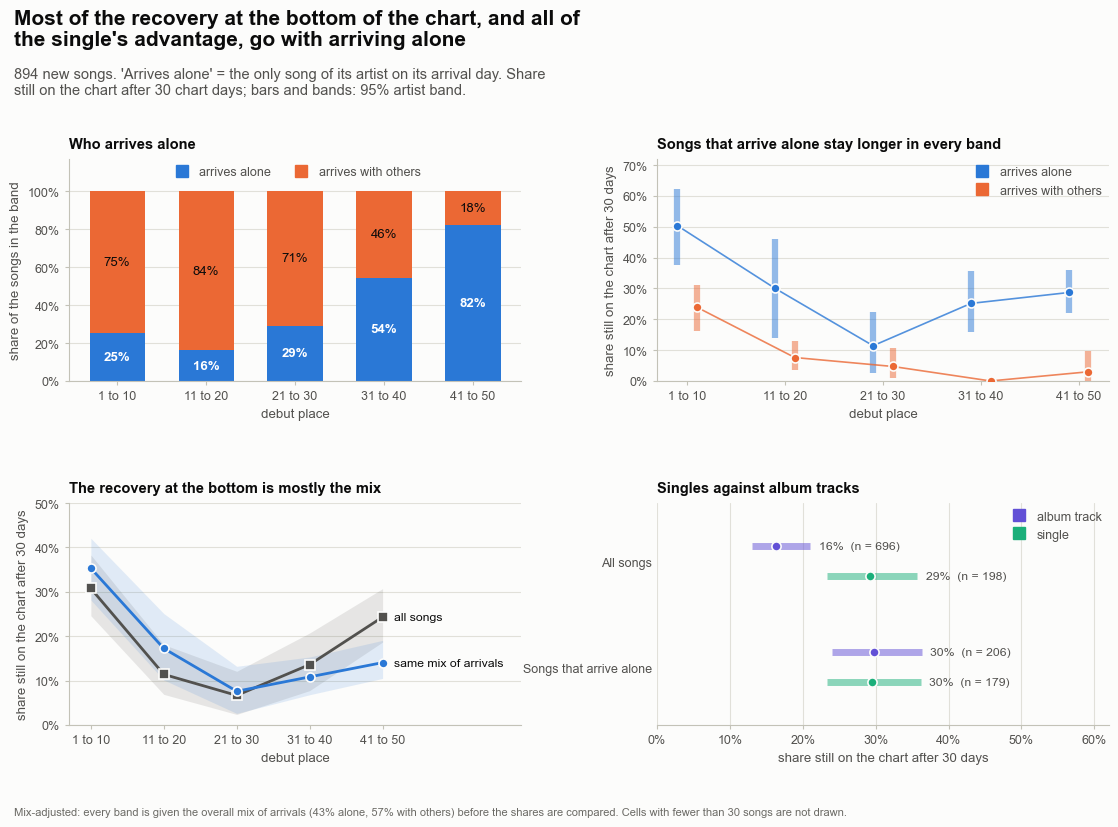

In [15]:
# Figure 06 - the dip and recovery by debut place, and the single, seen through the way a song arrives
recovery_crude = FACTS["deb5_crude"] - FACTS["deb4_crude"]                    # the crude rise from places 31 to 40 to places 41 to 50
recovery_adjusted = FACTS["deb5_adjusted"] - FACTS["deb4_adjusted"]           # the same rise when every band has the same mix of arrivals
FACTS["recovery_crude"], FACTS["recovery_adjusted"] = float(recovery_crude), float(recovery_adjusted)
FACTS["recovery_share_explained"] = float(1 - recovery_adjusted / recovery_crude)

x = np.arange(len(BAND_LABELS))
fig, axes = make_fig(11.8, 8.4, 2, 2, left=0.9, right=0.5, bottom=0.9, hspace=0.55, wspace=0.3, panel_titles=True,
                     title="Most of the recovery at the bottom of the chart, and all of the single's advantage, go with arriving alone",
                     subtitle=f"{FACTS['n_songs']} new songs. 'Arrives alone' = the only song of its artist on its arrival day. Share still on the chart after {HORIZON} chart days; "
                              "bars and bands: 95% artist band.",
                     note_text="Mix-adjusted: every band is given the overall mix of arrivals (" f"{100 * P_ALONE:.0f}% alone, {100 * (1 - P_ALONE):.0f}% with others) before the shares are compared. "
                               "Cells with fewer than 30 songs are not drawn.")
axa, axb, axc, axd = axes[0, 0], axes[0, 1], axes[1, 0], axes[1, 1]

share = DEBUT_TABLE["share_alone"].to_numpy()
axa.bar(x, share, width=0.62, color=style.BLUE)
axa.bar(x, 1 - share, width=0.62, bottom=share, color=style.ORANGE)
for xi, s in zip(x, share):
    axa.text(xi, s / 2, f"{100 * s:.0f}%", ha="center", va="center", color="white", fontsize=9.5, fontweight="bold")
    axa.text(xi, s + (1 - s) / 2, f"{100 * (1 - s):.0f}%", ha="center", va="center", color=style.INK, fontsize=9.5)
axa.set_xticks(x)
axa.set_xticklabels(BAND_LABELS)
axa.yaxis.set_major_formatter(SP.percent_axis)
axa.set_ylim(0, 1.17)
axa.set_ylabel("share of the songs in the band")
axa.set_xlabel("debut place")
swatch_legend(axa, [("arrives alone", style.BLUE), ("arrives with others", style.ORANGE)], loc="upper center", ncol=2)
style_axes(axa, grid="y")
panel_title(axa, "Who arrives alone")

for series, color, dx in [("alone", style.BLUE, -0.1), ("others", style.ORANGE, 0.1)]:
    axb.vlines(x + dx, DEBUT_TABLE[f"{series}_low"], DEBUT_TABLE[f"{series}_high"], color=color, linewidth=4.5, alpha=0.5, zorder=2)
    axb.plot(x + dx, DEBUT_TABLE[series], color=color, linewidth=1.2, alpha=0.8, zorder=3)
    axb.scatter(x + dx, DEBUT_TABLE[series], s=42, color=color, edgecolor=style.SURFACE, linewidth=1.2, zorder=4)
axb.set_xticks(x)
axb.set_xticklabels(BAND_LABELS)
axb.yaxis.set_major_formatter(SP.percent_axis)
axb.set_ylim(0, 0.72)
axb.set_ylabel(f"share still on the chart after {HORIZON} days")
axb.set_xlabel("debut place")
swatch_legend(axb, [("arrives alone", style.BLUE), ("arrives with others", style.ORANGE)], loc="upper right")
style_axes(axb, grid="y")
panel_title(axb, "Songs that arrive alone stay longer in every band")

for series, color, marker, label in [("crude", style.INK_2, "s", "all songs"), ("adjusted", style.BLUE, "o", "same mix of arrivals")]:
    axc.fill_between(x, DEBUT_TABLE[f"{series}_low"], DEBUT_TABLE[f"{series}_high"], color=color, alpha=0.13, linewidth=0, zorder=1)
    axc.plot(x, DEBUT_TABLE[series], color=color, linewidth=2.0, marker=marker, markersize=6.5, markeredgecolor=style.SURFACE, markeredgewidth=1.2, zorder=3)
    direct_label(axc, x[-1] + 0.15, DEBUT_TABLE[series].iloc[-1], label, size=8.8, color=style.INK)
axc.set_xticks(x)
axc.set_xticklabels(BAND_LABELS)
axc.set_xlim(-0.3, x[-1] + 1.9)
axc.yaxis.set_major_formatter(SP.percent_axis)
axc.set_ylim(0, 0.5)
axc.set_ylabel(f"share still on the chart after {HORIZON} days")
axc.set_xlabel("debut place")
style_axes(axc, grid="y")
panel_title(axc, "The recovery at the bottom is mostly the mix")

rows = [("All songs", "album_all", "single_all"), ("Songs that arrive alone", "album_alone", "single_alone")]
for yi, (label, album_key, single_key) in enumerate(rows):
    for key, color, dy in [(album_key, style.ALBUM_COLOR, -0.14), (single_key, style.SINGLE_COLOR, 0.14)]:
        r = SINGLE_ROWS[key]
        axd.hlines(yi + dy, r["low"], r["high"], color=color, linewidth=5.0, alpha=0.5, zorder=2)
        axd.scatter([r["s30"]], [yi + dy], s=44, color=color, edgecolor=style.SURFACE, linewidth=1.2, zorder=4)
        direct_label(axd, r["high"] + 0.012, yi + dy, f"{100 * r['s30']:.0f}%  (n = {r['songs']})", size=8.8, color=style.INK_2)
axd.set_yticks(range(len(rows)))
axd.set_yticklabels([r[0] for r in rows])
axd.set_ylim(len(rows) - 0.45, -0.55)
axd.xaxis.set_major_formatter(SP.percent_axis)
axd.set_xlim(0, 0.62)
axd.set_xlabel(f"share still on the chart after {HORIZON} days")
swatch_legend(axd, [("album track", style.ALBUM_COLOR), ("single", style.SINGLE_COLOR)], loc="upper right")
style_axes(axd, grid="x", left_spine=False)
axd.tick_params(axis="y", length=0)
panel_title(axd, "Singles against album tracks")
save_fig(fig, "p6b_06_alone", FIG_DIR)
plt.show()

**What to notice**

- *Who arrives alone.* At the top of the chart a new song is usually part of a drop: only 25% of the songs that debut in the top 10 arrive alone, and the share is 16% at 11 to 20 and 29% at 21 to 30. It then climbs to 54% at 31 to 40 and 82% at 41 to 50. The bottom of the chart is where lone songs arrive.
- *Alone against with others.* In every band the songs that arrive alone are still on the chart after 30 chart days more often than the songs that arrive with others: 50% against 24% in the top 10, 30% against 8% at 11 to 20, 11% against 5% at 21 to 30, 25% against 0% at 31 to 40 and 29% against 3% at 41 to 50. Among the songs that arrive alone the dip is still there: the share falls from 50% in the top 10 to 11% at 21 to 30, a group of only 35 songs.
- *The mix.* If every band had the overall mix of arrivals, the share still on the chart after 30 chart days would be 35%, 17%, 8%, 11% and 14% from the top 10 to places 41 to 50. The crude rise from the fourth to the fifth band is 11 percentage points, the mix-adjusted rise is 3 percentage points: about 70% of the crude recovery goes with who arrives alone. What is left of it is small, and the artist bands of the fourth and the fifth band overlap, so the data do not show a real recovery. The first step, from the top 10 to places 11 to 20, does not go away: 35% (band 28% to 42%) against 17% (10% to 25%).
- *Singles.* Among all songs, 29% of singles and 16% of album tracks are still on the chart after 30 chart days. But 90% of singles arrive alone (179 of 198) against 30% of album tracks (206 of 696). Among the songs that arrive alone, singles and album tracks are level: 30% against 30%, a difference of +0.8 chart days of 30 (band -1.8 to +3.2; log-rank with artists as the unit p = 0.88). Only 19 singles arrive with others, too few to compare.
- What this does not show. "Arrives alone" is a description of how a song arrived, and a song that arrives alone differs from one that arrives in a drop in many ways (which artist, how well known, how big the release is). The look above holds one thing fixed. Section 6 holds several fixed at once.

## Section 6 - The hazard model: the inputs held against each other

The splits of Section 4 compared groups that differ in many ways at once, and Section 5 showed how easily that misleads. The model of this section asks about one input at a time while the others are held fixed: among songs that are alike in everything else in the model, how does the chance that a chart day is the last one change with this input? The answer is a *hazard ratio*. A ratio of 2.0 means that on every chart day the chance of it being the last is twice as high; 0.5 means half as high; 1.0 means no difference.

Ten inputs are used, all known on the arrival day: the debut place (five bands, the top 10 as the reference); the album drop (how many songs of the same artist arrived on the same day, on a log scale); how many chart days the artist had before (log scale); the artist's usual popularity and a flag for artists who have none yet; whether the artist was on the chart the day before; whether the song is a single, explicit or a collaboration; the length of the song; and its popularity on the arrival day. The number of tracks on the release is left out on purpose, and the reason is shown in this section.

**What this code is.** The day-by-day hazard model and its tests. The table `DAYS` has one row for each chart day of each stay, with a 1 on the last chart day of a finished stay. The model says: the chance that the chart day is the last one equals 1 minus exp(minus exp(*baseline of its age window* plus *the inputs times their coefficients*)). This is the complementary log-log model, the day-by-day form of the Cox model. The baseline is a separate level for each of the nine age windows of Section 3, so no assumption is made about how the hazard falls with age. The exponential of a coefficient is the hazard ratio.

**Why we need it.** To hold the inputs against each other, which the splits cannot do. The day-by-day form uses every chart day, handles the many ties of a daily chart (155 songs leave on their first chart day) without approximation, and gives the baseline hazard its own level at each age. The inputs on a log scale or in standard deviations are made comparable: a numeric input is standardised, so that its hazard ratio means "per one standard deviation".

**What will happen.** The code builds the inputs with `build_design` (the artist's usual popularity is missing for 202 songs, whose artists have no earlier chart days; they get the median and a flag, and the popularity on the debut day, missing for 16 songs, gets the median without a flag, because a flag for so few songs would let the model fit them one by one). It spreads the inputs over the chart days, fits the model with artist-clustered standard errors (the artist is the cluster, p-values and intervals use the t distribution with 229 minus 1 degrees of freedom), tests each input as a block with an F test (so that the four debut-place coefficients are tested together, and the popularity and its flag together), adjusts the ten p-values with Holm, and compares the hazard ratios with those of a Cox model fitted on the stays.

**Expected outcome.** Debut place and album drop clear, with debut places 31 to 40 at about four times the hazard of a top-10 debut and one standard deviation more album drop at about 1.5 times. A lower hazard when the artist was on the chart the day before. Single, explicit, collaboration and song length near 1. The hazard ratios of the Cox model close to those of the day-by-day model.

**Motive.** Find out which of the differences of Sections 4 and 5 are left when the inputs are held against each other, and how sure the data let us be of each.

In [16]:
NUMERIC = {"Album drop": ("log_drop", "raw"),                                # log of the songs by the artist arriving that day
           "Artist's earlier chart days": ("artist_prior_slot_days", "log1p"),
           "Artist's usual popularity": ("artist_prior_mean_pop", "raw"),
           "Song length": ("duration_min", "log1p"),
           "Popularity on the debut day": ("entry_pop", "raw")}
BINARY = {"Single": "is_single", "Explicit": "is_explicit", "Collaboration": "is_collab", "Artist on the chart the day before": "artist_on_chart_prev_day"}
BAND_COLUMNS = [f"Debut place {b}" for b in BAND_LABELS[1:]]
NO_HISTORY = "No usual popularity yet"

FACTS["n_no_history"] = int(STAYS["artist_prior_mean_pop"].isna().sum())
FACTS["n_missing_entry_pop"] = int(STAYS["entry_pop"].isna().sum())
SONG_DESIGN, SCALE = build_design(STAYS, NUMERIC, BINARY, flag_from=50)      # flag_from=50: a missing-value flag only when 50 or more songs are missing
SONG_DESIGN = SONG_DESIGN.rename(columns={"Artist's usual popularity (missing)": NO_HISTORY})
bands = pd.get_dummies(STAYS["debut_band"].astype(str)).reindex(columns=BAND_LABELS[1:], fill_value=0).astype(float)
bands.columns = BAND_COLUMNS
INPUT_ORDER = BAND_COLUMNS + ["Album drop", "Artist's earlier chart days", "Artist's usual popularity", NO_HISTORY, "Artist on the chart the day before",
                              "Single", "Explicit", "Collaboration", "Song length", "Popularity on the debut day"]
SONG_X = pd.concat([bands, SONG_DESIGN.drop(columns="Intercept")], axis=1)[INPUT_ORDER]
assert np.isfinite(SONG_X.to_numpy()).all()

# every chart day of every stay gets the inputs of its song and the age-window columns of the baseline
SONG_ROW = pd.Index(STAYS["track_id"]).get_indexer(DAYS["track_id"])         # for each chart day: the row of its song in STAYS
assert (SONG_ROW >= 0).all()
DAY_ARTIST = ARTISTS[SONG_ROW]                                               # the cluster of each chart day
DAY_Y = DAYS["event"].to_numpy()
BASELINE = window_columns(DAYS["age"].to_numpy(), AGE_EDGES)                 # the nine age windows: the baseline of the model
BASELINE_NAMES = list(BASELINE.columns)


def day_by_day(columns, extra=None):
    """Fit the model with the chosen song-level inputs (and optional extra song-level columns); return the fit and the column names."""
    frame = SONG_X[columns] if extra is None else pd.concat([SONG_X[columns], extra], axis=1)
    design = pd.concat([BASELINE, pd.DataFrame(frame.to_numpy()[SONG_ROW], columns=list(frame.columns))], axis=1)
    return fit_cloglog(DAY_Y, design.to_numpy(), clusters=DAY_ARTIST), list(design.columns)


MAIN, MAIN_NAMES = day_by_day(INPUT_ORDER)
assert MAIN.converged, "the main model did not converge"
hr, hr_low, hr_high = MAIN.hazard_ratios()
p_coef = MAIN.p_values()
FACTS["n_artists_model"] = int(MAIN.groups)
FACTS["model_rows"], FACTS["model_events"], FACTS["model_coefficients"] = int(MAIN.n), int(DAY_Y.sum()), int(MAIN.k)
FACTS["model_iterations"] = int(MAIN.iterations)

KEYS = {"Debut place 11 to 20": "b2", "Debut place 21 to 30": "b3", "Debut place 31 to 40": "b4", "Debut place 41 to 50": "b5", "Album drop": "drop",
        "Artist's earlier chart days": "earlier", "Artist's usual popularity": "usualpop", NO_HISTORY: "nohist", "Artist on the chart the day before": "onchart",
        "Single": "single", "Explicit": "explicit", "Collaboration": "collab", "Song length": "length", "Popularity on the debut day": "debutpop"}
rows = []
for name in INPUT_ORDER:
    i = MAIN_NAMES.index(name)
    rows.append({"input": name, "hazard_ratio": hr[i], "low": hr_low[i], "high": hr_high[i], "p": p_coef[i]})
    key = KEYS[name]
    FACTS[f"hr_{key}"], FACTS[f"hr_{key}_low"], FACTS[f"hr_{key}_high"], FACTS[f"hr_{key}_p"] = float(hr[i]), float(hr_low[i]), float(hr_high[i]), float(p_coef[i])
    FACTS[f"hr_{key}_p_text"] = format_p(p_coef[i])

# what one standard deviation means, in the units of each input
sd = dict(zip(SCALE["input"], SCALE["sd"]))                                  # one standard deviation of each numeric input, on the scale it enters the model
FACTS["sd_drop_factor"] = float(np.exp(sd["Album drop"]))                    # the inputs on a log scale: one SD is a multiplication by this factor
FACTS["sd_earlier_factor"] = float(np.exp(sd["Artist's earlier chart days"]))
FACTS["sd_length_factor"] = float(np.exp(sd["Song length"]))
FACTS["sd_usualpop_points"] = float(sd["Artist's usual popularity"])         # the inputs on their own scale: one SD is this many popularity points
FACTS["sd_debutpop_points"] = float(sd["Popularity on the debut day"])
UNIT = {name: "compared with a top-10 debut" for name in BAND_COLUMNS}
UNIT["Album drop"] = f"per 1 SD = a drop {FACTS['sd_drop_factor']:.1f} times as large"
UNIT["Artist's earlier chart days"] = f"per 1 SD = {FACTS['sd_earlier_factor']:.1f} times as many days"
UNIT["Artist's usual popularity"] = f"per 1 SD = {FACTS['sd_usualpop_points']:.0f} popularity points"
UNIT["Song length"] = f"per 1 SD = {FACTS['sd_length_factor']:.2f} times as long"
UNIT["Popularity on the debut day"] = f"per 1 SD = {FACTS['sd_debutpop_points']:.0f} popularity points"
for name in [NO_HISTORY, "Artist on the chart the day before", "Explicit", "Collaboration"]:
    UNIT[name] = "yes against no"
UNIT["Single"] = "single against album"
HR_TABLE = pd.DataFrame(rows)
HR_TABLE["unit"] = HR_TABLE["input"].map(UNIT)
display(HR_TABLE.assign(**{"hazard ratio (95% interval)": [f"{a:.2f}  ({b:.2f} to {c:.2f})" for a, b, c in zip(HR_TABLE["hazard_ratio"], HR_TABLE["low"], HR_TABLE["high"])],
                           "p": [format_p(p) for p in HR_TABLE["p"]]})[["input", "unit", "hazard ratio (95% interval)", "p"]].set_index("input"))
print(f"{MAIN.n:,} chart days, {int(DAY_Y.sum())} exits, {MAIN.k} coefficients ({len(BASELINE_NAMES)} of them the age-window baseline), {MAIN.groups} artists; {MAIN.iterations} iterations.")

# ---- each input as a block: one F test, ten tests in all, adjusted together
BLOCKS = [("Debut place", BAND_COLUMNS), ("Album drop", ["Album drop"]), ("Artist's earlier chart days", ["Artist's earlier chart days"]),
          ("Artist's usual popularity", ["Artist's usual popularity", NO_HISTORY]), ("Artist on the chart the day before", ["Artist on the chart the day before"]),
          ("Single", ["Single"]), ("Explicit", ["Explicit"]), ("Collaboration", ["Collaboration"]), ("Song length", ["Song length"]),
          ("Popularity on the debut day", ["Popularity on the debut day"])]
BLOCK_KEY = {"Debut place": "band", "Album drop": "drop", "Artist's earlier chart days": "earlier", "Artist's usual popularity": "usualpop",
             "Artist on the chart the day before": "onchart", "Single": "single", "Explicit": "explicit", "Collaboration": "collab", "Song length": "length",
             "Popularity on the debut day": "debutpop"}
block_rows = []
for block_name, columns in BLOCKS:
    test = wald_test(MAIN, selection(MAIN_NAMES, columns))
    block_rows.append({"input": block_name, "coefficients": len(columns), "F": test["stat"], "df1": test["q"], "df2": test["df"], "p": test["p"]})
BLOCK_TABLE = pd.DataFrame(block_rows)
BLOCK_TABLE["p_holm"] = holm(BLOCK_TABLE["p"].to_numpy())
for row in BLOCK_TABLE.itertuples():
    key = BLOCK_KEY[row.input]
    FACTS[f"blk_{key}_F"], FACTS[f"blk_{key}_p"], FACTS[f"blk_{key}_p_holm"] = float(row.F), float(row.p), float(row.p_holm)
    FACTS[f"blk_{key}_p_text"], FACTS[f"blk_{key}_p_holm_text"] = format_p(row.p), format_p(row.p_holm)
FACTS["n_inputs"] = len(BLOCK_TABLE)
FACTS["n_inputs_clear"] = int((BLOCK_TABLE["p_holm"] < 0.05).sum())
FACTS["inputs_clear"] = ", ".join(BLOCK_TABLE.loc[BLOCK_TABLE["p_holm"] < 0.05, "input"].str.lower())
display(BLOCK_TABLE.assign(F=lambda d: d["F"].round(2), p=[format_p(p) for p in BLOCK_TABLE["p"]], after_Holm=[format_p(p) for p in BLOCK_TABLE["p_holm"]]).drop(columns="p_holm").set_index("input"))

# ---- how much the artist-aware standard errors differ from the textbook ones
ratio = MAIN.se / np.sqrt(np.diag(MAIN.model_cov))
song_level = [MAIN_NAMES.index(name) for name in INPUT_ORDER]
FACTS["se_ratio_median"], FACTS["se_ratio_max"] = float(np.median(ratio[song_level])), float(np.max(ratio[song_level]))
FACTS["se_ratio_argmax"] = INPUT_ORDER[int(np.argmax(ratio[song_level]))]

# ---- a Cox model on the stays must give nearly the same hazard ratios
COX = fit_cox(T, E, SONG_X.to_numpy(), ridge=0.0)
cox_hr = np.exp(COX.coef)
FACTS["cox_max_gap"] = float(np.max(np.abs(cox_hr - hr[[MAIN_NAMES.index(n) for n in INPUT_ORDER]])))
FACTS["cox_median_gap"] = float(np.median(np.abs(cox_hr - hr[[MAIN_NAMES.index(n) for n in INPUT_ORDER]])))
print(f"Artist-aware standard errors are {FACTS['se_ratio_median']:.2f} times the textbook ones (median over the inputs), up to {FACTS['se_ratio_max']:.2f} times for {FACTS['se_ratio_argmax'].lower()}.")
print(f"A Cox model on the stays gives hazard ratios within {FACTS['cox_max_gap']:.3f} of the day-by-day model (median gap {FACTS['cox_median_gap']:.3f}).")

,unit,hazard ratio (95% interval),p
input,,,
Debut place 11 to 20,compared with a top-10 debut,1.87 (1.61 to 2.17),p < 0.001
Debut place 21 to 30,compared with a top-10 debut,2.93 (2.15 to 3.99),p < 0.001
Debut place 31 to 40,compared with a top-10 debut,4.22 (3.05 to 5.83),p < 0.001
Debut place 41 to 50,compared with a top-10 debut,3.05 (2.19 to 4.25),p < 0.001
Album drop,per 1 SD = a drop 3.8 times as large,1.48 (1.20 to 1.83),p < 0.001
Artist's earlier chart days,per 1 SD = 10.8 times as many days,0.91 (0.70 to 1.18),p = 0.48
Artist's usual popularity,per 1 SD = 6 popularity points,0.95 (0.84 to 1.09),p = 0.48
No usual popularity yet,yes against no,0.61 (0.35 to 1.09),p = 0.094
Artist on the chart the day before,yes against no,0.72 (0.50 to 1.04),p = 0.082


19,404 chart days, 835 exits, 23 coefficients (9 of them the age-window baseline), 229 artists; 8 iterations.


,coefficients,F,df1,df2,p,after_Holm
input,,,,,,
Debut place,4,24.77,4,228,p < 0.001,p < 0.001
Album drop,1,13.78,1,228,p < 0.001,p = 0.002
Artist's earlier chart days,1,0.51,1,228,p = 0.48,p = 1.00
Artist's usual popularity,2,3.3,2,228,p = 0.039,p = 0.31
Artist on the chart the day before,1,3.05,1,228,p = 0.082,p = 0.49
Single,1,0.01,1,228,p = 0.94,p = 1.00
Explicit,1,0.31,1,228,p = 0.58,p = 1.00
Collaboration,1,0.1,1,228,p = 0.75,p = 1.00
Song length,1,2.38,1,228,p = 0.12,p = 0.62


Artist-aware standard errors are 1.32 times the textbook ones (median over the inputs), up to 2.02 times for artist on the chart the day before.
A Cox model on the stays gives hazard ratios within 0.051 of the day-by-day model (median gap 0.003).


**What this code is.** The check on the single, in five versions of the model. Version 1 has the single as its only input (besides the age baseline). Versions 2 and 3 add the debut place and then the album drop. Version 4 is the main model above. Version 5 adds the number of tracks on the release to the main model, which the main model leaves out.

**Why we need it.** Section 5 saw that the single's advantage went away among songs that arrive alone. This cell asks the same question of the model and answers a second one: why is the number of tracks not an input? A single has one to three tracks and an album more, so "single" and "number of tracks" say nearly the same thing about a song (their correlation is -0.94). When two inputs carry almost the same information a model cannot tell which of them does the work, and the coefficients of the two become large, opposite and unstable. A model with both looks as if it had found something, and it has not.

**What will happen.** The code fits the five models with the same artist-clustered method, takes the hazard ratio of the single in each, and prints a small table. For version 5 it also prints the hazard ratio of the number of tracks.

**Expected outcome.** The hazard ratio of the single starts below 1 (about 0.75: a single leaves later than an album track), stays there when the debut place is added, moves to about 1.0 once the album drop is in, and is still about 1.0 in the main model. In version 5 it jumps to more than 2 and the track count has a hazard ratio far from 1: the two inputs fight over one piece of information.

**Motive.** Show why the main model does not carry the number of tracks, and that the single's lower hazard is explained by how the single arrives.

In [17]:
tracks = np.log1p(STAYS["total_tracks"].astype(float).to_numpy())
tracks = np.where(np.isnan(tracks), np.nanmedian(tracks), tracks)
tracks_z = (tracks - tracks.mean()) / tracks.std(ddof=1)                      # tracks on the release: log scale, standardised like the other inputs
FACTS["corr_single_tracks"] = float(np.corrcoef(STAYS["is_single"].to_numpy().astype(float), tracks)[0, 1])   # between the single flag and the log of the track count

LADDER_FITS = [("1. Single alone", ["Single"], None),
               ("2. + debut place", ["Single"] + BAND_COLUMNS, None),
               ("3. + album drop", ["Single"] + BAND_COLUMNS + ["Album drop"], None),
               ("4. the main model (all ten inputs)", INPUT_ORDER, None),
               ("5. main model + tracks on the release", INPUT_ORDER, pd.DataFrame({"Tracks on the release": tracks_z}))]
SINGLE_LADDER = []
for k, (label, columns, extra) in enumerate(LADDER_FITS, start=1):
    fit, names = day_by_day(columns, extra)
    a, b, c = fit.hazard_ratios()
    i = names.index("Single")
    row = {"version": label, "hazard_ratio": float(a[i]), "low": float(b[i]), "high": float(c[i]), "converged": fit.converged}
    if extra is not None:
        j = names.index("Tracks on the release")
        row.update({"tracks_hazard_ratio": float(a[j]), "tracks_low": float(b[j]), "tracks_high": float(c[j])})
        FACTS["tracks_hr"], FACTS["tracks_hr_low"], FACTS["tracks_hr_high"] = row["tracks_hazard_ratio"], row["tracks_low"], row["tracks_high"]
    SINGLE_LADDER.append(row)
    FACTS[f"ladder{k}_single_hr"], FACTS[f"ladder{k}_single_low"], FACTS[f"ladder{k}_single_high"] = row["hazard_ratio"], row["low"], row["high"]
LADDER_TABLE = pd.DataFrame(SINGLE_LADDER)
display(LADDER_TABLE.assign(**{"hazard ratio of the single (95% interval)": [f"{a:.2f}  ({b:.2f} to {c:.2f})" for a, b, c in zip(LADDER_TABLE["hazard_ratio"], LADDER_TABLE["low"], LADDER_TABLE["high"])],
                               "hazard ratio of the track count": [f"{a:.2f}  ({b:.2f} to {c:.2f})" if a == a else "" for a, b, c in
                                                                    zip(LADDER_TABLE["tracks_hazard_ratio"], LADDER_TABLE["tracks_low"], LADDER_TABLE["tracks_high"])]})
        [["version", "hazard ratio of the single (95% interval)", "hazard ratio of the track count"]].set_index("version"))

FACTS["ladder_width_ratio"] = float(np.log(FACTS["ladder5_single_high"] / FACTS["ladder5_single_low"]) / np.log(FACTS["ladder4_single_high"] / FACTS["ladder4_single_low"]))

,hazard ratio of the single (95% interval),hazard ratio of the track count
version,,
1. Single alone,0.75 (0.63 to 0.90),
2. + debut place,0.72 (0.60 to 0.87),
3. + album drop,0.99 (0.79 to 1.25),
4. the main model (all ten inputs),1.01 (0.81 to 1.26),
5. main model + tracks on the release,2.32 (1.21 to 4.47),1.49 (1.13 to 1.97)


**What to notice**

- On its own the single goes with a lower hazard: 0.75 (0.63 to 0.90), a chart day of a single is about a quarter less likely to be its last than one of an album track. Adding the debut place changes little (0.72). Adding the album drop takes it to 0.99 (0.79 to 1.25), and the rest of the inputs leave it at 1.01 (0.81 to 1.26). That is the answer of Section 5 given by the model: the single's advantage is how singles arrive, mostly alone.
- Version 5 shows the trap. With the track count in the model the single's hazard ratio becomes 2.32 (1.21 to 4.47) and the track count's 1.49 (1.13 to 1.97). This is not a finding that singles are twice as risky. The single flag and the track count are almost the same information (correlation -0.94), the model cannot say which of them carries the effect, and the interval of the single becomes about 2.9 times as wide on the log scale. This is the reason that the main model leaves the track count out.

**What this code is.** Figure 7. The hazard ratios of the main model as a forest plot: one row for each of the fourteen coefficients, a dot for the hazard ratio, a bar for its 95% interval on a log scale, and a line at 1. A dot is *open* when the interval includes 1.

**Why we need it.** A table of fourteen hazard ratios is easy to misread, and the chart puts the sizes and the doubts in one view: which inputs are far from 1, which are close to it, and how wide each interval is. On a log scale a ratio of 2 and a ratio of one half are the same distance from 1 on either side, which is the honest way to draw ratios.

**What will happen.** The code draws the rows grouped by input, writes the hazard ratio with its interval to the right of each row and the Holm-adjusted p-value of the whole block of the input at the far right, and notes what one standard deviation means for each numeric input. It saves the picture as `p6b_07_hazard_ratios.png`.

**Expected outcome.** The four debut-place rows far to the right of 1 with filled dots, the album drop to the right of 1 and also filled. Everything else with an interval that crosses 1 (open dots), most of them close to it. Three of the inputs (the artist on the chart the day before, the missing-popularity flag, and the popularity on the debut day) lean below 1 with wide intervals.

**Motive.** Show, in one picture, what the model finds and what it does not.

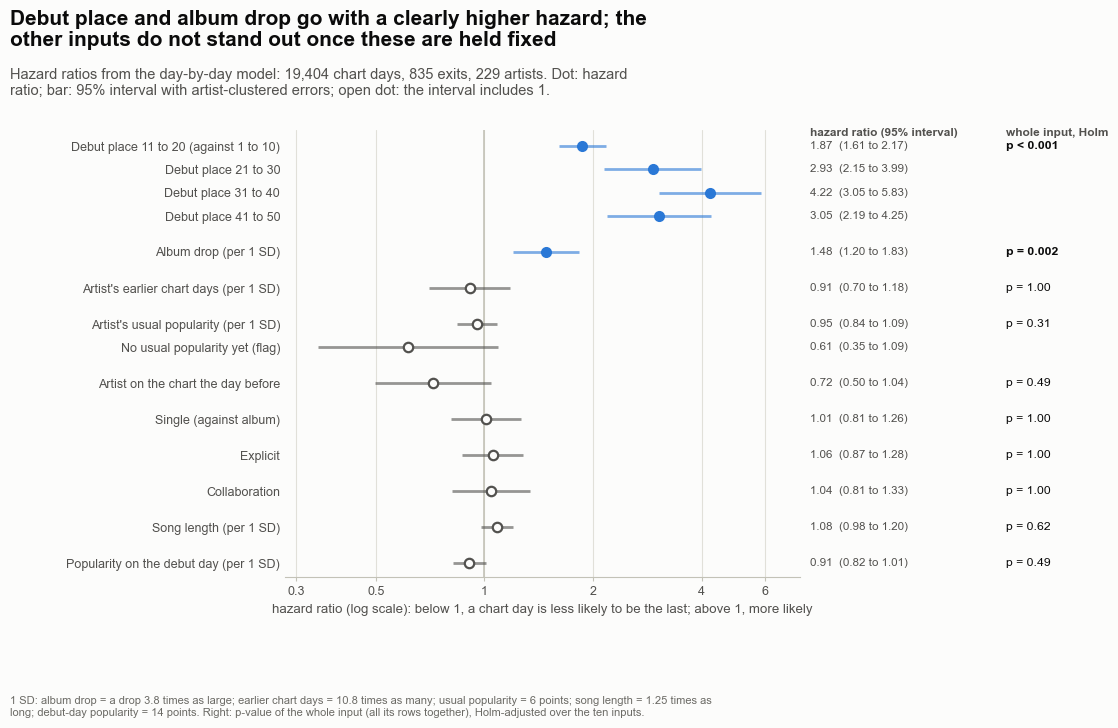

In [18]:
# Figure 07 - hazard ratios of the main model
labels = list(INPUT_ORDER)
pretty = {"Album drop": "Album drop (per 1 SD)", "Artist's earlier chart days": "Artist's earlier chart days (per 1 SD)", "Artist's usual popularity": "Artist's usual popularity (per 1 SD)",
          "Song length": "Song length (per 1 SD)", "Popularity on the debut day": "Popularity on the debut day (per 1 SD)", "Single": "Single (against album)",
          "Debut place 11 to 20": "Debut place 11 to 20 (against 1 to 10)", "Debut place 21 to 30": "Debut place 21 to 30", "Debut place 31 to 40": "Debut place 31 to 40",
          "Debut place 41 to 50": "Debut place 41 to 50"}
y_forest, y_now, block_start = [], 0.0, {}
previous_block = None
block_of = {column: block for block, columns in BLOCKS for column in columns}
for name in labels:
    if block_of[name] != previous_block and previous_block is not None:
        y_now += 0.55
    y_forest.append(y_now)
    y_now += 1.0
    previous_block = block_of[name]
fig, ax = make_fig(11.8, 7.4, 1, 1, left=3.1, right=3.55, bottom=1.25,
                   title="Debut place and album drop go with a clearly higher hazard; the other inputs do not stand out once these are held fixed",
                   subtitle=f"Hazard ratios from the day-by-day model: {FACTS['model_rows']:,} chart days, {FACTS['model_events']} exits, {FACTS['n_artists_model']} artists. Dot: hazard ratio; "
                            "bar: 95% interval with artist-clustered errors; open dot: the interval includes 1.",
                   note_text=f"1 SD: album drop = a drop {FACTS['sd_drop_factor']:.1f} times as large; earlier chart days = {FACTS['sd_earlier_factor']:.1f} times as many; usual popularity = "
                             f"{FACTS['sd_usualpop_points']:.0f} points; song length = {FACTS['sd_length_factor']:.2f} times as long; debut-day popularity = {FACTS['sd_debutpop_points']:.0f} points. "
                             "Right: p-value of the whole input (all its rows together), Holm-adjusted over the ten inputs.")
hr_by_name = {row.input: row for row in HR_TABLE.itertuples()}
estimates = [hr_by_name[n].hazard_ratio for n in labels]
colors = [style.BLUE if block_of[n] in ("Debut place", "Album drop") else style.INK_2 for n in labels]
MP.draw_forest(ax, y_forest, estimates, [hr_by_name[n].low for n in labels], [hr_by_name[n].high for n in labels], colors=colors, reference=1.0, log=True,
               texts=[f"{hr_by_name[n].hazard_ratio:.2f}  ({hr_by_name[n].low:.2f} to {hr_by_name[n].high:.2f})" for n in labels], text_x=1.02)
holm_by_block = dict(zip(BLOCK_TABLE["input"], BLOCK_TABLE["p_holm"]))
seen = set()
for name, y_value in zip(labels, y_forest):
    block = block_of[name]
    if block not in seen:
        seen.add(block)
        ax.text(1.4, y_value, format_p(holm_by_block[block]), transform=ax.get_yaxis_transform(), ha="left", va="center", fontsize=8.8,
                color=style.INK, fontweight="bold" if holm_by_block[block] < 0.05 else "normal")
ax.set_yticks(y_forest)
ax.set_yticklabels([pretty.get(n, n) if n != NO_HISTORY else "No usual popularity yet (flag)" for n in labels], fontsize=9)
ax.set_ylim(y_now - 0.4, -0.7)
ax.set_xlim(0.28, 7.5)
ax.set_xticks([0.3, 0.5, 1, 2, 4, 6])
ax.set_xticklabels(["0.3", "0.5", "1", "2", "4", "6"])
ax.minorticks_off()
ax.set_xlabel("hazard ratio (log scale): below 1, a chart day is less likely to be the last; above 1, more likely")
ax.text(1.02, -0.58, "hazard ratio (95% interval)", transform=ax.get_yaxis_transform(), ha="left", va="center", fontsize=8.6, color=style.INK_2, fontweight="bold")
ax.text(1.4, -0.58, "whole input, Holm", transform=ax.get_yaxis_transform(), ha="left", va="center", fontsize=8.6, color=style.INK_2, fontweight="bold")
save_fig(fig, "p6b_07_hazard_ratios", FIG_DIR)
plt.show()

**What to notice**

- *Debut place.* All four hazard ratios are above 1 and their intervals are clear of it: 1.87 (1.61 to 2.17) at 11 to 20, 2.93 (2.15 to 3.99) at 21 to 30, 4.22 (3.05 to 5.83) at 31 to 40 and 3.05 (2.19 to 4.25) at 41 to 50. A chart day of a song that debuted at 31 to 40 is about 4 times as likely to be its last as one of a song that debuted in the top 10 with the same album drop, artist history, popularity and the rest. The ratio climbs from the top 10 to places 31 to 40; the dip at 41 to 50 is smaller than the width of the intervals, so the data do not show that debuts at 41 to 50 do better than those at 31 to 40. As a block, debut place has p < 0.001 after the Holm adjustment.
- *Album drop.* One standard deviation more (a drop 3.8 times as large) goes with a hazard 1.48 times as high on every chart day (interval 1.20 to 1.83; p = 0.002 after Holm). This is the input that absorbed the single's advantage.
- *Everything else.* Only 2 of the 10 inputs are clear after the Holm adjustment: debut place, album drop. The others are not: the artist's earlier chart days (0.91), the artist's usual popularity (0.95), single (1.01), explicit (1.06), collaboration (1.04) and song length (1.08) are all close to 1 with intervals that include it. Three lean below 1: the artist on the chart the day before (0.72, 0.50 to 1.04), no usual popularity yet (0.61, 0.35 to 1.09) and the popularity on the debut day (0.91, 0.82 to 1.01). They are suggestions, not findings: the intervals touch or include 1 and none survives the adjustment for ten inputs.
- *How sure.* The artist-aware standard errors are 1.32 times the textbook ones for the typical input (the median), and up to 2.02 times for the input "Artist on the chart the day before", which the songs of one artist mostly share. A Cox model fitted on the stays gives hazard ratios within 0.051 of these (median gap 0.003), so the result does not depend on the day-by-day form.
- *What "held fixed" means.* The hazard ratios compare songs that are alike in the other nine inputs. They describe these 894 songs; they do not say what would happen to a song if one of its inputs were changed.

**What this code is.** The check that each hazard ratio is the same at every age. The model above gives an input one hazard ratio for all chart days. That is the *proportional hazards* assumption, and it can be wrong: the album drop might matter on the first three chart days and not afterwards. The code splits the chart days into three age windows (chart days 1 to 3, 4 to 14, and 15 and later) and, one input at a time, lets that input have its own hazard ratio in each window while the others keep one.

**Why we need it.** If a hazard ratio changes with age, the single number of Figure 7 is an average of different things, and it can mislead. The check says which inputs are safe to summarise with one number, and the separate ratios say how an input works at each stage of a stay. The three windows hold 326, 286 and 223 exits, enough for each to carry its own estimates.

**What will happen.** For each of the ten inputs the code builds a design in which the input's columns are replaced by one column per window (`window_interactions`), fits the model, and tests that the effects are the same in all three windows (an F test with the artist-clustered covariance; the debut place has four columns and so eight contrasts). The ten p-values are adjusted with Holm. The window-specific hazard ratios, with their intervals, are kept for Figure 8.

**Expected outcome.** A few inputs whose ratios change with age, and most that do not. Where the effect changes, it should be easiest to see for the debut place and the album drop, which have the strongest effects.

**Motive.** Know where "one hazard ratio for the whole stay" is a fair summary and where it is not.

In [19]:
PH_EDGES = [0, 3, 14, 10_000]                                                # chart days 1 to 3, 4 to 14, 15 and later
PH_LABELS = ["chart days 1 to 3", "chart days 4 to 14", "chart day 15 and later"]
PH_WINDOW = age_windows(DAYS["age"].to_numpy(), PH_EDGES)
N_PH = len(PH_LABELS)
for k in range(N_PH):
    FACTS[f"ph_events_{k + 1}"] = int(DAY_Y[PH_WINDOW == k].sum())
FACTS["ph_n_windows"] = N_PH

FULL_DESIGN = pd.concat([BASELINE, pd.DataFrame(SONG_X.to_numpy()[SONG_ROW], columns=INPUT_ORDER)], axis=1)
PH_TESTS, AGE_EFFECTS = [], []
for block_name, columns in BLOCKS:
    split_design = window_interactions(FULL_DESIGN, columns, PH_WINDOW, N_PH)
    split_fit = fit_cloglog(DAY_Y, split_design.to_numpy(), clusters=DAY_ARTIST)
    assert split_fit.converged, f"the model with separate effects for {block_name} did not converge"
    split_names = list(split_design.columns)
    test = wald_test(split_fit, equal_effects_contrasts(split_names, columns, N_PH))
    PH_TESTS.append({"input": block_name, "F": test["stat"], "df1": test["q"], "df2": test["df"], "p": test["p"]})
    a, b, c = split_fit.hazard_ratios()
    for column in columns:
        for k in range(N_PH):
            i = split_names.index(f"{column} @ {k + 1}")
            AGE_EFFECTS.append({"input": column, "block": block_name, "window": PH_LABELS[k], "window_number": k + 1, "hazard_ratio": float(a[i]), "low": float(b[i]), "high": float(c[i])})
PH_TABLE = pd.DataFrame(PH_TESTS)
PH_TABLE["p_holm"] = holm(PH_TABLE["p"].to_numpy())
AGE_TABLE = pd.DataFrame(AGE_EFFECTS)
for row in PH_TABLE.itertuples():
    key = BLOCK_KEY[row.input]
    FACTS[f"ph_{key}_F"], FACTS[f"ph_{key}_p"], FACTS[f"ph_{key}_p_holm"] = float(row.F), float(row.p), float(row.p_holm)
    FACTS[f"ph_{key}_p_text"], FACTS[f"ph_{key}_p_holm_text"] = format_p(row.p), format_p(row.p_holm)
for row in AGE_TABLE.itertuples():
    key = KEYS[row.input]
    FACTS[f"age_{key}_{row.window_number}"], FACTS[f"age_{key}_{row.window_number}_low"], FACTS[f"age_{key}_{row.window_number}_high"] = row.hazard_ratio, row.low, row.high
FACTS["ph_n_inputs"] = len(PH_TABLE)
FACTS["ph_n_flagged"] = int((PH_TABLE["p_holm"] < 0.05).sum())
FACTS["ph_flagged"] = ", ".join(PH_TABLE.loc[PH_TABLE["p_holm"] < 0.05, "input"].str.lower()) or "none"
display(PH_TABLE.assign(F=lambda d: d["F"].round(2), p=[format_p(p) for p in PH_TABLE["p"]], after_Holm=[format_p(p) for p in PH_TABLE["p_holm"]]).drop(columns="p_holm").set_index("input"))
display(AGE_TABLE.assign(**{"hazard ratio (95% interval)": [f"{a:.2f}  ({b:.2f} to {c:.2f})" for a, b, c in zip(AGE_TABLE["hazard_ratio"], AGE_TABLE["low"], AGE_TABLE["high"])]})
        .pivot(index="input", columns="window", values="hazard ratio (95% interval)").reindex(INPUT_ORDER)[PH_LABELS])

,F,df1,df2,p,after_Holm
input,,,,,
Debut place,9.01,8,228,p < 0.001,p < 0.001
Album drop,15.97,2,228,p < 0.001,p < 0.001
Artist's earlier chart days,28.74,2,228,p < 0.001,p < 0.001
Artist's usual popularity,7.84,4,228,p < 0.001,p < 0.001
Artist on the chart the day before,12.94,2,228,p < 0.001,p < 0.001
Single,3.12,2,228,p = 0.046,p = 0.23
Explicit,0.03,2,228,p = 0.97,p = 1.00
Collaboration,0.14,2,228,p = 0.87,p = 1.00
Song length,1.18,2,228,p = 0.31,p = 0.93


window,chart days 1 to 3,chart days 4 to 14,chart day 15 and later
input,,,
Debut place 11 to 20,2.96 (1.77 to 4.94),1.97 (1.50 to 2.60),1.87 (1.30 to 2.71)
Debut place 21 to 30,5.77 (2.92 to 11.40),3.22 (2.10 to 4.94),1.83 (1.06 to 3.15)
Debut place 31 to 40,12.93 (7.45 to 22.44),1.66 (0.95 to 2.90),3.20 (1.73 to 5.90)
Debut place 41 to 50,10.93 (6.22 to 19.20),1.51 (0.99 to 2.29),1.81 (1.08 to 3.03)
Album drop,1.10 (0.74 to 1.63),2.05 (1.59 to 2.64),1.69 (1.31 to 2.19)
Artist's earlier chart days,0.65 (0.45 to 0.93),1.15 (0.81 to 1.64),1.09 (0.86 to 1.39)
Artist's usual popularity,0.80 (0.71 to 0.91),0.93 (0.78 to 1.11),1.28 (1.04 to 1.56)
No usual popularity yet,1.28 (0.67 to 2.45),0.32 (0.16 to 0.62),0.49 (0.25 to 0.98)
Artist on the chart the day before,0.37 (0.24 to 0.57),1.36 (0.91 to 2.06),0.99 (0.60 to 1.61)


**What this code is.** Figure 8. The hazard ratios of Figure 7 split by age: for every input three dots with their 95% intervals, one for each age window (chart days 1 to 3, 4 to 14, 15 and later). A line at 1, as before. At the right, the p-value of the test that the three are equal.

**Why we need it.** If the ratios of an input differ from window to window, one number cannot describe the whole stay. The figure shows which inputs behave the same at every age and which change, and how.

**What will happen.** The code draws, for every input, three intervals one above the other, coloured by window (a blue ramp from light for the first three chart days to dark for day 15 and later), on a log scale. It writes the Holm-adjusted p-value of the equality test next to each input, in bold when it is below 0.05. It saves the picture as `p6b_08_effects_by_age.png`.

**Expected outcome.** The intervals of the flat inputs (explicit, collaboration, single, song length, debut-day popularity) lie on top of each other around 1. For debut place, album drop and the three inputs about the artist's history the dots of the three windows are visibly apart.

**Motive.** Show where the one hazard ratio per input in Figure 7 hides a change with age, which is the most important caveat of the model.

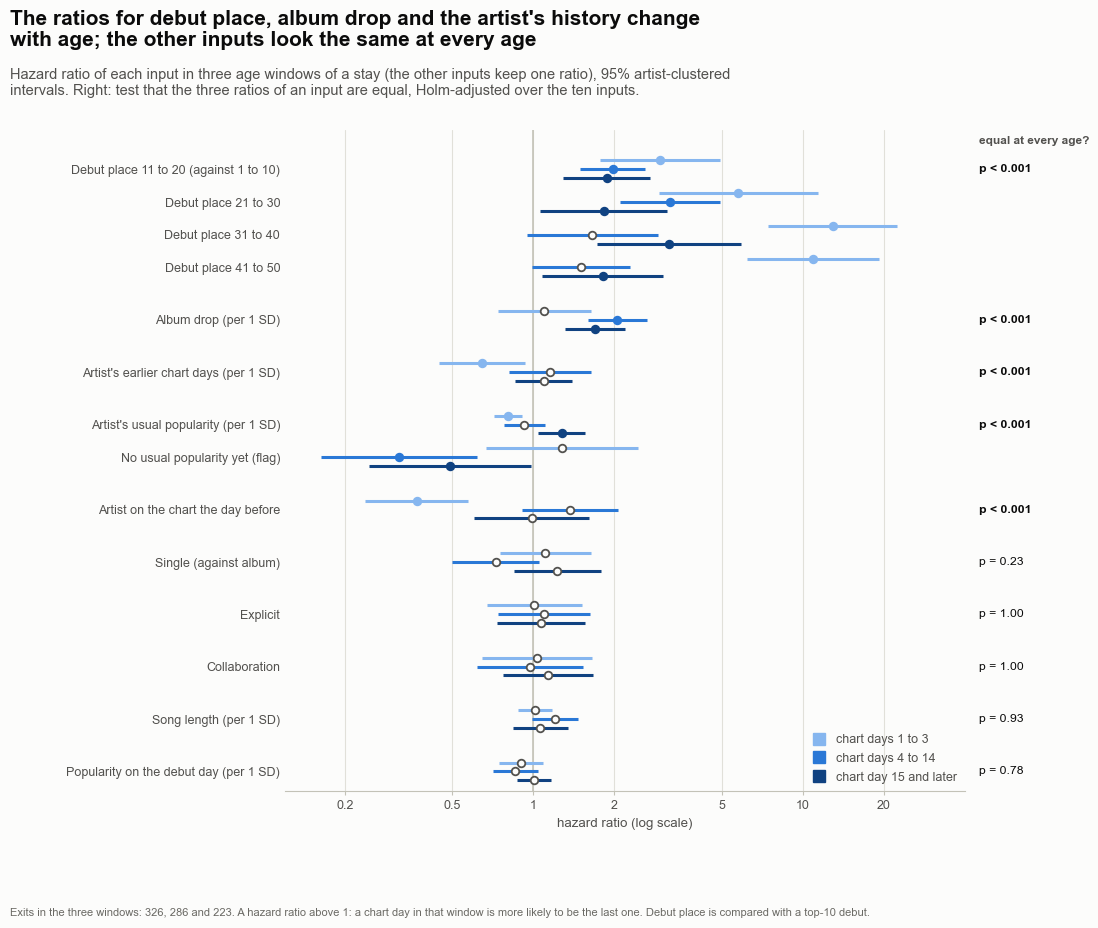

In [20]:
# Figure 08 - hazard ratios by age window
ramp = MP.step_colors(3)                                                      # light for the first chart days, dark for the long stays
rows_y, y_now, previous_block = {}, 0.0, None
for name in INPUT_ORDER:
    if previous_block is not None and block_of[name] != previous_block:
        y_now += 0.6
    rows_y[name] = y_now
    y_now += 1.0
    previous_block = block_of[name]

fig, ax = make_fig(11.8, 9.4, 1, 1, left=3.1, right=1.9, bottom=1.25,
                   title="The ratios for debut place, album drop and the artist's history change with age; the other inputs look the same at every age",
                   subtitle="Hazard ratio of each input in three age windows of a stay (the other inputs keep one ratio), 95% artist-clustered intervals. Right: test that the three ratios "
                            "of an input are equal, Holm-adjusted over the ten inputs.",
                   note_text=f"Exits in the three windows: {FACTS['ph_events_1']}, {FACTS['ph_events_2']} and {FACTS['ph_events_3']}. A hazard ratio above 1: a chart day in that window is more likely to be "
                             "the last one. Debut place is compared with a top-10 debut.")
ax.axvline(1.0, color=style.AXIS, linewidth=1.2, zorder=1)
for row in AGE_TABLE.itertuples():
    y_value = rows_y[row.input] + (row.window_number - 2) * 0.27
    color = ramp[row.window_number - 1]
    ax.hlines(y_value, row.low, row.high, color=color, linewidth=2.2, zorder=2)
    open_dot = row.low <= 1.0 <= row.high
    ax.scatter([row.hazard_ratio], [y_value], s=30, facecolor=style.SURFACE if open_dot else color, edgecolor=color if not open_dot else style.INK_2, linewidth=1.3, zorder=3)
for block, key in BLOCK_KEY.items():
    first = [c for b, columns in BLOCKS if b == block for c in columns][0]
    p_holm = FACTS[f"ph_{key}_p_holm"]
    ax.text(1.02, rows_y[first], format_p(p_holm), transform=ax.get_yaxis_transform(), ha="left", va="center", fontsize=8.8, color=style.INK, fontweight="bold" if p_holm < 0.05 else "normal")
ax.text(1.02, -0.85, "equal at every age?", transform=ax.get_yaxis_transform(), ha="left", va="center", fontsize=8.6, color=style.INK_2, fontweight="bold")
ax.set_xscale("log")
ax.set_xlim(0.12, 40)
ax.set_xticks([0.2, 0.5, 1, 2, 5, 10, 20])
ax.set_xticklabels(["0.2", "0.5", "1", "2", "5", "10", "20"])
ax.minorticks_off()
ax.set_yticks([rows_y[n] for n in INPUT_ORDER])
ax.set_yticklabels([pretty.get(n, n) if n != NO_HISTORY else "No usual popularity yet (flag)" for n in INPUT_ORDER], fontsize=9)
ax.set_ylim(y_now - 0.4, -1.2)
ax.set_xlabel("hazard ratio (log scale)")
swatch_legend(ax, [(label, color) for label, color in zip(PH_LABELS, ramp)], loc="lower right")
style_axes(ax, grid="x", left_spine=False)
ax.tick_params(axis="y", length=0)
save_fig(fig, "p6b_08_effects_by_age", FIG_DIR)
plt.show()

**What to notice**

- *Which inputs change with age.* 5 of the 10 inputs have hazard ratios that differ between the three age windows after the Holm adjustment: debut place, album drop, artist's earlier chart days, artist's usual popularity, artist on the chart the day before. The other five are consistent with one ratio at every age: single (p = 0.23), explicit (p = 1.00), collaboration (p = 1.00), song length (p = 0.93) and the popularity on the debut day (p = 0.78).
- *Debut place is mostly a first-three-days effect.* For debuts at 31 to 40 the ratio is 12.9 (interval 7.5 to 22.4) on chart days 1 to 3, and 1.7 and 3.2 in the later windows; for debuts at 41 to 50 it is 10.9 (6.2 to 19.2), then 1.5 and 1.8. The one ratio per band in Figure 7 (4.2 and 3.1) averages a very large early effect and a smaller later one. A song that arrives low on the chart is lost mostly in its first three chart days; after that the place of arrival says much less.
- *The album drop matters after the first three chart days, not in them.* Its ratio is 1.10 (0.74 to 1.63) in the first window, 2.05 (1.59 to 2.64) on chart days 4 to 14 and 1.69 (1.31 to 2.19) from day 15.
- *The artist's history goes with a protection in the first three chart days.* If the artist was on the chart the day before, the ratio in the first window is 0.37 (0.24 to 0.57), against 1.36 and 0.99 later, intervals that include 1. The artist's earlier chart days show the same shape (0.65 in the first window, 1.15 and 1.09 later). Artists without any usual popularity yet (their first appearance in the file) show the reverse: 1.28 in the first window, then 0.32 on days 4 to 14 and 0.49 from day 15. The usual popularity itself moves from one side of 1 to the other, 0.80 in the first window and 1.28 from day 15; with 42 intervals in the figure, one or two that just exclude 1 are expected by chance, so the test of equality across ages is the sturdier evidence here, not any single interval.
- *What this means for the rest of the notebook.* The ratios of Figure 7 are averages over age, and for the five inputs above they should not be read as the effect on every chart day. The ranking tool of Section 8 uses one ratio per input as well; the C-index it gives is the one for that simple form, and a model that let ratios change with age might rank differently. That was not tried here.

## Section 7 - The danger zone: the place on the chart

The model of Section 6 used the place on the arrival day. A song's place changes every day, though, and the place of a song *today* is probably the best single clue to whether it is gone *tomorrow*. This section measures that directly, without a model: for every chart day, take the place the song held and whether that day was the last one of its stay, and count. It is a description of the chart, not of a cause: a song that has slipped to place 47 is on its way out, and the table says how often it goes.

**What this code is.** A count of exits by place. The 19,404 chart days of the stays are sorted into ten bands of five places (1 to 5, 6 to 10, ... 46 to 50). For each band the code finds the chance that a chart day in it is the last day of a stay (exits divided by chart days), the share of all exits that happen in the band, and the share of all chart days that are spent in it. The same chance is also found separately for the first three chart days of a stay and for the later ones.

**Why we need it.** Section 6 told us that where a song arrives matters, mostly in the first days. This asks the other question: wherever it arrived, at what places do songs leave? If exits are spread evenly, the place is no clue; if they are concentrated in a narrow zone at the bottom, then the zone is where a chart watcher should look.

**What will happen.** The code adds up, for each song and each place band, the chart days and the exits. Multiplying the weights of each artist draw by these sums gives the chance, the share of exits and the share of chart days for every draw at once, and the 95% band is read from them. The separate first-three-days and later chances are done the same way. One table is printed.

**Expected outcome.** A chance that rises steadily with the place band, from a fraction of a per cent in the top five to more than one chart day in five at places 46 to 50. A majority of all exits from the last ten places, although they take up a much smaller share of the chart days.

**Motive.** Show where on the chart the exits happen, in a way that needs no model and no assumption.

In [21]:
PLACE_EDGES = list(range(0, 51, 5))                                          # places 1-5, 6-10 ... 46-50
PLACE_LABELS = [f"{low + 1}-{low + 5}" for low in PLACE_EDGES[:-1]]
N_BINS = len(PLACE_LABELS)
DAY_BIN = np.digitize(DAYS["position"].to_numpy(), PLACE_EDGES[1:-1], right=True)         # 0 ... 9: the band of the place a song held on that chart day
EARLY = DAYS["age"].to_numpy() <= 3                                          # the first three chart days of a stay

# for each song and place band: chart days and exits (all, and split by early / later)
SONG_DAYS, SONG_EXITS = np.zeros((len(STAYS), N_BINS)), np.zeros((len(STAYS), N_BINS))
EARLY_DAYS, EARLY_EXITS = np.zeros((len(STAYS), N_BINS)), np.zeros((len(STAYS), N_BINS))
np.add.at(SONG_DAYS, (SONG_ROW, DAY_BIN), 1.0)
np.add.at(SONG_EXITS, (SONG_ROW, DAY_BIN), DAY_Y.astype(float))
np.add.at(EARLY_DAYS, (SONG_ROW[EARLY], DAY_BIN[EARLY]), 1.0)
np.add.at(EARLY_EXITS, (SONG_ROW[EARLY], DAY_BIN[EARLY]), DAY_Y[EARLY].astype(float))
LATE_DAYS, LATE_EXITS = SONG_DAYS - EARLY_DAYS, SONG_EXITS - EARLY_EXITS
assert int(SONG_DAYS.sum()) == FACTS["n_days"] and int(SONG_EXITS.sum()) == FACTS["n_exits"]


def chance_with_band(exits, days):
    """Exits divided by chart days per band, for the data and with the 95% artist band (every draw is one matrix product)."""
    estimate = exits.sum(axis=0) / days.sum(axis=0)
    draws = (W_BOOT @ exits) / np.maximum(W_BOOT @ days, 1e-9)
    return estimate, np.percentile(draws, 2.5, axis=0), np.percentile(draws, 97.5, axis=0)


chance, chance_low, chance_high = chance_with_band(SONG_EXITS, SONG_DAYS)
early, early_low, early_high = chance_with_band(EARLY_EXITS, EARLY_DAYS)
late, late_low, late_high = chance_with_band(LATE_EXITS, LATE_DAYS)
share_exits = SONG_EXITS.sum(axis=0) / SONG_EXITS.sum()
share_days = SONG_DAYS.sum(axis=0) / SONG_DAYS.sum()
exits_draws = W_BOOT @ SONG_EXITS
share_exits_low, share_exits_high = np.percentile(exits_draws / exits_draws.sum(axis=1, keepdims=True), [2.5, 97.5], axis=0)

DANGER_TABLE = pd.DataFrame({"places": PLACE_LABELS, "chart_days": SONG_DAYS.sum(axis=0).astype(int), "exits": SONG_EXITS.sum(axis=0).astype(int),
                             "chance_last_day": chance, "low": chance_low, "high": chance_high, "share_of_chart_days": share_days, "share_of_exits": share_exits,
                             "share_of_exits_low": share_exits_low, "share_of_exits_high": share_exits_high,
                             "chance_first_3_days": early, "chance_first_3_low": early_low, "chance_first_3_high": early_high,
                             "chance_later": late, "chance_later_low": late_low, "chance_later_high": late_high,
                             "exits_first_3_days": EARLY_EXITS.sum(axis=0).astype(int), "chart_days_first_3": EARLY_DAYS.sum(axis=0).astype(int)})
for k, row in enumerate(DANGER_TABLE.itertuples(), start=1):
    FACTS[f"dz{k}"], FACTS[f"dz{k}_low"], FACTS[f"dz{k}_high"] = float(row.chance_last_day), float(row.low), float(row.high)
    FACTS[f"dz{k}_exits"], FACTS[f"dz{k}_days"] = int(row.exits), int(row.chart_days)
    FACTS[f"dz{k}_share_exits"], FACTS[f"dz{k}_share_days"] = float(row.share_of_exits), float(row.share_of_chart_days)
    FACTS[f"dz{k}_early"], FACTS[f"dz{k}_late"] = float(row.chance_first_3_days), float(row.chance_later)
FACTS["dz_ratio"] = float(chance[-1] / chance[0])
FACTS["dz_bottom_exit_share"] = float(share_exits[-2:].sum())                # places 41-50
low_b, high_b = np.percentile(exits_draws[:, -2:].sum(axis=1) / exits_draws.sum(axis=1), [2.5, 97.5])
FACTS["dz_bottom_exit_share_low"], FACTS["dz_bottom_exit_share_high"] = float(low_b), float(high_b)
FACTS["dz_bottom_days_share"] = float(share_days[-2:].sum())
FACTS["dz_top_exit_share"] = float(share_exits[:2].sum())                    # places 1-10
FACTS["dz_top_days_share"] = float(share_days[:2].sum())
FACTS["dz_first3_exit_share"] = float(EARLY_EXITS.sum() / SONG_EXITS.sum())
FACTS["dz_first3_days_share"] = float(EARLY_DAYS.sum() / SONG_DAYS.sum())
display(DANGER_TABLE.assign(**{"chance that the day is the last": [f"{100 * v:.1f}%  ({100 * a:.1f} to {100 * b:.1f})" for v, a, b in zip(DANGER_TABLE["chance_last_day"], DANGER_TABLE["low"], DANGER_TABLE["high"])],
                               "share of all exits": [f"{100 * v:.1f}%" for v in DANGER_TABLE["share_of_exits"]], "share of chart days": [f"{100 * v:.1f}%" for v in DANGER_TABLE["share_of_chart_days"]],
                               "first 3 chart days": [f"{100 * v:.1f}%" for v in DANGER_TABLE["chance_first_3_days"]], "later": [f"{100 * v:.1f}%" for v in DANGER_TABLE["chance_later"]]})
        [["places", "chart_days", "exits", "chance that the day is the last", "share of all exits", "share of chart days", "first 3 chart days", "later"]].set_index("places"))
FACTS["dz_steps_up"] = int((np.diff(chance) > 0).sum())                       # of the nine steps from one band to the next, how many go up
FACTS["dz_early_higher_bands"] = int((early > late).sum())

,chart_days,exits,chance that the day is the last,share of all exits,share of chart days,first 3 chart days,later
places,,,,,,,
1-5,2455,7,0.3% (0.1 to 0.6),0.8%,12.7%,1.1%,0.2%
6-10,2422,9,0.4% (0.1 to 0.7),1.1%,12.5%,1.4%,0.2%
11-15,2255,18,0.8% (0.4 to 1.4),2.2%,11.6%,5.0%,0.3%
16-20,2101,29,1.4% (0.7 to 2.3),3.5%,10.8%,7.6%,0.7%
21-25,2034,34,1.7% (1.1 to 2.5),4.1%,10.5%,10.0%,0.8%
26-30,1875,54,2.9% (1.9 to 4.1),6.5%,9.7%,14.3%,1.7%
31-35,1794,82,4.6% (3.4 to 5.8),9.8%,9.2%,24.0%,2.6%
36-40,1616,112,6.9% (5.5 to 8.8),13.4%,8.3%,25.6%,4.4%
41-45,1492,181,12.1% (9.4 to 15.1),21.7%,7.7%,26.3%,9.6%


**What to notice**

- The chance rises as the place gets worse. A chart day in places 1 to 5 is the last one of its stay 0.3% of the time (95% band 0.1% to 0.6%); in places 21 to 25, 1.7%; in places 41 to 45, 12.1%; and in places 46 to 50, 22.7% (18.6% to 27.1%), about 80 times the rate at the top. The estimate goes up at 9 of the 9 steps from one band to the next. Next-door bands near the top overlap in their bands, so what the data show is a rise across the chart, not a difference between two neighbouring bands.
- The rise is there both in the first three chart days of a stay (1.1% in places 1 to 5, 31.2% in places 46 to 50) and in the later chart days (0.2% and 20.2%). The first three days carry the higher chance in 10 of the 10 bands, which is the age effect of Section 3 again; the place comes on top of it.

### One busy day in the data

The counts above treat every chart day alike. But exits are not spread evenly over the calendar: songs of one album leave together, and a seasonal group can leave together. Before reading the table as a description of the chart, the next cell checks whether a single day is doing much of the work.

**What this code is.** A check on days. It counts the 835 exits by calendar day, lists the five days with the most exits (how many of them were in the top ten places and how many in places 41 to 50), shows the songs that left from the top ten places on the busiest day, and repeats the chance-by-place calculation with that one day left out.

**Why we need it.** If one day held dozens of exits and most of them sat in one place band, the pattern above would partly be that day, and a reader who trusts the bands would be misled. The bands count artists as the unit but cannot see that a whole block of songs left on the same day.

**What will happen.** The code counts exits per snapshot day and prints the five busiest. For the busiest it prints the songs that left from places 1 to 10. It then removes that snapshot day from the table of chart days (every chart day on that date, with its exits) and finds the chance in each place band again, with the same artist bands. Three small tables are printed: the busiest days, the 9 songs that left from the top ten on the busiest day, and the chance by place with and without that day.

**Expected outcome.** One day, 27 December 2024, with far more exits than any other (49 against 18 on the second busiest), a large part of them in the top ten, and a place pattern that is much the same without it.

**Motive.** Be sure that the place pattern describes the chart and not one day, and say plainly where the figures of the top places rest on very few events.

In [22]:
SNAP_DATES = dim_date[dim_date["has_snapshot"]].sort_values("date")["date"].reset_index(drop=True)             # the calendar date of snapshot day number s
EXIT_ROWS = DAYS[DAYS["event"] == 1]
EXITS_BY_DAY = pd.DataFrame({"exits": EXIT_ROWS.groupby("s").size(),
                             "in_top_ten": EXIT_ROWS[EXIT_ROWS["position"] <= 10].groupby("s").size(),
                             "in_places_41_50": EXIT_ROWS[EXIT_ROWS["position"] > 40].groupby("s").size()}).fillna(0).astype(int)
EXITS_BY_DAY = EXITS_BY_DAY.sort_values(["exits"], ascending=False, kind="stable")                    # equal counts keep the calendar order
BUSY = int(EXITS_BY_DAY.index[0])                                                                      # the snapshot day with the most exits
FACTS["exit_days"] = int(len(EXITS_BY_DAY))
FACTS["busy_text"] = f"{SNAP_DATES[BUSY].day} {SNAP_DATES[BUSY]:%B %Y}"
for rank in range(1, 5):
    FACTS[f"busy{rank}_exits"] = int(EXITS_BY_DAY["exits"].iloc[rank - 1])
    FACTS[f"busy{rank}_text"] = f"{SNAP_DATES[int(EXITS_BY_DAY.index[rank - 1])].day} {SNAP_DATES[int(EXITS_BY_DAY.index[rank - 1])]:%B %Y}"
FACTS["busy_exits"], FACTS["busy_share"] = FACTS["busy1_exits"], float(EXITS_BY_DAY["exits"].iloc[0] / FACTS["n_exits"])
FACTS["busy_top10"], FACTS["busy_bottom10"] = int(EXITS_BY_DAY["in_top_ten"].iloc[0]), int(EXITS_BY_DAY["in_places_41_50"].iloc[0])
FACTS["busy5_share"] = float(EXITS_BY_DAY["exits"].iloc[:5].sum() / FACTS["n_exits"])
FACTS["dz_top_exits"] = int(SONG_EXITS[:, :2].sum())                                                   # exits in places 1-10, all days
FACTS["dz_bottom_exits"] = int(SONG_EXITS[:, -2:].sum())                                               # exits in places 41-50, all days
display(EXITS_BY_DAY.head(5).assign(date=[f"{SNAP_DATES[s]:%d %b %Y}" for s in EXITS_BY_DAY.index[:5]],
                                    share_of_all_exits=[f"{100 * v / FACTS['n_exits']:.1f}%" for v in EXITS_BY_DAY["exits"].iloc[:5]])
        [["date", "exits", "share_of_all_exits", "in_top_ten", "in_places_41_50"]].rename(columns={"in_top_ten": "in places 1-10", "in_places_41_50": "in places 41-50"}))

TOP_TEN_BUSY = (EXIT_ROWS[(EXIT_ROWS["s"] == BUSY) & (EXIT_ROWS["position"] <= 10)].merge(STAYS[["track_id", "track_label"]], on="track_id")
                .sort_values("position")[["position", "track_label", "age"]].rename(columns={"position": "place that day", "track_label": "song", "age": "chart days in the stay"}))
FACTS["busy_top10_min_days"], FACTS["busy_top10_max_days"] = int(TOP_TEN_BUSY["chart days in the stay"].min()), int(TOP_TEN_BUSY["chart days in the stay"].max())
display(TOP_TEN_BUSY.set_index("place that day"))

KEEP = (DAYS["s"] != BUSY).to_numpy()
DAYS_X, EXITS_X = np.zeros((len(STAYS), N_BINS)), np.zeros((len(STAYS), N_BINS))
np.add.at(DAYS_X, (SONG_ROW[KEEP], DAY_BIN[KEEP]), 1.0)
np.add.at(EXITS_X, (SONG_ROW[KEEP], DAY_BIN[KEEP]), DAY_Y[KEEP].astype(float))
chance_x, chance_x_low, chance_x_high = chance_with_band(EXITS_X, DAYS_X)
exits_x_draws = W_BOOT @ EXITS_X
for k in range(1, N_BINS + 1):
    FACTS[f"dzx{k}"], FACTS[f"dzx{k}_low"], FACTS[f"dzx{k}_high"] = float(chance_x[k - 1]), float(chance_x_low[k - 1]), float(chance_x_high[k - 1])
    FACTS[f"dzx{k}_exits"] = int(EXITS_X[:, k - 1].sum())
FACTS["dzx_steps_up"] = int((np.diff(chance_x) > 0).sum())
FACTS["dzx_bottom_exit_share"] = float(EXITS_X[:, -2:].sum() / EXITS_X.sum())
FACTS["dzx_top_exits"] = int(EXITS_X[:, :2].sum())
display(pd.DataFrame({"places": PLACE_LABELS, "exits, all days": SONG_EXITS.sum(axis=0).astype(int), "exits, without that day": EXITS_X.sum(axis=0).astype(int),
                      "chance, all days": [f"{100 * v:.1f}%" for v in chance], "chance, without that day": [f"{100 * v:.1f}%  ({100 * a:.1f} to {100 * b:.1f})" for v, a, b in zip(chance_x, chance_x_low, chance_x_high)]}).set_index("places"))

,date,exits,share_of_all_exits,in places 1-10,in places 41-50
s,,,,,
223,27 Dec 2024,49,5.9%,9,10
335,20 Apr 2025,18,2.2%,0,4
148,13 Oct 2024,14,1.7%,0,3
49,06 Jul 2024,12,1.4%,1,4
74,31 Jul 2024,12,1.4%,3,0


,song,chart days in the stay
place that day,,
2,Jingle Bell Rock by Bobby Helms,43
3,All I Want for Christmas Is You by Mariah Carey,56
4,It's the Most Wonderful Time of the Year by An...,39
5,Last Christmas - Single Version by Wham!,46
6,Let It Snow! Let It Snow! Let It Snow! by Dean...,38
7,A Holly Jolly Christmas by Burl Ives,37
8,Feliz Navidad by José Feliciano,34
9,Sleigh Ride by The Ronettes,34
10,The Christmas Song (Merry Christmas To You) by...,34


,"exits, all days","exits, without that day","chance, all days","chance, without that day"
places,,,,
1-5,7,3,0.3%,0.1% (0.0 to 0.3)
6-10,9,4,0.4%,0.2% (0.0 to 0.4)
11-15,18,13,0.8%,0.6% (0.2 to 1.1)
16-20,29,24,1.4%,1.1% (0.5 to 2.0)
21-25,34,29,1.7%,1.4% (0.8 to 2.2)
26-30,54,49,2.9%,2.6% (1.7 to 3.9)
31-35,82,77,4.6%,4.3% (3.2 to 5.6)
36-40,112,107,6.9%,6.6% (5.2 to 8.5)
41-45,181,176,12.1%,11.8% (9.1 to 14.9)


**What to notice**

- Exits come in blocks. 49 of the 835 exits (5.9%) fall on one day, 27 December 2024: a whole block of Christmas songs, 9 of them in the top ten after 34 to 56 chart days (the second table lists them), ends its stay on that one day and is absent for at least the next 7 snapshot days. The file does not say why. Whatever the cause, it is a block of songs leaving together, not 49 separate slides down the chart. The next busiest days have 18 (20 April 2025), 14 and 12 exits; the five busiest days hold 13% of all exits, out of 321 days with at least one.
- Without that day the chance by place has the same shape: 0.1% in places 1 to 5 rising to 22.4% in places 46 to 50, with the estimate going up at 9 of the 9 steps, and 61% of the remaining exits are still in places 41 to 50. The day matters at the top: it holds 9 of the 16 exits in places 1 to 10, leaving 7, so the figures for the top two bands rest on very few events. In places 41 to 50 it holds only 10 of 490.
- One limit is worth stating. The artist bands count artists as the unit, and they cannot see that songs of different artists left on the same day. The check above is the answer for this section; the same day is not removed from the later sections, where the bands should be read with this in mind.

### Figure 9: where on the chart the stays end

**What this code is.** The drawing of Figure 9. Both panels list the ten place bands from the top of the chart to the bottom. On the left, the chance that a chart day in the band is the last one of its stay (bar), its 95% artist band (line) and, as an orange dot, the same chance with 27 December 2024 left out. On the right, each band's share of all exits (blue bar) with its share of all chart days marked as a black tick, which is where the bar would end if exits were spread like the chart days.

**Why we need it.** The table holds the numbers, but the picture shows at once that exits pile up at the bottom while chart days are spread almost evenly over the places, and that taking one day out hardly moves the bars.

**What will happen.** Horizontal bars with whiskers and a value at the end of each. The picture is saved as `p6b_09_danger_zone.png` and shown.

**Expected outcome.** On the left, bars that grow from almost nothing at the top to the longest at the bottom, with the orange dots slightly inside the bars at the top and almost on them at the bottom. On the right, blue bars that grow towards the bottom while the ticks (the chart days) shrink slowly, so that the bars are far left of their ticks at the top and far right of them at the bottom.

**Motive.** Show where on the chart the exits happen, and that the pattern does not come from one day.

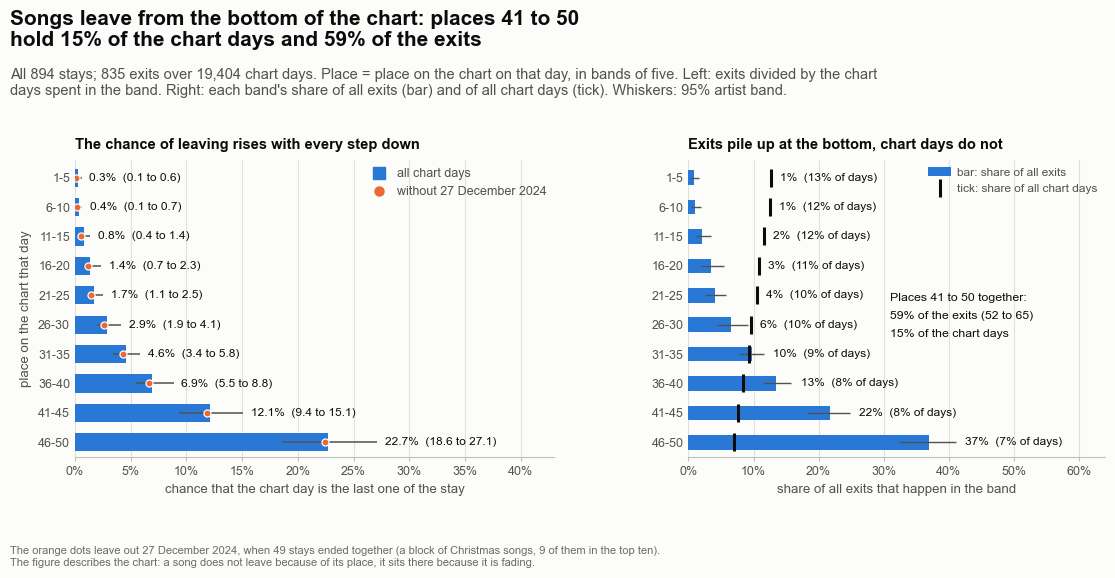

In [23]:
# Figure 09 - where on the chart the stays end
fig, (axa, axb) = make_fig(11.8, 5.9, 1, 2, left=1.0, right=0.5, bottom=0.95, wspace=0.3, width_ratios=[1.15, 1], panel_titles=True,
                           title=f"Songs leave from the bottom of the chart: places 41 to 50 hold {100 * FACTS['dz_bottom_days_share']:.0f}% of the chart days "
                                 f"and {100 * FACTS['dz_bottom_exit_share']:.0f}% of the exits",
                           subtitle=f"All {FACTS['n_songs']} stays; {FACTS['n_exits']} exits over {FACTS['n_days']:,} chart days. Place = place on the chart on that day, in bands of five. "
                                    "Left: exits divided by the chart days spent in the band. Right: each band's share of all exits (bar) and of all chart days (tick). Whiskers: 95% artist band.",
                           note_text=f"The orange dots leave out {FACTS['busy_text']}, when {FACTS['busy_exits']} stays ended together (a block of Christmas songs, {FACTS['busy_top10']} of them in the top ten). "
                                     "The figure describes the chart: a song does not leave because of its place, it sits there because it is fading.")
y = np.arange(N_BINS)
axa.barh(y, chance, height=0.62, color=style.BLUE)
axa.hlines(y, chance_low, chance_high, color=style.INK_2, linewidth=1.1, zorder=4)
axa.scatter(chance_x, y, s=26, color=style.ORANGE, edgecolor=style.SURFACE, linewidth=0.9, zorder=5)
for yi, value, low, high in zip(y, chance, chance_low, chance_high):
    direct_label(axa, high + 0.007, yi, f"{100 * value:.1f}%  ({100 * low:.1f} to {100 * high:.1f})", size=8.6, color=style.INK)
axa.set_yticks(y)
axa.set_yticklabels(PLACE_LABELS)
axa.set_ylim(N_BINS - 0.5, -0.6)
axa.set_xlim(0, 0.43)
axa.xaxis.set_major_formatter(SP.percent_axis)
axa.set_xlabel("chance that the chart day is the last one of the stay")
axa.set_ylabel("place on the chart that day")
style_axes(axa, grid="x", left_spine=False)
axa.tick_params(axis="y", length=0)
swatch_legend(axa, [("all chart days", style.BLUE), (f"without {FACTS['busy_text']}", style.ORANGE, "dot")], loc="upper right")
panel_title(axa, "The chance of leaving rises with every step down")

axb.barh(y, share_exits, height=0.5, color=style.BLUE)
axb.hlines(y, share_exits_low, share_exits_high, color=style.INK_2, linewidth=1.0, zorder=4)
(tick,) = axb.plot(share_days, y, marker="|", linestyle="none", color=style.INK, markersize=13, markeredgewidth=2.2, zorder=5)
for yi, a, high, b in zip(y, share_exits, share_exits_high, share_days):
    direct_label(axb, max(a, high, b) + 0.014, yi, f"{100 * a:.0f}%  ({100 * b:.0f}% of days)", size=8.6, color=style.INK)
direct_label(axb, 0.31, 4.1, "Places 41 to 50 together:", size=8.8, color=style.INK)
direct_label(axb, 0.31, 4.7, f"{100 * FACTS['dz_bottom_exit_share']:.0f}% of the exits ({100 * FACTS['dz_bottom_exit_share_low']:.0f} to {100 * FACTS['dz_bottom_exit_share_high']:.0f})", size=8.8, color=style.INK)
direct_label(axb, 0.31, 5.3, f"{100 * FACTS['dz_bottom_days_share']:.0f}% of the chart days", size=8.8, color=style.INK)
axb.set_yticks(y)
axb.set_yticklabels(PLACE_LABELS)
axb.set_ylim(N_BINS - 0.5, -0.6)
axb.set_xlim(0, 0.64)
axb.xaxis.set_major_formatter(SP.percent_axis)
axb.set_xlabel("share of all exits that happen in the band")
style_axes(axb, grid="x", left_spine=False)
axb.tick_params(axis="y", length=0)
axb.legend(handles=[Patch(facecolor=style.BLUE), tick], labels=["bar: share of all exits", "tick: share of all chart days"], loc="upper right", fontsize=8.6,
           handletextpad=0.5, borderaxespad=0.2)
panel_title(axb, "Exits pile up at the bottom, chart days do not")
save_fig(fig, "p6b_09_danger_zone", FIG_DIR)
plt.show()

**What to notice**

- Songs leave from the bottom. The last ten places hold 15% of the chart days and 59% of the exits (95% band 52% to 65%), 490 of the 835; places 46 to 50 alone hold 37% of the exits from 7% of the chart days. Places 1 to 10, a quarter of the chart days (25%), hold 2% of the exits (16, of which 9 are the block of 27 December 2024).
- In practical terms: a song in places 41 to 45 has a chance of about 12%, and a song in places 46 to 50 about 23%, that today is the last day of its stay. In places 21 to 25 the chance is 1.7%. These are rates of past stays, measured as they happened; they are not a forecast for a song of today.
- The place of the day is a symptom of a fading song, not a lever. A song does not leave because it sits at place 47; it sits at 47 because it is on its way down, and leaving is where that road ends. The table says how wide the door is at each place and nothing about what pushes a song to it. For this reason none of the models in this notebook uses the place on a later day: they use what is known when the song arrives (Section 6) or after its first three chart days (Section 8), and a later place would explain the end of a stay with the stay itself.

## Section 8 - How much of "who stays longer" can be read early?

Sections 4 to 7 describe how stays differ. This section asks how much of that difference could have been read at the time. Two moments are used: the **arrival day** (what is known the day a song first appears) and the **end of the third chart day** (what is known after three days of chart behaviour).

The measure is the **C-index**. Take any two songs for which it is known which one left first. A model that gives every song a risk score (a higher score means "leaves sooner") is right on that pair when the song that left first has the higher score. The C-index is the share of such pairs in which the model is right: 0.5 is a coin flip, 1.0 is perfect. It uses the unfinished stays too (a pair is used only when the order of leaving is known), and it needs no cut-off.

The scores come from a Cox model, which turns the inputs into one risk number for each song. Every score in this section is made by a model that has **never seen the song's artist**: the songs are split into 5 parts by artist, each part is scored by a model fitted on the other 4, and the whole procedure is repeated with 3 different splits. Without this, the model could score well by recognising artists.

Two limits belong here at the start. The Cox model gives each input one hazard ratio for the whole stay, and Section 6 found that five of the ten inputs act differently at different ages, so what follows is the one-ratio version; a model with age-varying ratios was not tried and might rank somewhat better. And this measures how much the early information carried about the order of exits in 2024 and 2025; it is not a promise about future songs.

### The ladder on the arrival day

**What this code is.** A ladder of what is known on the arrival day, with four sets of inputs added one at a time: the **release** (length, number of tracks, single or album, explicit, collaboration), the **timing** (weekday of the arrival and the days of history in the file), the **artist's record** (earlier chart days, songs, top-10 days, best place, usual popularity, on the chart the day before) and the **debut day** (place, popularity and the size of the album drop). For each step the code makes a risk score for every song with models that never saw the artist, computes the C-index for each of the 3 splits, puts a 95% band on it by resampling artists, and also computes the C-index of the same model on the songs it was fitted on.

**Why we need it.** A hazard ratio in Section 6 says an input goes with a higher hazard. It does not say how much of the difference between songs that is. The ladder says how much each set of inputs adds to the ability to put two songs in the order they left, and a step that adds nothing shows up as a gain of zero.

**What will happen.** For each of the four steps the code fits 15 Cox models (5 parts, 3 splits), each on the songs of other artists only, and scores the held-out part. It then finds the C-index among the 359,919 pairs of songs for which the order of leaving is known, the 95% band from the 1,000 artist resamples, and the gain of each step over the one above. One table is printed.

**Expected outcome.** A C-index near 0.55 for the release alone, almost no gain from timing or artist history, a jump to about 0.64 when the debut day is added, and a higher value (near 0.70) when the model is scored on the songs it was fitted on, which shows how much a model can flatter itself.

**Motive.** Put a number on how much of "who stays longer" can be read on the arrival day, scored the honest way.

In [24]:
LADDER_STEPS = [("Release", RELEASE_FEATURES, "single, length, explicit, collaboration"), ("+ Timing", TIMING_FEATURES, "weekday, days of history"),
                ("+ Artist history", ARTIST_FEATURES, "earlier chart record"), ("+ Debut day", DEBUT_FEATURES + ["log_drop"], "place, popularity, album drop")]
N_SPLITS, N_REPEATS, RIDGE = 5, 3, 1.0
PAIRS = concordance_pairs(T, E)
FACTS["n_pairs"] = int(len(PAIRS[0]))


def run_ladder(frame, time_, event, artists, pairs, boot_weights, steps, cumulative=True):
    """
    For each step (name, columns, description): out-of-fold scores, C-index of each split, C-index draws (mean over the splits), in-sample C-index.
    With cumulative=True every step adds its columns to those of the steps before it; otherwise every step lists all of its own columns.
    """
    out, so_far = [], []
    for name, columns, _ in steps:
        so_far = so_far + list(columns) if cumulative else list(columns)
        scores = cross_validated_risk(frame, time_, event, artists, so_far, LOG_COLUMNS, ridge=RIDGE, n_splits=N_SPLITS, n_repeats=N_REPEATS, seed=SEED)
        repeats = np.array([concordance(time_, event, scores[r]) for r in range(N_REPEATS)])
        draws = np.mean([weighted_concordance(pairs, scores[r], boot_weights) for r in range(N_REPEATS)], axis=0)
        in_sample = concordance(time_, event, CoxScorer(so_far, LOG_COLUMNS, RIDGE).fit(frame, time_, event).score(frame))
        out.append({"name": name, "inputs": len(so_far), "scores": scores, "repeats": repeats, "draws": draws, "in_sample": float(in_sample)})
    return out


ARRIVAL_RUNGS = run_ladder(STAYS, T, E, ARTISTS, PAIRS, W_BOOT, LADDER_STEPS)
OOF = {r["name"]: r["scores"] for r in ARRIVAL_RUNGS}
for k, rung in enumerate(ARRIVAL_RUNGS, start=1):
    low, high = np.nanpercentile(rung["draws"], [2.5, 97.5])
    FACTS[f"c{k}"], FACTS[f"c{k}_low"], FACTS[f"c{k}_high"] = float(rung["repeats"].mean()), float(low), float(high)
    FACTS[f"c{k}_min"], FACTS[f"c{k}_max"], FACTS[f"c{k}_in"] = float(rung["repeats"].min()), float(rung["repeats"].max()), rung["in_sample"]
    FACTS[f"c{k}_inputs"] = rung["inputs"]
    if k > 1:
        gain_draws = rung["draws"] - ARRIVAL_RUNGS[k - 2]["draws"]
        FACTS[f"gain{k}"] = float(rung["repeats"].mean() - ARRIVAL_RUNGS[k - 2]["repeats"].mean())
        FACTS[f"gain{k}_low"], FACTS[f"gain{k}_high"] = (float(v) for v in np.nanpercentile(gain_draws, [2.5, 97.5]))
FACTS["c_range_max"] = float(max(r["repeats"].max() - r["repeats"].min() for r in ARRIVAL_RUNGS))
FACTS["c4_wrong"] = 1.0 - FACTS["c4"]


def ladder_rows(view, rungs, descriptions, base_index=None):
    """Table rows of one ladder; the gain of a rung is taken over the rung given by `base_index` (default: the rung above)."""
    rows = []
    for k, (rung, description) in enumerate(zip(rungs, descriptions)):
        low, high = np.nanpercentile(rung["draws"], [2.5, 97.5])
        row = {"view": view, "step": rung["name"], "detail": description, "inputs": rung["inputs"], "c_index": float(rung["repeats"].mean()), "low": float(low), "high": float(high),
               "split_min": float(rung["repeats"].min()), "split_max": float(rung["repeats"].max()), "c_index_in_sample": rung["in_sample"], "gain": np.nan, "gain_low": np.nan, "gain_high": np.nan}
        base = k - 1 if base_index is None else base_index
        if base is not None and base >= 0 and base != k:
            gain_draws = rung["draws"] - rungs[base]["draws"]
            row["gain"] = float(rung["repeats"].mean() - rungs[base]["repeats"].mean())
            row["gain_low"], row["gain_high"] = (float(v) for v in np.nanpercentile(gain_draws, [2.5, 97.5]))
        rows.append(row)
    return rows


ARRIVAL_ROWS = ladder_rows("arrival day", ARRIVAL_RUNGS, [d for _, _, d in LADDER_STEPS])


def show_ladder(rows):
    shown = pd.DataFrame(rows)
    return pd.DataFrame({"step": shown["step"], "inputs": shown["inputs"], "C-index": shown["c_index"].map("{:.3f}".format), "95% band": [f"{a:.3f} to {b:.3f}" for a, b in zip(shown["low"], shown["high"])],
                         "range over the 3 splits": [f"{a:.3f} to {b:.3f}" for a, b in zip(shown["split_min"], shown["split_max"])], "same model on its own songs": shown["c_index_in_sample"].map("{:.3f}".format),
                         "gain": ["" if np.isnan(g) else f"{g:+.3f}  ({a:+.3f} to {b:+.3f})" for g, a, b in zip(shown["gain"], shown["gain_low"], shown["gain_high"])]}).set_index("step")


display(show_ladder(ARRIVAL_ROWS))

,inputs,C-index,95% band,range over the 3 splits,same model on its own songs,gain
step,,,,,,
Release,5,0.546,0.510 to 0.587,0.543 to 0.552,0.564,
+ Timing,13,0.555,0.523 to 0.593,0.544 to 0.561,0.593,+0.009 (-0.018 to +0.031)
+ Artist history,20,0.557,0.501 to 0.613,0.553 to 0.559,0.625,+0.002 (-0.034 to +0.036)
+ Debut day,23,0.636,0.593 to 0.691,0.630 to 0.640,0.696,+0.079 (+0.045 to +0.115)


**What to notice**

- Read the C-index as a share of pairs: of the 359,919 pairs of songs for which the order of leaving is known, a model that has only the release facts puts the earlier leaver first in 55% of them (95% band 51% to 59%); 50% would be a coin flip. Timing and artist history add +0.009 and +0.002 to the C-index, and the bands of both gains (-0.018 to +0.031 and -0.034 to +0.036) include zero: the data show no gain from either.
- The debut day is the step that matters. It adds +0.079 (+0.045 to +0.115, a band that stays clear of zero) and takes the C-index to 0.636: the model orders 64% of the pairs correctly. In Section 6 the debut place and the size of the album drop were the two inputs clearly tied to the hazard; here they are the step that changes the ranking.
- The honest figure is lower than the flattering one. Scored on the songs it was fitted on, the full model gets 0.696 against 0.636 on artists it had not seen, and the gap grows as inputs are added, from 0.018 on the release facts alone to 0.068 with the artist history (0.625 against 0.557). This is why every score here comes from models that never saw the artist.
- The three splits tell the same story: the C-index of a rung differs by no more than 0.017 between splits, much less than the size of the debut-day step.
- A C-index of 0.64 is a modest ranking, not a crystal ball: about 64% of the pairs right means 36% wrong. It tells how much the arrival day carries, and the answer is "some, nearly all of it from the debut day".

### The landmark: what is known after three chart days

**What this code is.** The same ladder after the third chart day. It uses the 599 songs (of 894) that had at least three chart days in a row at the start; for them the first three chart days exist. For these songs the clock starts at the third chart day (a song whose third day was its last has a clock of 1; moving the start of the clock by two days changes no order among the songs, so the C-index is not affected). Three scores are compared: the arrival-day information as before, the arrival-day information plus the first three chart days (the place on day 2, the move over the three days, the best place, the popularity on day 3 and its change), and the first three chart days alone. The method is the same: models that never saw the artist, 3 splits, artist resampling.

**Why we need it.** By the end of the third chart day a song has shown how it behaves: climbing or sliding, holding its popularity or losing it. Sections 3 and 6 found that most of the danger sits in the first three chart days, so these days may say more about what follows than the debut day does.

**What will happen.** The code fits the models on the 599 songs, prints a table like the one above, and finds the gain from adding the first three chart days to the arrival-day information, and what the arrival-day information adds on top of the first three days.

**Expected outcome.** A clear rise, from about 0.6 for the arrival-day information to about 0.75 once the first three chart days are included, with the first three days alone nearly as good as everything together.

**Motive.** Show how fast the picture of a stay sharpens once the song's own chart behaviour is seen. The two ladders rank different groups of songs (the second leaves out the songs that left within two chart days), so their numbers are not compared as if one model improved on the other.

In [25]:
LM = (STAYS["first_run_days"] >= 3).to_numpy()
FACTS["lm_songs"] = int(LM.sum())
T_LM, E_LM, FRAME_LM, ART_LM = T[LM] - 2, E[LM], STAYS[LM].reset_index(drop=True), ARTISTS[LM]
PAIRS_LM = concordance_pairs(T_LM, E_LM)
FACTS["n_pairs_lm"] = int(len(PAIRS_LM[0]))
ARRIVAL_COLUMNS = RELEASE_FEATURES + TIMING_FEATURES + ARTIST_FEATURES + DEBUT_FEATURES + ["log_drop"]
LM_STEPS = [("Arrival-day information", ARRIVAL_COLUMNS, "all four sets above"), ("+ first three chart days", ARRIVAL_COLUMNS + EARLY_FEATURES, "place, move, popularity"),
            ("First three chart days alone", EARLY_FEATURES, "without the arrival-day facts")]
LM_RUNGS = run_ladder(FRAME_LM, T_LM, E_LM, ART_LM, PAIRS_LM, W_BOOT[:, LM], LM_STEPS, cumulative=False)      # every rung lists all of its own columns
OOF_LM = {r["name"]: r["scores"] for r in LM_RUNGS}
LM_ROWS = ladder_rows("after three chart days", LM_RUNGS, [d for _, _, d in LM_STEPS])     # the second rung's gain is over the first: what the first three chart days add
for key in ("gain", "gain_low", "gain_high"):
    LM_ROWS[2][key] = np.nan                                                      # the third rung (three days alone) is not a step up from the second
for k, rung in enumerate(LM_RUNGS, start=1):
    low, high = np.nanpercentile(rung["draws"], [2.5, 97.5])
    FACTS[f"lm{k}"], FACTS[f"lm{k}_low"], FACTS[f"lm{k}_high"] = float(rung["repeats"].mean()), float(low), float(high)
    FACTS[f"lm{k}_in"], FACTS[f"lm{k}_min"], FACTS[f"lm{k}_max"] = rung["in_sample"], float(rung["repeats"].min()), float(rung["repeats"].max())
gain_lm = LM_RUNGS[1]["draws"] - LM_RUNGS[0]["draws"]                      # what the first three chart days add to the arrival-day information
extra_lm = LM_RUNGS[1]["draws"] - LM_RUNGS[2]["draws"]                     # what the arrival-day information adds to the first three days
FACTS["lm_gain"], FACTS["lm_gain_low"], FACTS["lm_gain_high"] = float(LM_RUNGS[1]["repeats"].mean() - LM_RUNGS[0]["repeats"].mean()), *(float(v) for v in np.nanpercentile(gain_lm, [2.5, 97.5]))
FACTS["lm_extra"], FACTS["lm_extra_low"], FACTS["lm_extra_high"] = float(LM_RUNGS[1]["repeats"].mean() - LM_RUNGS[2]["repeats"].mean()), *(float(v) for v in np.nanpercentile(extra_lm, [2.5, 97.5]))
display(show_ladder(LM_ROWS))

,inputs,C-index,95% band,range over the 3 splits,same model on its own songs,gain
step,,,,,,
Arrival-day information,23,0.614,0.579 to 0.663,0.609 to 0.623,0.685,
+ first three chart days,28,0.751,0.724 to 0.778,0.751 to 0.752,0.785,+0.137 (+0.098 to +0.173)
First three chart days alone,5,0.732,0.697 to 0.768,0.727 to 0.735,0.747,


### Figure 10: how much each step adds

**What this code is.** The drawing of Figure 10. The rows are the seven models of the two ladders: four on the arrival day and three after three chart days. The left panel shows the C-index of each (dot, with its 95% artist band as a line, and the same model on its own songs as a hollow circle). The right panel, on the same rows, shows what each step adds to the row above it, with its band.

**Why we need it.** A table of C-indices hides what matters, which is the size of each step next to its uncertainty. On the right the question "does this step add anything?" is answered by whether the band touches the zero line.

**What will happen.** Dots and bands on a common set of rows, with the value written beside each, a dotted line at 0.5 for the coin flip, and the picture saved as `p6b_10_ladder.png`.

**Expected outcome.** On the left, three dots that hardly move away from 0.55, a jump at the debut day, and a second ladder that climbs to about 0.75. On the right, bands that straddle zero for timing and artist history and stay clear of it for the debut day and for the first three chart days.

**Motive.** Show where the ability to rank stays comes from, and that it comes from the debut day and from what the song does in its first days.

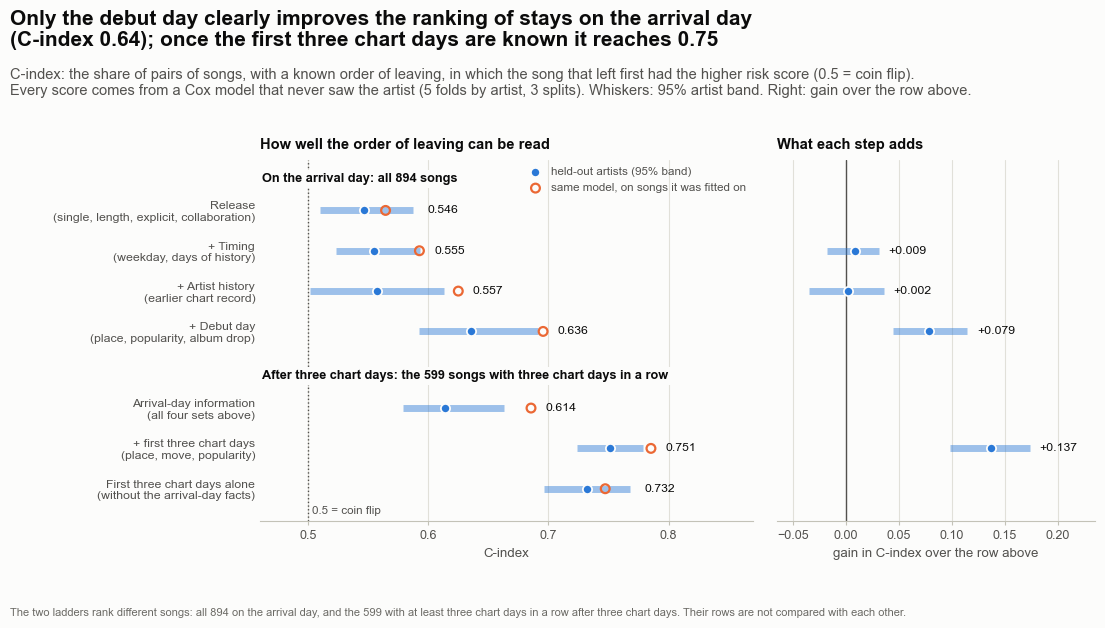

In [26]:
# Figure 10 - the two ladders
ROWS_ALL = ARRIVAL_ROWS + LM_ROWS
Y_ROWS = np.array([0, 1, 2, 3, 4.9, 5.9, 6.9])
ROW_LABELS = [f"{row['step']}\n({row['detail']})" for row in ROWS_ALL]
fig, (axa, axb) = make_fig(11.8, 6.4, 1, 2, left=2.85, right=0.6, bottom=0.95, wspace=0.06, width_ratios=[1.55, 1], panel_titles=True,
                           title=f"Only the debut day clearly improves the ranking of stays on the arrival day (C-index {FACTS['c4']:.2f}); once the first three chart days are known it reaches {FACTS['lm2']:.2f}",
                           subtitle="C-index: the share of pairs of songs, with a known order of leaving, in which the song that left first had the higher risk score (0.5 = coin flip). "
                                    "Every score comes from a Cox model that never saw the artist (5 folds by artist, 3 splits). Whiskers: 95% artist band. Right: gain over the row above.",
                           note_text=f"The two ladders rank different songs: all {FACTS['n_songs']} on the arrival day, and the {FACTS['lm_songs']} with at least three chart days in a row after three chart days. "
                                     "Their rows are not compared with each other.")
axa.axvline(0.5, color=style.INK_2, linewidth=1.0, linestyle=":", zorder=1)
direct_label(axa, 0.503, 7.45, "0.5 = coin flip", size=8.4, color=style.INK_2)
axa.hlines(Y_ROWS, [r["low"] for r in ROWS_ALL], [r["high"] for r in ROWS_ALL], color=style.BLUE, linewidth=5.0, alpha=0.45, zorder=2)
axa.scatter([r["c_index"] for r in ROWS_ALL], Y_ROWS, s=44, color=style.BLUE, edgecolor=style.SURFACE, linewidth=1.3, zorder=4, label="held-out artists (95% band)")
axa.scatter([r["c_index_in_sample"] for r in ROWS_ALL], Y_ROWS, s=40, facecolor="none", edgecolor=style.ORANGE, linewidth=1.6, zorder=3, label="same model, on songs it was fitted on")
for yi, row in zip(Y_ROWS, ROWS_ALL):
    direct_label(axa, max(row["high"], row["c_index_in_sample"]) + 0.012, yi, f"{row['c_index']:.3f}", size=8.8, color=style.INK)
HEADING = dict(facecolor=style.SURFACE, edgecolor="none", pad=2.0)                      # a plain box, so that the dotted line does not run through the words
axa.text(0.462, -0.78, f"On the arrival day: all {FACTS['n_songs']} songs", fontsize=9.2, fontweight="bold", color=style.INK, va="center", ha="left", bbox=HEADING, zorder=6)
axa.text(0.462, 4.1, f"After three chart days: the {FACTS['lm_songs']} songs with three chart days in a row", fontsize=9.2, fontweight="bold", color=style.INK, va="center", ha="left", bbox=HEADING, zorder=6)
axa.set_yticks(Y_ROWS)
axa.set_yticklabels(ROW_LABELS, fontsize=8.8)
axa.set_ylim(7.7, -1.25)
axa.set_xlim(0.46, 0.87)
axa.set_xticks([0.5, 0.6, 0.7, 0.8])
axa.set_xlabel("C-index")
style_axes(axa, grid="x", left_spine=False)
axa.tick_params(axis="y", length=0)
axa.legend(loc="upper right", frameon=False, fontsize=8.4, labelcolor=style.INK_2, handletextpad=0.3, borderaxespad=0.2)
panel_title(axa, "How well the order of leaving can be read")

axb.axvline(0.0, color=style.INK_2, linewidth=1.0, zorder=1)
for yi, row in zip(Y_ROWS, ROWS_ALL):
    if np.isnan(row["gain"]):
        continue
    axb.hlines(yi, row["gain_low"], row["gain_high"], color=style.BLUE, linewidth=5.0, alpha=0.45, zorder=2)
    axb.scatter([row["gain"]], [yi], s=44, color=style.BLUE, edgecolor=style.SURFACE, linewidth=1.3, zorder=4)
    direct_label(axb, row["gain_high"] + 0.009, yi, f"{row['gain']:+.3f}", size=8.8, color=style.INK)
axb.set_yticks(Y_ROWS)
axb.set_yticklabels([])
axb.set_ylim(7.7, -1.25)
axb.set_xlim(-0.065, 0.235)
axb.set_xticks([-0.05, 0.0, 0.05, 0.10, 0.15, 0.20])
axb.set_xlabel("gain in C-index over the row above")
style_axes(axb, grid="x", left_spine=False)
axb.tick_params(axis="y", length=0)
panel_title(axb, "What each step adds")
save_fig(fig, "p6b_10_ladder", FIG_DIR)
plt.show()
FACTS["lm_excluded"] = int(FACTS["n_songs"] - FACTS["lm_songs"])
FACTS["lm_excluded_quick"] = float((T[~LM] <= 2).mean())                 # share of the left-out songs whose whole stay was one or two chart days
FACTS["ins_gap1"] = float(FACTS["c1_in"] - FACTS["c1"])                 # fitted-songs score minus unseen-artist score, release facts only
FACTS["ins_gap3"] = float(FACTS["c3_in"] - FACTS["c3"])                 # the same with the artist history added
GAPS = [r["c_index_in_sample"] - r["c_index"] for r in ROWS_ALL]
FACTS["ins_gap_min"], FACTS["ins_gap_max"] = float(min(GAPS)), float(max(GAPS))

**What to notice**

- On the arrival day only one step moves the dot. The first three rows stay close to 0.55 with bands that overlap, the debut day takes the C-index to 0.636, and on the right only the band of the debut-day gain (+0.045 to +0.115) stays clear of the zero line.
- After three chart days the ranking is much sharper. Adding the first three chart days to the arrival-day facts lifts the C-index from 0.614 to 0.751, a gain of +0.137 (+0.098 to +0.173). The first three chart days alone reach 0.732. What the arrival-day facts add on top of them is +0.019 (-0.007 to +0.042), a band that includes zero: once a song's own first days are known, the data show nothing more to be gained from its release, timing, artist record or debut day.
- The hollow circles sit to the right of the dots in every row: the same model scored on the songs it was fitted on looks better by 0.01 to 0.07. This is the gap that scoring by artist removes.
- Two limits. The five early inputs are used together, so the notebook does not say which of them (the place on day 2, the move over three days, the best place, the popularity on day 3 or its change) carries the ranking. And the second ladder leaves out the 295 songs whose first unbroken run lasted only one or two chart days: nothing known after three chart days can rank those songs, and most of them (86%) were gone for good within two chart days.

### Risk thirds: what the ranking means for stays

**What this code is.** A translation of the C-index into stays. For each ladder the out-of-fold risk scores of the best model (the arrival-day model with the debut day; the model with the first three chart days) are averaged over the 3 splits and the songs are cut into three equal groups: the lowest-risk third, the middle third and the highest-risk third. For each group the code computes the survival curve with its 95% artist band, the median stay, and the share still on the chart after 7 and after 30 chart days. For the second ladder the curve is of the whole stay, among songs that reached three chart days in a row.

**Why we need it.** "C-index 0.64" is hard to picture. Three curves answer the question a person would ask: if songs are sorted by what was known when they arrived, how different do the stays of the top and the bottom third look?

**What will happen.** The code cuts the scores at their one-third and two-thirds points, runs the Kaplan-Meier estimate on each group, resamples artists 1,000 times for the bands, and prints a table with one row for each group.

**Expected outcome.** Three clearly separated curves on both ladders: a highest-risk third that is mostly gone within a few chart days and a lowest-risk third that keeps about a third of its songs past day 30 on the arrival day, and about half of them after three chart days.

**Motive.** Show in chart days, not in a score, what the ranking is worth, and that the groups it makes really differ.

In [27]:
THIRD_NAMES = ["lowest risk", "middle", "highest risk"]


def third_index(risk):
    """0 for the third of the songs with the lowest risk score, 1 for the middle third, 2 for the highest."""
    return np.digitize(risk, np.quantile(risk, [1 / 3, 2 / 3]))


def summarize_thirds(time_, event, artists, boot_weights, risk, shift, view):
    """
    Cut the songs into thirds of `risk` (0 = lowest risk) and describe the stays of each third. `time_ + shift` is the stay in chart days (the second ladder
    counts its clock from the third chart day), so that medians and shares are given in chart days of the stay.
    """
    third = third_index(risk)
    ages = np.arange(0, int(time_.max()) + 1)
    out = []
    for k, name in enumerate(THIRD_NAMES):
        mask = third == k
        curve = survival_grid(time_[mask], event[mask], ages)
        usable = boot_weights[:, mask].sum(axis=1) > 0
        draws = survival_grid(time_[mask], event[mask], ages, weights=boot_weights[:, mask])[usable]
        low, high = np.percentile(draws, [2.5, 97.5], axis=0)
        medians = median_stay(draws) + shift
        row = {"view": view, "third": name, "songs": int(mask.sum()), "artists": int(len(np.unique(artists[mask]))), "exits": int(event[mask].sum()),
               "median": float(median_stay(curve) + shift), "median_low": float(np.nanpercentile(medians, 2.5)), "median_high": float(np.nanpercentile(medians, 97.5))}
        for day in (7, 30):
            row[f"s{day}"], row[f"s{day}_low"], row[f"s{day}_high"] = float(curve[day - shift]), float(low[day - shift]), float(high[day - shift])
        row["curve"], row["low"], row["high"], row["stay_axis"] = curve, low, high, ages + shift
        out.append(row)
    return out


THIRDS_ARRIVAL = summarize_thirds(T, E, ARTISTS, W_BOOT, OOF["+ Debut day"].mean(axis=0), 0, "arrival day")
THIRDS_LM = summarize_thirds(T_LM, E_LM, ART_LM, W_BOOT[:, LM], OOF_LM["+ first three chart days"].mean(axis=0), 2, "after three chart days")
for prefix, rows in (("ra", THIRDS_ARRIVAL), ("rl", THIRDS_LM)):
    for k, row in enumerate(rows, start=1):
        for key in ("songs", "artists", "exits", "median", "median_low", "median_high", "s7", "s7_low", "s7_high", "s30", "s30_low", "s30_high"):
            FACTS[f"{prefix}{k}_{key}"] = row[key]
    FACTS[f"{prefix}_low_vs_high_median"] = float(rows[0]["median"] / rows[2]["median"])
    FACTS[f"{prefix}_s30_apart_12"] = int(rows[0]["s30_low"] > rows[1]["s30_high"])               # 1 when the 95% bands of the lowest and middle thirds do not overlap
    FACTS[f"{prefix}_s30_apart_23"] = int(rows[1]["s30_low"] > rows[2]["s30_high"])
    FACTS[f"{prefix}_s30_apart_13"] = int(rows[0]["s30_low"] > rows[2]["s30_high"])
THIRDS_TABLE = pd.DataFrame([{key: value for key, value in row.items() if key not in ("curve", "low", "high", "stay_axis")} for row in THIRDS_ARRIVAL + THIRDS_LM])
display(pd.DataFrame({"view": THIRDS_TABLE["view"], "third": THIRDS_TABLE["third"], "songs": THIRDS_TABLE["songs"], "artists": THIRDS_TABLE["artists"],
                      "median stay (95% band)": [f"{m:.0f}  ({a:.0f} to {b:.0f})" for m, a, b in zip(THIRDS_TABLE["median"], THIRDS_TABLE["median_low"], THIRDS_TABLE["median_high"])],
                      "still there after 7 chart days": [f"{100 * v:.0f}%  ({100 * a:.0f} to {100 * b:.0f})" for v, a, b in zip(THIRDS_TABLE["s7"], THIRDS_TABLE["s7_low"], THIRDS_TABLE["s7_high"])],
                      "still there after 30": [f"{100 * v:.0f}%  ({100 * a:.0f} to {100 * b:.0f})" for v, a, b in zip(THIRDS_TABLE["s30"], THIRDS_TABLE["s30_low"], THIRDS_TABLE["s30_high"])]}).set_index(["view", "third"]))

songs  artists median stay (95% band) still there after 7 chart days still there after 30
view                   third                                                                                                  
arrival day            lowest risk     298      141          12  (7 to 15)                58%  (49 to 66)      31%  (26 to 36)
                       middle          298      122            7  (5 to 9)                47%  (37 to 55)      20%  (15 to 26)
                       highest risk    298       65            3  (2 to 6)                25%  (12 to 36)        7%  (4 to 10)
after three chart days lowest risk     200      106         33  (27 to 34)                89%  (83 to 93)      51%  (45 to 58)
                       middle          199       78         14  (10 to 17)                70%  (59 to 79)      27%  (22 to 34)
                       highest risk    200       46            5  (4 to 6)                23%  (13 to 31)         2%  (0 to 4)

### Figure 11: the stays of the three risk groups

**What this code is.** The drawing of Figure 11. On the left, the survival curves of the three risk thirds on the arrival day, each with its 95% artist band and a label at its end that gives the median stay. On the right, the same for the songs that reached three chart days in a row, sorted by the model that also knows the first three chart days; there the curves start at 100% on chart day 2.

**Why we need it.** It shows what the C-index values mean for the length of stays, and how much sharper the groups become after three chart days.

**What will happen.** Six curves with shaded bands, darker for the lower-risk groups, labelled directly at their ends; the picture is saved as `p6b_11_risk_groups.png`.

**Expected outcome.** On the left, three curves that fan out from the start and stay apart, with a lowest-risk curve that ends near 30% at day 30 and a highest-risk curve that is near 7%. On the right, a wider fan: about half of the lowest-risk third is still there at day 30, almost none of the highest-risk third.

**Motive.** Turn the ranking into something a reader can see: how long the stays of each group last.

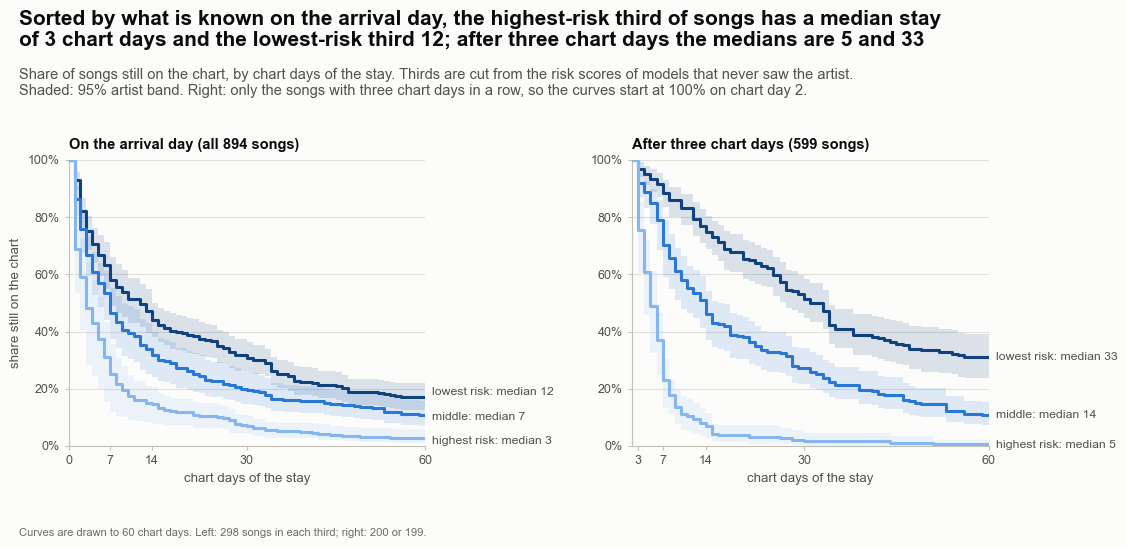

In [28]:
# Figure 11 - the curves of the risk thirds
RISK_COLORS = MP.step_colors(3)[::-1]                                  # dark = lowest risk (longest stays), light = highest risk
fig, (axa, axb) = make_fig(11.8, 5.6, 1, 2, left=0.85, right=1.75, bottom=0.9, wspace=0.58, panel_titles=True,
                           title=f"Sorted by what is known on the arrival day, the highest-risk third of songs has a median stay of {FACTS['ra3_median']:.0f} chart days and the lowest-risk third "
                                 f"{FACTS['ra1_median']:.0f}; after three chart days the medians are {FACTS['rl3_median']:.0f} and {FACTS['rl1_median']:.0f}",
                           subtitle="Share of songs still on the chart, by chart days of the stay. Thirds are cut from the risk scores of models that never saw the artist. Shaded: 95% artist band. "
                                    "Right: only the songs with three chart days in a row, so the curves start at 100% on chart day 2.",
                           note_text=f"Curves are drawn to 60 chart days. Left: {FACTS['ra1_songs']} songs in each third; right: {FACTS['rl1_songs']} or {FACTS['rl2_songs']}.")
for ax, rows, left_title in ((axa, THIRDS_ARRIVAL, f"On the arrival day (all {FACTS['n_songs']} songs)"), (axb, THIRDS_LM, f"After three chart days ({FACTS['lm_songs']} songs)")):
    curves = [{"label": f"{row['third']}: median {row['median']:.0f}", "ages": row["stay_axis"], "survival": row["curve"], "low": row["low"], "high": row["high"], "color": color}
              for row, color in zip(rows, RISK_COLORS)]
    SP.draw_survival_curves(ax, curves, x_max=60, label_gap=0.085, band_alpha=0.14)
    ax.set_xlabel("chart days of the stay")
    style_axes(ax, grid="y")
    panel_title(ax, left_title)
axa.set_xticks([0, 7, 14, 30, 60])
axb.set_xlim(2, 60)
axb.set_xticks([3, 7, 14, 30, 60])
axa.set_ylabel("share still on the chart")
save_fig(fig, "p6b_11_risk_groups", FIG_DIR)
plt.show()

**What to notice**

- The groups really differ. On the arrival day the lowest-risk third has a median stay of 12 chart days (95% band 7 to 15), the middle third 7 and the highest-risk third 3 (2 to 6); "risk" here always means the risk of leaving. After 30 chart days 31%, 20% and 7% of the songs are still on the chart, and of the highest-risk third only 25% are there after a week. The highest-risk third is clearly apart from the other two: its band at day 30 (4% to 10%) does not come near theirs. The lowest and the middle third are closer: their bands at day 30 meet at about 26%.
- This is what a C-index of 0.64 looks like. It sorts songs into groups with clearly different stays; it does not say what any single song will do, and inside every third the stays run from one chart day to months.
- The highest-risk third is made of few artists: 298 songs from 65 artists, against 298 songs from 141 artists in the lowest. A few artists bring many songs on one day, and the songs of one artist share their fate, which is why the band of the median of that third, 2 to 6, is wide for a median this small.
- After three chart days the groups fan out further. The medians are 33, 14 and 5 chart days, and 51%, 27% and 2% of the songs are still on the chart after 30. A song in the highest-risk third after three chart days almost never reaches day 30 (0% to 4%), while about half of the lowest-risk third does.
- These are descriptions of past stays, sorted by scores that models made without having seen the artist, cut at the thirds of this one sample. They are not a rule for choosing songs, and the label of a third says how songs like it behaved in 2024 and 2025, nothing about why.

## Section 9 - Do the findings survive other reasonable choices?

Every result so far rests on choices that could have been made differently: how long an absence must be to end a stay (7 snapshot days), which songs are included, whether one block of songs that left together is counted as it happened. This section changes the choices, one at a time, and refits the hazard model of Section 6 each time. A finding that depends on one choice is not a finding about the chart.

Nine runs are made. Five change the **gap rule** (1, 3, 7 as used, 14 and 30 snapshot days of absence to end a stay). Four change the **songs**: the first half and the second half of the file, the stays that ended on 27 December 2024 treated as unfinished (their chart days stay in, but their last day is not counted as an exit), and the ten artists with the most songs left out. Everything else, the inputs and the way the intervals are made, stays as in Section 6.

**What this code is.** The nine runs. A function takes the gap rule, the group of songs to keep and whether to treat the 27 December 2024 block as unfinished, rebuilds the stays and chart days under that rule, fits the day-by-day model with the same ten inputs and the artist-aware intervals, and also computes the Kaplan-Meier share still on the chart after 30 chart days and the median stay. The hazard ratios kept for each run are the four debut-place bands, the album drop and the single.

**Why we need it.** Section 6 gives one set of ratios for one set of choices. The question is whether the ones that matter (debut place, album drop) keep their size and direction, and whether the ones that did not (the single) stay unclear, when the choices change.

**What will happen.** The code fits nine models, one after the other. The run with the gap rule of 7 and all songs is the model of Section 6 itself, and the code checks that it reproduces its ratios. It prints a table of the nine runs and sets the facts: how many of the debut-place intervals stay clear of 1, the range of the ratios of the album drop and of the single, and how the 30-day share moves with the gap rule.

**Expected outcome.** All debut-place ratios above 1 and clear of 1 in every run, an album drop above 1 in every run and clear of 1 in most, a single that never separates from 1, and a share still on the chart after 30 days that moves with the gap rule.

**Motive.** Test the main findings against the choices that were the most open to doubt.

In [29]:
HALF = N_SNAPSHOTS // 2
ENTRY = STAYS["entry_snapshot"].to_numpy()
TOP_ARTISTS = STAYS.groupby("primary_artist").size().sort_values(ascending=False, kind="stable").index[:10]
ALL_SONGS = np.ones(len(STAYS), dtype=bool)
TOP_SONGS = STAYS["primary_artist"].isin(TOP_ARTISTS).to_numpy()
FACTS["top_artists_songs"] = int(TOP_SONGS.sum())
FACTS["half_snapshot"] = int(HALF)
RUNS = [("gap1", "Gap rule 1", "any absence ends the stay", 1, ALL_SONGS, False),
        ("gap3", "Gap rule 3", "3 snapshot days away end it", 3, ALL_SONGS, False),
        ("gap7", f"Gap rule {GAP}", "the rule used here", GAP, ALL_SONGS, False),
        ("gap14", "Gap rule 14", "14 snapshot days away end it", 14, ALL_SONGS, False),
        ("gap30", "Gap rule 30", "30 snapshot days away end it", 30, ALL_SONGS, False),
        ("first", "First half of the file", f"songs that arrived before snapshot day {HALF}", GAP, ENTRY < HALF, False),
        ("second", "Second half of the file", f"songs that arrived from snapshot day {HALF}", GAP, ENTRY >= HALF, False),
        ("block", f"Block of {FACTS['busy_text']}", "its stays counted as unfinished", GAP, ALL_SONGS, True),
        ("top10", "Without 10 big artists", f"the 10 artists with most songs out, {FACTS['top_artists_songs']} songs", GAP, ~TOP_SONGS, False)]
STRESS_INPUTS = {"Debut place 11 to 20": "b2", "Debut place 21 to 30": "b3", "Debut place 31 to 40": "b4", "Debut place 41 to 50": "b5", "Album drop": "drop", "Single": "single"}
MIN_EVENTS_LAST_WINDOW = 5
FACTS["min_events_last_window"] = MIN_EVENTS_LAST_WINDOW


def stress_run(gap, keep, block_unfinished):
    """Rebuild the stays under `gap`, keep the songs in `keep`, refit the Section 6 model and describe the run."""
    lives = (LIVES if gap == GAP else build_lives(CHART, STAYS["track_id"], N_SNAPSHOTS, gap=gap)).copy()
    if block_unfinished:                                                  # the stays whose last chart day is the busy exit day count as unfinished
        lives.loc[(lives["last_snapshot"] == BUSY) & lives["exit_seen"], "exit_seen"] = False
    days = person_days(CHART, lives)
    rows = pd.Index(STAYS["track_id"]).get_indexer(days["track_id"])
    use = keep[rows]
    rows, days = rows[use], days[use]
    edges = list(AGE_EDGES)
    while days.loc[days["age"] > edges[-2], "event"].sum() < MIN_EVENTS_LAST_WINDOW and len(edges) > 4:
        edges = edges[:-2] + [edges[-1]]                                  # too few exits in the last window: merge it into the one before
    base = window_columns(days["age"].to_numpy(), edges)
    design = np.column_stack([base.to_numpy(), SONG_X.to_numpy()[rows]])
    fit = fit_cloglog(days["event"].to_numpy(), design, clusters=ARTISTS[rows])
    hr_, lo_, hi_ = fit.hazard_ratios()
    names = list(base.columns) + INPUT_ORDER
    T_r, E_r = lives["stay"].to_numpy(dtype=float)[keep], lives["exit_seen"].to_numpy(dtype=bool)[keep]
    curve = survival_grid(T_r, E_r, np.arange(0, int(T_r.max()) + 1))
    out = {"songs": int(keep.sum()), "artists": int(len(np.unique(ARTISTS[keep]))), "exits": int(E_r.sum()), "censored": int((~E_r).sum()), "converged": bool(fit.converged),
           "windows": len(base.columns), "s30": float(curve[30]), "median": float(median_stay(curve)), "inputs": {}}
    for name, key in STRESS_INPUTS.items():
        i = names.index(name)
        out["inputs"][key] = (float(hr_[i]), float(lo_[i]), float(hi_[i]), float(fit.p_values()[i]))
    out["all_hr"] = {name: float(hr_[names.index(name)]) for name in INPUT_ORDER}
    return out


RESULTS = {}
for key, label, detail, gap, keep, block in RUNS:
    RESULTS[key] = stress_run(gap, keep, block)
    assert RESULTS[key]["converged"], f"the run {label} did not converge"
# the run with the gap rule of 7 and all songs is the model of Section 6: its ratios must be the same
FACTS["st_main_gap"] = float(max(abs(RESULTS["gap7"]["all_hr"][name] - float(hr[MAIN_NAMES.index(name)])) for name in INPUT_ORDER))
assert FACTS["st_main_gap"] < 1e-8, "the stress run with the usual choices does not reproduce the model of Section 6"
FACTS["st_runs"] = len(RUNS)
rows_out = []
for k, (key, label, detail, gap, keep, block) in enumerate(RUNS, start=1):
    res = RESULTS[key]
    for k_name, short in STRESS_INPUTS.items():
        value, low, high, p = res["inputs"][short]
        rows_out.append({"run": key, "run_label": label, "run_detail": detail, "songs": res["songs"], "artists": res["artists"], "exits": res["exits"], "censored": res["censored"],
                         "share_after_30_days": res["s30"], "median_stay": res["median"], "input": k_name, "hazard_ratio": value, "low": low, "high": high, "p": p})
        FACTS[f"st{k}_{short}"], FACTS[f"st{k}_{short}_low"], FACTS[f"st{k}_{short}_high"] = value, low, high
    FACTS[f"st{k}_songs"], FACTS[f"st{k}_artists"], FACTS[f"st{k}_exits"] = res["songs"], res["artists"], res["exits"]
    FACTS[f"st{k}_s30"], FACTS[f"st{k}_median"], FACTS[f"st{k}_windows"] = res["s30"], res["median"], res["windows"]
STRESS_TABLE = pd.DataFrame(rows_out)
display(pd.DataFrame({"run": [f"{label}" for _, label, *_ in RUNS], "songs": [RESULTS[k]["songs"] for k, *_ in RUNS], "exits": [RESULTS[k]["exits"] for k, *_ in RUNS],
                      "30-day share": [f"{100 * RESULTS[k]['s30']:.0f}%" for k, *_ in RUNS], "median": [f"{RESULTS[k]['median']:.0f}" for k, *_ in RUNS],
                      "debut 31-40": [f"{RESULTS[k]['inputs']['b4'][0]:.2f}  ({RESULTS[k]['inputs']['b4'][1]:.2f} to {RESULTS[k]['inputs']['b4'][2]:.2f})" for k, *_ in RUNS],
                      "album drop": [f"{RESULTS[k]['inputs']['drop'][0]:.2f}  ({RESULTS[k]['inputs']['drop'][1]:.2f} to {RESULTS[k]['inputs']['drop'][2]:.2f})" for k, *_ in RUNS],
                      "single": [f"{RESULTS[k]['inputs']['single'][0]:.2f}  ({RESULTS[k]['inputs']['single'][1]:.2f} to {RESULTS[k]['inputs']['single'][2]:.2f})" for k, *_ in RUNS]}).set_index("run"))

# ---- the findings, counted
debut_cells = [RESULTS[k]["inputs"][s] for k, *_ in RUNS for s in ("b2", "b3", "b4", "b5")]
FACTS["st_debut_total"] = len(debut_cells)
FACTS["st_debut_above_one"] = int(sum(v > 1 for v, lo, hi, p in debut_cells))
FACTS["st_debut_clear"] = int(sum(lo > 1 for v, lo, hi, p in debut_cells))
FACTS["st_debut_min"], FACTS["st_debut_max"] = float(min(v for v, *_ in debut_cells)), float(max(v for v, *_ in debut_cells))
drop_cells = [RESULTS[k]["inputs"]["drop"] for k, *_ in RUNS]
FACTS["st_drop_above_one"] = int(sum(v > 1 for v, lo, hi, p in drop_cells))
FACTS["st_drop_clear"] = int(sum(lo > 1 for v, lo, hi, p in drop_cells))
FACTS["st_drop_min"], FACTS["st_drop_max"] = float(min(v for v, *_ in drop_cells)), float(max(v for v, *_ in drop_cells))
unclear = [label for (k, label, *_), (v, lo, hi, p) in zip(RUNS, drop_cells) if lo <= 1]
FACTS["st_drop_unclear"] = ", ".join(unclear).lower() if unclear else "none"
single_cells = [RESULTS[k]["inputs"]["single"] for k, *_ in RUNS]
FACTS["st_single_clear"] = int(sum(hi < 1 or lo > 1 for v, lo, hi, p in single_cells))
FACTS["st_single_min"], FACTS["st_single_max"] = float(min(v for v, *_ in single_cells)), float(max(v for v, *_ in single_cells))
FACTS["st_single_low_min"], FACTS["st_single_high_max"] = float(min(lo for v, lo, hi, p in single_cells)), float(max(hi for v, lo, hi, p in single_cells))
gap_runs = [RESULTS[k]["s30"] for k in ("gap1", "gap3", "gap7", "gap14", "gap30")]
FACTS["st_s30_gap_min"], FACTS["st_s30_gap_max"] = float(min(gap_runs)), float(max(gap_runs))
subset_runs = [RESULTS[k]["s30"] for k in ("first", "second", "block", "top10")]
FACTS["st_s30_subset_min"], FACTS["st_s30_subset_max"] = float(min(subset_runs)), float(max(subset_runs))
FACTS["st_merged_runs"] = int(sum(RESULTS[k]["windows"] < 9 for k, *_ in RUNS))
FACTS["st_merged_names"] = ", ".join(label.lower() for k, label, *_ in RUNS if RESULTS[k]["windows"] < 9) or "none"
print(f"all {FACTS['st_debut_total']} debut-place ratios: smallest {FACTS['st_debut_min']:.2f}, largest {FACTS['st_debut_max']:.2f}; {FACTS['st_debut_clear']} of {FACTS['st_debut_total']} intervals exclude 1")
print(f"album drop: {FACTS['st_drop_min']:.2f} to {FACTS['st_drop_max']:.2f}, interval excludes 1 in {FACTS['st_drop_clear']} of {FACTS['st_runs']}; not clear in: {FACTS['st_drop_unclear']}")
print(f"single: {FACTS['st_single_min']:.2f} to {FACTS['st_single_max']:.2f}, interval clear of 1 in {FACTS['st_single_clear']} runs; runs with merged last age window: {FACTS['st_merged_runs']}")

,songs,exits,30-day share,median,debut 31-40,album drop,single
run,,,,,,,
Gap rule 1,894,860,13%,5,4.34 (3.06 to 6.15),1.32 (1.08 to 1.60),0.87 (0.67 to 1.14)
Gap rule 3,894,852,17%,6,4.09 (2.98 to 5.62),1.39 (1.14 to 1.70),0.95 (0.75 to 1.19)
Gap rule 7,894,835,19%,6,4.22 (3.05 to 5.83),1.48 (1.20 to 1.83),1.01 (0.81 to 1.26)
Gap rule 14,894,825,20%,7,4.17 (2.97 to 5.86),1.54 (1.24 to 1.91),1.01 (0.80 to 1.27)
Gap rule 30,894,792,22%,7,3.94 (2.83 to 5.48),1.59 (1.29 to 1.96),1.04 (0.83 to 1.32)
First half of the file,513,509,18%,6,3.42 (2.28 to 5.12),1.40 (1.05 to 1.87),1.11 (0.85 to 1.46)
Second half of the file,381,326,21%,7,6.48 (4.20 to 10.00),1.58 (1.24 to 2.01),0.99 (0.63 to 1.57)
Block of 27 December 2024,894,786,21%,7,4.09 (2.94 to 5.67),1.54 (1.24 to 1.90),1.15 (0.89 to 1.48)
Without 10 big artists,545,505,24%,7,3.50 (2.43 to 5.05),1.54 (1.18 to 2.00),1.08 (0.85 to 1.36)


all 36 debut-place ratios: smallest 1.72, largest 6.48; 36 of 36 intervals exclude 1
album drop: 1.32 to 1.59, interval excludes 1 in 9 of 9; not clear in: none
single: 0.87 to 1.15, interval clear of 1 in 0 runs; runs with merged last age window: 1


### Figure 12: the nine runs side by side

**What this code is.** The drawing of Figure 12. One row for each of the nine runs, in four panels that share the rows: the hazard ratio of a debut at places 31 to 40 against a top-10 debut, the hazard ratio of the album drop (for one standard deviation more), the hazard ratio of the single against the album track, and the share of songs still on the chart after 30 chart days. A dot is filled when the 95% artist-aware interval of the ratio is clear of 1 and hollow when it includes 1.

**Why we need it.** The table is exact but hides the pattern. Side by side, the reader sees at once which ratios stay on the same side of 1 whatever is changed, and where the intervals widen.

**What will happen.** Ratios on a log scale with a line at 1, intervals as bars, the value next to each, the run used in the rest of the notebook shaded, and the picture saved as `p6b_12_stress_tests.png`.

**Expected outcome.** In the first panel nine filled dots, all well to the right of 1; in the second nine filled dots a little right of 1; in the third nine hollow dots around 1; and in the last a share that rises with the gap rule.

**Motive.** Show that the main findings do not hang on one choice, and say where the size of an effect does change.

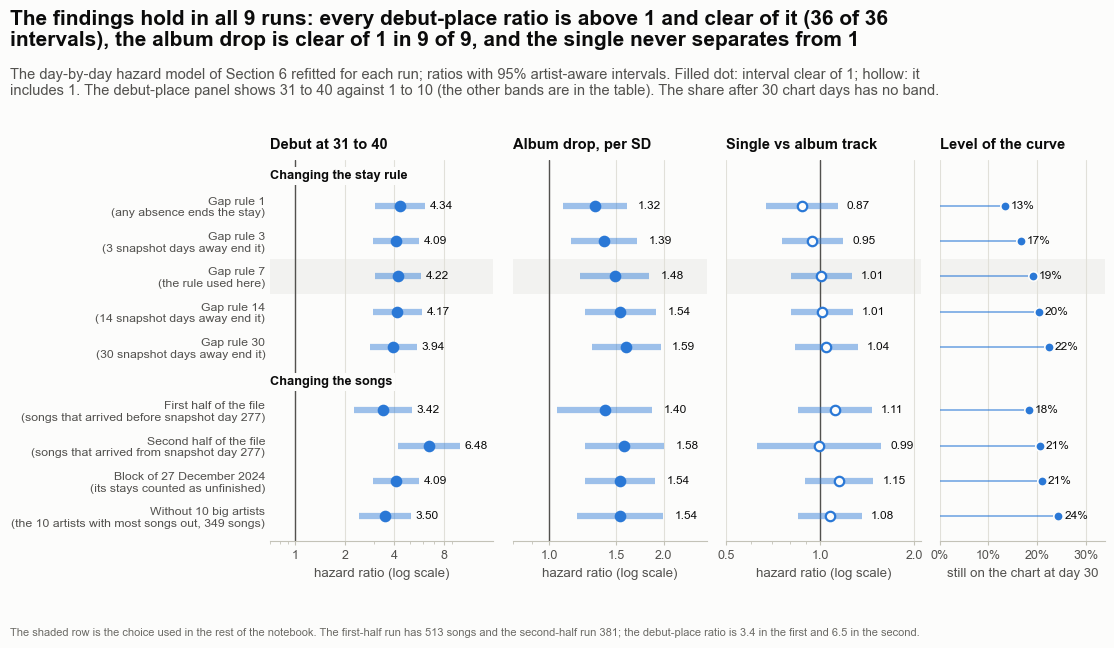

In [30]:
# Figure 12 - the nine runs
Y_RUN = np.array([0, 1, 2, 3, 4, 5.8, 6.8, 7.8, 8.8])
RUN_LABELS = [f"{label}\n({detail})" for _, label, detail, *_ in RUNS]
fig, axes = make_fig(11.8, 6.6, 1, 4, left=2.95, right=0.5, bottom=0.95, wspace=0.1, width_ratios=[1.15, 1, 1, 0.85], panel_titles=True,
                     title=f"The findings hold in all {FACTS['st_runs']} runs: every debut-place ratio is above 1 and clear of it ({FACTS['st_debut_clear']} of {FACTS['st_debut_total']} intervals), "
                           f"the album drop is clear of 1 in {FACTS['st_drop_clear']} of {FACTS['st_runs']}, and the single never separates from 1",
                     subtitle="The day-by-day hazard model of Section 6 refitted for each run; ratios with 95% artist-aware intervals. Filled dot: interval clear of 1; hollow: it includes 1. "
                              "The debut-place panel shows 31 to 40 against 1 to 10 (the other bands are in the table). The share after 30 chart days has no band.",
                     note_text=f"The shaded row is the choice used in the rest of the notebook. The first-half run has {FACTS['st6_songs']} songs and the second-half run {FACTS['st7_songs']}; "
                               f"the debut-place ratio is {FACTS['st6_b4']:.1f} in the first and {FACTS['st7_b4']:.1f} in the second.")
panels = [("b4", "Debut at 31 to 40", "hazard ratio (log scale)", (0.7, 16), [1, 2, 4, 8]),
          ("drop", "Album drop, per SD", "hazard ratio (log scale)", (0.8, 2.6), [1, 1.5, 2]),
          ("single", "Single vs album track", "hazard ratio (log scale)", (0.5, 2.1), [0.5, 1, 2])]
for ax, (short, title, xlabel, xlim, ticks) in zip(axes[:3], panels):
    ax.axvline(1.0, color=style.INK_2, linewidth=1.0, zorder=1)
    ax.axhspan(2 - 0.5, 2 + 0.5, color=style.AXIS, alpha=0.16, zorder=0)
    for yi, (key, *_) in zip(Y_RUN, RUNS):
        value, low, high, p = RESULTS[key]["inputs"][short]
        ax.hlines(yi, low, high, color=style.BLUE, linewidth=4.5, alpha=0.45, zorder=2)
        ax.scatter([value], [yi], s=46, facecolor=style.BLUE if low > 1 or high < 1 else style.SURFACE, edgecolor=style.BLUE, linewidth=1.6, zorder=4)
        direct_label(ax, high * 1.07, yi, f"{value:.2f}", size=8.6, color=style.INK)
    ax.set_xscale("log")
    ax.set_xlim(*xlim)
    ax.set_xticks(ticks)
    ax.xaxis.set_major_formatter(ScalarFormatter())
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_xlabel(xlabel)
    panel_title(ax, title)
ax = axes[3]
ax.axhspan(2 - 0.5, 2 + 0.5, color=style.AXIS, alpha=0.16, zorder=0)
for yi, (key, *_) in zip(Y_RUN, RUNS):
    ax.hlines(yi, 0, RESULTS[key]["s30"], color=style.BLUE, linewidth=1.4, alpha=0.55, zorder=2)
    ax.scatter([RESULTS[key]["s30"]], [yi], s=46, color=style.BLUE, edgecolor=style.SURFACE, linewidth=1.2, zorder=4)
    direct_label(ax, RESULTS[key]["s30"] + 0.012, yi, f"{100 * RESULTS[key]['s30']:.0f}%", size=8.6, color=style.INK)
ax.set_xlim(0, 0.34)
ax.xaxis.set_major_formatter(SP.percent_axis)
ax.set_xlabel("still on the chart at day 30")
panel_title(ax, "Level of the curve")
HEADING = dict(facecolor=style.SURFACE, edgecolor="none", pad=2.0)
for ax in axes:
    ax.set_ylim(9.5, -1.3)
    style_axes(ax, grid="x", left_spine=False)
    ax.tick_params(axis="y", length=0)
    ax.set_yticks(Y_RUN)
    ax.set_yticklabels(RUN_LABELS if ax is axes[0] else [], fontsize=8.8)
axes[0].text(0.0, -0.85, "Changing the stay rule", transform=axes[0].get_yaxis_transform(), fontsize=9.2, fontweight="bold", color=style.INK, va="center", ha="left", bbox=HEADING, zorder=6)
axes[0].text(0.0, 5.0, "Changing the songs", transform=axes[0].get_yaxis_transform(), fontsize=9.2, fontweight="bold", color=style.INK, va="center", ha="left", bbox=HEADING, zorder=6)
save_fig(fig, "p6b_12_stress_tests", FIG_DIR)
plt.show()

**What to notice**

- The debut place survives every change. All 36 debut-place ratios (four bands in each of the 9 runs) are above 1, 36 of the 36 intervals are clear of 1, and the smallest ratio is 1.72. The size moves more than the direction. For a debut at 31 to 40 it runs from 3.4 in the first half of the file (2.3 to 5.1) to 6.5 in the second half (4.2 to 10.0), two intervals that overlap only in their outer parts. That hints that the debut place mattered more later in the file; this section does not test it, and one comparison of two halves is a hint, not a finding.
- The album drop keeps its direction and its clearness: 1.32 to 1.59 times the hazard for one standard deviation more album drop, with an interval clear of 1 in 9 of the 9 runs. It grows with the gap rule, from 1.32 when any absence ends the stay to 1.59 when 30 days away are needed; a short rule splits a returning song into two stays, and the pattern suggests that the album drop goes with leaving for good more than with leaving for a few days. That reading is a guess.
- The single never separates from 1: its ratio runs from 0.87 to 1.15 and its interval includes 1 in every run (0 of 9 are clear of it). It falls on both sides of 1, which fits no effect, but the intervals reach from 0.63 to 1.57, so a small effect in either direction cannot be ruled out.
- The gap rule moves the level of the curve, not the findings. The share still on the chart after 30 chart days goes from 13% when any absence ends the stay to 22% when 30 days away are needed, because a song that disappears for a few days and returns is one stay under a long rule and two under a short one. The other four runs fall between 18% and 24%. The conclusions of this notebook are about ratios and order; the exact level of the curve depends on the rule, as Section 3 said.
- Counting the 27 December 2024 block as unfinished changes little: the debut-place ratio at 31 to 40 is 4.09 against 4.22 in the main run, and the album drop 1.54 against 1.48. Leaving out the ten artists with the most songs (349 songs) gives 3.50 and 1.54: the results do not rest on a few large artists.
- What the nine runs do not vary: the inputs, the one-ratio form of the model (Section 6 found that five of the ten inputs act differently by age), the definition of an exit, and the way intervals treat artists (not days). In 1 run (second half of the file) the last age window held fewer than 5 exits and was merged with the window before it.

## Section 10 - Saving the results, and what Phase 6B adds up to

**What this code is.** The saving cell. It collects the result tables of the notebook, puts each in the shape other tools like (one row per song, one row per point of a curve, one row per input), and writes them to `reports/` as CSV files with UTF-8 and a byte-order mark, so that Excel on Windows shows the text correctly. It also writes `p6b_facts.json`, which holds every number quoted in the sentences of this notebook.

**Why we need it.** Later phases need these numbers without running the notebook again: the dashboard of Phase 7 and the Power BI report of Phase 8 read the CSV files, and the paper of Phase 9 quotes the facts file. A file written once by the notebook also cannot disagree with the notebook.

**What will happen.** The code builds twelve tables (the song table gets two extra columns, the risk third of each song on the arrival day and after three chart days), writes each one, reads it back to check that it has the same shape, checks that all 12 charts are in `reports/figures/`, and writes the facts file. It prints the files with their numbers of rows and columns.

**Expected outcome.** A list of thirteen files: twelve CSV files and the facts file. The song file has 894 rows, one for each song; the curve file is the longest.

**Motive.** Keep the results outside the notebook, in files that other tools can read and that have been checked.

In [31]:
REPORT_DIR = paths.reports_dir


def as_frame(table):
    """Some of the tables of the earlier sections are lists of rows; the saving code works on data frames."""
    return table if isinstance(table, pd.DataFrame) else pd.DataFrame(table)


# ---- one row per song, with the risk thirds of Section 8
STAY_COLUMNS = ["track_id", "track_label", "primary_artist", "entry_date", "entry_snapshot", "entry_rank", "debut_band", "drop_size", "total_tracks", "is_single", "is_explicit", "is_collab",
                "duration_min", "entry_pop", "artist_prior_slot_days", "artist_prior_mean_pop", "artist_on_chart_prev_day", "stay", "exit_seen", "last_snapshot", "short_breaks",
                "first_run_days", "returned"]
SONGS_OUT = STAYS[STAY_COLUMNS].copy()
SONGS_OUT["debut_band"] = SONGS_OUT["debut_band"].astype(str)
SONGS_OUT["risk_third_arrival"] = pd.Series(THIRD_NAMES)[third_index(OOF["+ Debut day"].mean(axis=0))].to_numpy()
SONGS_OUT["risk_third_after_3_days"] = pd.Series([None] * len(SONGS_OUT), dtype=object)
SONGS_OUT.loc[LM, "risk_third_after_3_days"] = pd.Series(THIRD_NAMES)[third_index(OOF_LM["+ first three chart days"].mean(axis=0))].to_numpy()

# ---- the five groupings: the group rows with the log-rank test of the split and the RMST difference against the reference group
TEST_COLUMNS = {"p_songs": "log_rank_p_songs_as_independent", "p_artists": "log_rank_p_artist_aware", "p_holm": "log_rank_p_artist_aware_holm"}
CONTRAST_COLUMNS = {"reference": "reference_group", "difference": "chart_days_of_first_30_difference", "low": "difference_low", "high": "difference_high"}
GROUP_OUT = (as_frame(GROUP_ROWS).merge(as_frame(TESTS)[["split"] + list(TEST_COLUMNS)].rename(columns=TEST_COLUMNS), on="split", how="left")
             .merge(as_frame(CONTRAST_TABLE)[["split", "group"] + list(CONTRAST_COLUMNS)].rename(columns=CONTRAST_COLUMNS), on=["split", "group"], how="left"))
assert len(GROUP_OUT) == len(as_frame(GROUP_ROWS)), "the merges changed the number of group rows"

# ---- the hazard ratios with the test of the block each input belongs to; the effects by age with the test of equal effects
BLOCK_OF = {column: block for block, columns in BLOCKS for column in columns}
RATIOS_OUT = (as_frame(HR_TABLE).rename(columns={"p": "p_coefficient"}).assign(block=lambda d: d["input"].map(BLOCK_OF))
              .merge(as_frame(BLOCK_TABLE).rename(columns={"input": "block", "F": "block_F", "df1": "block_df1", "df2": "block_df2", "p": "block_p", "p_holm": "block_p_holm"}), on="block", how="left"))
EFFECTS_OUT = as_frame(AGE_TABLE).merge(as_frame(PH_TABLE).rename(columns={"input": "block", "F": "equal_effects_F", "df1": "equal_effects_df1", "df2": "equal_effects_df2", "p": "equal_effects_p", "p_holm": "equal_effects_p_holm"}),
                              on="block", how="left")
assert len(RATIOS_OUT) == len(as_frame(HR_TABLE)) and len(EFFECTS_OUT) == len(as_frame(AGE_TABLE)), "the merges changed the number of rows"

# ---- the danger zone with the check that leaves out the busiest exit day
DANGER_OUT = as_frame(DANGER_TABLE).assign(chance_last_day_without_busiest_day=chance_x, without_busiest_day_low=chance_x_low, without_busiest_day_high=chance_x_high)
LADDER_OUT = pd.DataFrame(ARRIVAL_ROWS + LM_ROWS)

TABLES = {"p6b_stays": SONGS_OUT, "p6b_survival_curves": as_frame(CURVE_ROWS), "p6b_hazard_by_age": as_frame(HAZARD_TABLE), "p6b_further_stay": as_frame(FURTHER_TABLE), "p6b_group_comparison": GROUP_OUT,
          "p6b_debut_alone": as_frame(DEBUT_TABLE), "p6b_hazard_ratios": RATIOS_OUT, "p6b_effects_by_age": EFFECTS_OUT, "p6b_danger_zone": DANGER_OUT, "p6b_ladder": LADDER_OUT,
          "p6b_risk_thirds": THIRDS_TABLE, "p6b_stress_tests": STRESS_TABLE}
FACTS["n_tables_saved"] = len(TABLES)
FACTS["n_figures_saved"] = len(sorted(FIG_DIR.glob("p6b_*.png")))
written = []
for name, frame in TABLES.items():
    path = REPORT_DIR / f"{name}.csv"
    save_table(frame, path)
    back = pd.read_csv(path, encoding="utf-8-sig")
    assert back.shape == frame.shape, f"{name}: the file read back has the shape {back.shape}, not {frame.shape}"
    written.append({"file": f"{name}.csv", "rows": len(frame), "columns": frame.shape[1]})
assert FACTS["n_figures_saved"] == 12, f"expected 12 charts in {FIG_DIR}, found {FACTS['n_figures_saved']}"
FACTS.save(REPORT_DIR / "p6b_facts.json")
written.append({"file": "p6b_facts.json", "rows": len(FACTS), "columns": 2})
display(pd.DataFrame(written).set_index("file"))
print(f"{FACTS['n_tables_saved']} tables and the facts file written to {REPORT_DIR}; {FACTS['n_figures_saved']} charts are in {FIG_DIR}.")

,rows,columns
file,,
p6b_stays.csv,894,25
p6b_survival_curves.csv,1815,6
p6b_hazard_by_age.csv,9,9
p6b_further_stay.csv,6,5
p6b_group_comparison.csv,14,20
p6b_debut_alone.csv,5,17
p6b_hazard_ratios.csv,14,13
p6b_effects_by_age.csv,42,12
p6b_danger_zone.csv,10,21


12 tables and the facts file written to D:\INTERNSHIP PROJECTS\UNIFIED MENTOR WORK\PROJECT_2\United States Top 50 Playlist Performance and Song Popularity Trend Analysis Project\atlantic-top50-analytics\reports; 12 charts are in D:\INTERNSHIP PROJECTS\UNIFIED MENTOR WORK\PROJECT_2\United States Top 50 Playlist Performance and Song Popularity Trend Analysis Project\atlantic-top50-analytics\reports\figures.


### What Phase 6B adds up to

**How long songs stay.** Of the 894 songs that arrived after the first snapshot day, 83% are still on the chart after one chart day, 43% after a week and 19% after 30 chart days (95% band 16% to 24%); the median first stay is 6 chart days. The chance that a chart day is the last one of a stay falls steeply with the age of the stay, from 17% on the first chart day to 0.5% after day 120, so no single average chance describes a stay. The mean of the raw stays (21.7 chart days) is far above the median because a small number of songs stay for months (the longest stay is 446 chart days).

**What goes with a short stay.** Three groupings separate the stays after the artist-aware tests and the Holm adjustment: the debut place (p = 0.004), the number of songs the artist brought on the same day (p = 0.009) and the release type (p = 0.013); explicit content and collaboration do not. When the inputs are held against each other, two remain. A debut at places 31 to 40 goes with about 4.2 times the hazard of a top-10 debut (95% interval 3.1 to 5.8), and one standard deviation more album drop (a drop 3.8 times as large) with about 1.5 times (1.2 to 1.8). The longer stays of singles in Section 4 are not there once the other inputs are held fixed: the ratio of the single in the model is 1.01 (0.81 to 1.26).

**Where and how early it shows.** A chart day in places 1 to 5 is the last one of its stay 0.3% of the time, in places 46 to 50 23%, and 59% of all exits happen in places 41 to 50, which hold 15% of the chart days. The arrival day carries some information about the order in which songs leave (cross-validated C-index 0.64, and the debut day is the only step that clearly adds to the release facts), and the first three chart days carry much more (0.75). Sorted by the arrival-day model, the median stay of the lowest-risk third is 12 chart days and that of the highest-risk third 3.

**How firm it is.** The intervals resample artists, not songs, so that the songs of one artist stay together. Nine runs that change the gap rule or the songs keep every debut-place ratio above 1 and clear of it (36 of 36 intervals), keep the album drop clear of 1 in 9 of 9 runs, and leave the single unclear in all of them. The level of the curve moves with the gap rule (13% to 22% after 30 chart days), and the size of the debut-place ratio differs between the first and the second half of the file.

**What it does not say.**

- Every result is an association among these 894 songs between 18 May 2024 and 27 November 2025. Nothing here shows what would happen to a song if its debut place or its album drop were changed.
- The one-ratio model is a simplification: 5 of the 10 inputs act differently at different ages (Section 6), most of all the debut place, whose effect sits in the first chart days. A model with age-varying ratios was not tried.
- The 50 songs that were already on the chart on the first day are not in the analysis, and the 59 stays that had not ended when the file ends are counted as "at least this long".
- The artist bands treat artists as independent, but songs of different artists can leave on the same day: 49 stays ended on 27 December 2024. Section 7 shows that the place pattern survives without that day, and Section 9 that the debut-place and album-drop ratios hardly move when that block is counted as unfinished; the other sections keep it.
- A C-index of 0.64 measures how much the arrival day carried in this file. It is not a promise about future songs.

**Where this leads.** Phase 6C groups songs and artists by the shape of their first month on the chart and asks whether the groups are stable and whether they line up with the survival results above. Phase 7 puts these results into the dashboard and Phase 8 into the Power BI report; the files written in this section are what they read.